<a href="https://colab.research.google.com/github/Deathbot545/Gold_Oil_Cost_of_Living_COMPLETE_Coursework_Notebook/blob/main/Gold_Oil_Cost_of_Living_COMPLETE_Coursework_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gold, Oil and the Cost of Living in Sri Lanka
### Integrated data science coursework notebook | Tasks 1–5

**Research theme:** How international gold and oil-market conditions, currency movements and fuel prices relate to Sri Lankan inflation; and whether observable financial indicators help predict the *next available* Brent crude-oil return.

**Notebook status:** This edition preserves the original 73 numbered analytical cells and their previously saved outputs. It adds a full problem definition, stakeholder/success criteria, dataset provenance, methodological explanations, data-quality and baseline audits, interpretation, responsible recommendations and a report-building guide. **New audit cells have not been executed in this copy**, and the original analysis has not been independently re-executed here. Run the notebook in Google Colab and check outputs before relying on any results in a report.

> **Two related analytical strands, not one combined predictive model:** (A) a **monthly Sri Lankan inflation association analysis** using currency/oil/market data and statistical regressions; (B) a **daily international Brent-return forecasting benchmark** using OVX, GVZ, WTI and Brent information. The daily prediction model does **not** predict Sri Lankan inflation directly.

## Navigation / coursework mapping

| Requirement | Where it is demonstrated | Evidence and limitations |
|---|---|---|
| **Task 1 — Problem & stakeholders** | This introduction and Task 1 section | Business question, analytical scope, stakeholders, hypotheses and measurable success criteria |
| **Task 2 — Data & preparation** | Original Cells **1–43**, **60–63** plus new data-quality audits | FRED/CBSL/DCS/CPC sources, data ingestion, transformations, validation, missingness, deduplication, outliers and engineered features |
| **Task 3 — Exploration & visualisation** | Original Cells **44–47**, **55–59**, **61–63** | Time trends, association plots, correlation, lag exploration, residuals, return distribution and data-quality visuals |
| **Task 4 — Modelling & assessment** | Original Cells **48–54**, **62–70** plus stronger-baseline diagnostic | OLS/HAC monthly regression; chronological split, Ridge/Random Forest, MAE/RMSE/R², naive and zero-return comparisons |
| **Task 5 — Recommendations** | Revised Cells **71–73** plus report appendix | Prioritised stakeholder actions with feasibility, limitations, trade-offs and evaluation methods |

**Interpretation rule:** Dataset record count, statistical association, model fit and policy relevance are separate claims. A large raw file does not imply a large complete-case model sample; association does not establish causation; and lower RMSE than a weak benchmark does not automatically make a forecast commercially useful.

## Task 1 — Business problem, research questions and measurable goals

### 1.1 Business context and rationale

Sri Lankan households, businesses and policymakers face exposure to exchange-rate depreciation, international energy prices and inflation. Gold prices are also relevant to household saving and portfolio-risk discussions. Publicly available monthly Sri Lankan statistics and daily financial-market indicators permit a reproducible investigation, while differing time frequencies and breaks in index bases require careful preparation.

**Overarching question:** *What do international commodity markets and USD/LKR movements reveal about recent Sri Lankan cost-of-living pressures, and how useful are related market signals for monitoring near-term oil-price risk?*

The project addresses this question through **two explicitly separate objectives**:

1. **Monthly explanation/association:** Investigate how changes in the USD/LKR exchange rate and international Brent prices, including exploratory time lags, are associated with month-on-month CCPI/NCPI inflation. Explore gold and WTI as contextual indicators. **Outcome:** monthly inflation measures. **Method:** exploratory statistics and OLS with heteroskedasticity/autocorrelation-consistent (HAC) errors; sensitivity and diagnostic tests.
2. **Daily risk-prediction benchmark:** Predict the percentage change in Brent at its *next available observation* from current and lagged Brent/WTI prices and OVX/GVZ indices. **Outcome:** next-observation Brent return, in percent. **Method:** chronological train/validation/test partition; naive baseline, Ridge, Random Forest; additional zero-return and training-mean benchmarks.

The monthly part is mainly **explanatory and exploratory**, whereas the daily model is **predictive**. They share the oil-risk theme but should not be conflated in the report.

### 1.2 Stakeholders and decisions

| Stakeholder | Decision they may improve | Appropriate use of this project |
|---|---|---|
| **Central Bank / economic researchers** | Track exchange-rate, oil-price and inflation co-movements | Monitoring and scenario discussion; not proof of monetary-policy causality |
| **Fuel importers and logistics businesses** | Assess exposure to sudden fuel-cost increases | Dashboards, stress tests, procurement risk limits and review triggers |
| **Small and medium-sized importers** | Budget for USD-linked inputs | Conservative contingency planning; **not** next-day trade timing from a weak model |
| **Households / financial educators** | Understand inflation and commodity-related risks | Financial literacy and diversified risk-awareness; no guaranteed gold hedge |

### 1.3 Research propositions (questions, not confirmed truths)

- **P1:** USD/LKR changes and oil-price changes may have measurable, period-dependent associations with monthly Sri Lankan inflation.
- **P2:** Delayed oil-price changes may align differently with inflation than simultaneous changes. A lag selected after looking at data is **exploratory** and must not be presented as a proved pass-through interval.
- **P3:** Ridge or a nonlinear Random Forest may improve daily Brent return RMSE compared with persistence; stronger fixed-zero / training-mean baselines are also important because financial returns are difficult to predict.

### 1.4 Success criteria / KPIs

| Measurement | Target / evaluation rule |
|---|---|
| Raw dataset size | At least **10,000 records** in the preserved full-history FRED join, with explicit missingness disclosure |
| Data integrity | Document duplicates, invalid dates, missing values, parsing checks, source versions and the final complete-case sample |
| EDA completeness | At least **five substantively different visuals** with described axes, timeframes, findings and limitations |
| Statistical interpretation | Report coefficients, HAC intervals or p-values, sample sizes, diagnostics and sensitivity to the 2022 crisis period |
| Predictive assessment | Use a time-ordered holdout and report **MAE, RMSE and R²**, including a zero-return forecast and persistence benchmark |
| Operational decision gate | Do **not** recommend automated trades or precise oil-return timing unless performance exceeds realistic baselines consistently across periods and risk/cost tests |
| Reproducibility | Preserve raw sources, export cleaned tables, save diagnostics and state notebook environment, source dates and execution date |

**Scope boundary:** This project measures historical associations and forecast benchmarks. It does not estimate an identified causal effect, build a production system, quantify hedging profits, prove how households should allocate assets, or directly forecast future Sri Lankan inflation from the ML model.

## Reproducibility and execution notes — read before running Cell 1

**Runtime:** This notebook was developed for **Google Colab** and uses Google Drive at `/content/drive/MyDrive/Gold_Oil_Cost_of_Living`. Some cells use Colab-specific mounting; the downloaded notebook alone does **not** contain the source CSV/XLSX/PDF files in that Drive folder.

**Required locally staged inputs:** `OVXCLS.csv`, `GVZCLS.csv`, `DCOILBRENTEU.csv`, `DCOILWTICO.csv` (FRED series exports), and `IF_Buying_Selling_Exchange_Rates.xlsx` (CBSL workbook, expected worksheet `2005-2026`). Other sources are downloaded by notebook code from DataHub, DCS and CPC. Ensure you have the legitimate original sources and check whether official websites have changed file names, PDF layouts, API response formats or the expected month ranges.

**Suggested run process:** (1) create/populate the Google Drive folder; (2) open in Colab; (3) run top-to-bottom with a connected runtime; (4) inspect source and parsing assertions; (5) review the new baseline/boundary audits; (6) export the final results and save a new executed copy. Avoid silently dropping an assertion or inserting invented values to make an updated source fit a hard-coded expected date range.

**Important time caveat:** The preserved results are a **historical snapshot** whose full-history market source ends on **2026-11-12**; the monthly integrated dataset ends **2026-09**. Fresh downloads may yield different sizes, dates and model metrics. The notebook does not guarantee a successful new online execution in this environment. Keep the original source files and record your own actual download and run dates for assessment.

**Method/software stack:** Python, `pandas`/`numpy` for ingestion and transformations, `requests` for official downloads/APIs, `pdfplumber` for parsing released reports, `matplotlib` for EDA, `statsmodels` for OLS/HAC and statistical diagnostics, `scikit-learn` for Ridge/Random Forest modelling. The principal raw market file is ~0.28 MB, so **pandas is appropriate**. Distributed tools such as Spark would be sensible for substantially larger, streaming or multi-node workloads, but are not necessary or honestly demonstrated here.

**Data ethics and uncertainty:** These are aggregate public economic/market series, not personal records. However, **source updates, differing series coverage, re-basing of inflation indices, publication delays, crisis-period structural breaks, and unmodelled policy effects** can bias interpretation. Avoid causal or investment-performance claims.

# Task 2 — Data acquisition, governance and preprocessing

### Source inventory and provenance

| Dataset | Publisher/source visible in code | Measurement/frequency | Usage |
|---|---|---|---|
| OVX (`OVXCLS`), GVZ (`GVZCLS`) | FRED series CSVs supplied in Drive | Daily quoted market volatility-index levels, with gaps | Oil/gold uncertainty proxies in ML and EDA |
| Brent (`DCOILBRENTEU`), WTI (`DCOILWTICO`) | FRED series CSVs supplied in Drive | Daily oil reference prices, USD/barrel, with gaps | Monthly aggregations, lag relationships and Brent return ML |
| Gold price | DataHub Core Gold Prices CSV download | Monthly USD per troy ounce | Trend/association context, not a direct ML feature |
| USD/LKR | Central Bank of Sri Lanka historical workbook | Daily recorded buying/selling prices | Monthly exchange-rate context; documented correction log |
| CCPI / NCPI | Sri Lanka Department of Census and Statistics, official PDFs | Monthly price indices (different index-base vintages) | CCPI and NCPI inflation analysis; base reconciliation considered |
| CPC fuel price revisions | Ceylon Petroleum Corporation API | Price revision events, transformed for daily inspection | Domestic fuel context; not included as a predictor in the 11-feature Brent ML model |

**Granularity is important:** The whole-history FRED join, research-period FRED subset, monthly inflation analysis and final ML feature table are **different datasets with different valid row counts**. A 10,661-row original source should never be reported as 10,661 complete observations across all four market variables.

### Transformation and validation choices

- **Parse and sort dates** to establish joins and temporal order. Check duplicate dates and exact duplicates rather than assuming one row per date.
- **Preserve raw information:** Outer join the four market sources and save full history **before** filtering to the research period. Missing observations are not fabricated with arbitrary price or volatility values.
- **Address missingness by analysis purpose:** Inspect per-column missing rates in full history, then use observed overlaps / complete cases for model inputs. This reduces sample size substantially and favours the more recent period when all four indicators exist.
- **PDF/API extraction:** Validate period coverage and numeric fields; save source/extraction/adjustment files so mistakes can be traced. Re-based CCPI/NCPI index *levels* should not simply be concatenated without defensible linkage.
- **Outliers:** Investigate extreme Brent returns; retain plausible actual market movements because arbitrary trimming would understate risk. Do not equate volatility shocks with input errors.
- **Features:** Convert daily series to percentage changes on their own available observation dates, merge available indicators, create past-return lags, build an explicitly future target and remove rows with undefined engineered values.
- **Encoding/scaling:** No categorical explanatory variables are used in the final 11 ML features; therefore one-hot encoding is unnecessary. Ridge uses `StandardScaler` fitted inside a pipeline on training rows only. Forest does not need feature scaling.

**Selection bias:** Complete-case feature availability is *not random over time*: OVX and GVZ start later than the oil price series. Findings from the 2,922-row ML sample mainly represent 2015 onward, not the entire 1986–2026 history.

Cell 1 — Import Libraries and Install Dependencies

In [ ]:
%pip install -q pdfplumber
import pandas as pd
import numpy as np
import requests
import io
import os
import matplotlib.pyplot as plt

from datetime import datetime

print("Libraries imported successfully!")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
Libraries imported successfully!


Cell 2 — Connect Google Drive and Create Project Folder

In [ ]:
from google.colab import drive
import os

# Connect Google Drive
drive.mount('/content/drive')

# Create project folder
PROJECT_FOLDER = "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"

os.makedirs(PROJECT_FOLDER, exist_ok=True)

print("Google Drive connected!")
print("Project folder:", PROJECT_FOLDER)

Mounted at /content/drive
Google Drive connected!
Project folder: /content/drive/MyDrive/Gold_Oil_Cost_of_Living


Cell 3 — Verify International Market Data Files

In [ ]:
import os

required_files = [
    "OVXCLS.csv",
    "GVZCLS.csv",
    "DCOILBRENTEU.csv",
    "DCOILWTICO.csv"
]

for filename in required_files:

    filepath = os.path.join(PROJECT_FOLDER, filename)

    if os.path.exists(filepath):
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")

FOUND: OVXCLS.csv
FOUND: GVZCLS.csv
FOUND: DCOILBRENTEU.csv
FOUND: DCOILWTICO.csv


Cell 4 — Define the Research Period

In [ ]:
START_DATE = "2015-01-01"
END_DATE = "2026-11-14"

print("Research period:", START_DATE, "to", END_DATE)

Research period: 2015-01-01 to 2026-11-14


Cell 5 — Load International Market Datasets

In [ ]:
import pandas as pd
import os

ovx_raw = pd.read_csv(
    os.path.join(PROJECT_FOLDER, "OVXCLS.csv")
)

gvz_raw = pd.read_csv(
    os.path.join(PROJECT_FOLDER, "GVZCLS.csv")
)

brent_raw = pd.read_csv(
    os.path.join(PROJECT_FOLDER, "DCOILBRENTEU.csv")
)

wti_raw = pd.read_csv(
    os.path.join(PROJECT_FOLDER, "DCOILWTICO.csv")
)

print("All four datasets loaded successfully!")

All four datasets loaded successfully!


Cell 6 — Inspect Raw Market Data

In [ ]:
datasets_raw = {
    "OVX": ovx_raw,
    "GVZ": gvz_raw,
    "Brent": brent_raw,
    "WTI": wti_raw
}

for name, df in datasets_raw.items():

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("Columns:", df.columns.tolist())
    print("Rows:", len(df))

    display(df.head(5))


OVX
Columns: ['observation_date', 'OVXCLS']
Rows: 3095


,observation_date,OVXCLS
0,2015-01-02,54.25
1,2015-01-05,57.67
2,2015-01-06,56.45
3,2015-01-07,53.25
4,2015-01-08,50.96



GVZ
Columns: ['observation_date', 'GVZCLS']
Rows: 4813


,observation_date,GVZCLS
0,2008-06-03,22.89
1,2008-06-04,22.69
2,2008-06-05,22.78
3,2008-06-06,23.60
4,2008-06-09,24.47



Brent
Columns: ['observation_date', 'DCOILBRENTEU']
Rows: 10301


,observation_date,DCOILBRENTEU
0,1987-05-20,18.63
1,1987-05-21,18.45
2,1987-05-22,18.55
3,1987-05-25,18.60
4,1987-05-26,18.63



WTI
Columns: ['observation_date', 'DCOILWTICO']
Rows: 10660


,observation_date,DCOILWTICO
0,1986-01-02,25.56
1,1986-01-03,26.00
2,1986-01-06,26.53
3,1986-01-07,25.85
4,1986-01-08,25.87


Cell 7 — Check Market Data Coverage

In [ ]:
for name, df in datasets_raw.items():

    date_column = df.columns[0]

    dates = pd.to_datetime(
        df[date_column],
        errors="coerce"
    )

    print(f"\n{name}")
    print("-" * 35)
    print("First observation:", dates.min())
    print("Last observation:", dates.max())
    print("Invalid dates:", dates.isna().sum())


OVX
-----------------------------------
First observation: 2015-01-02 00:00:00
Last observation: 2026-11-12 00:00:00
Invalid dates: 0

GVZ
-----------------------------------
First observation: 2008-06-03 00:00:00
Last observation: 2026-11-12 00:00:00
Invalid dates: 0

Brent
-----------------------------------
First observation: 1987-05-20 00:00:00
Last observation: 2026-11-11 00:00:00
Invalid dates: 0

WTI
-----------------------------------
First observation: 1986-01-02 00:00:00
Last observation: 2026-11-11 00:00:00
Invalid dates: 0


Cell 8 — Clean International Market Data

In [ ]:
def clean_fred_data(df, value_column):

    cleaned = df.copy()

    # Standardise column names
    cleaned.columns = ["Date", value_column]

    # Convert dates
    cleaned["Date"] = pd.to_datetime(
        cleaned["Date"],
        errors="coerce"
    )

    # Convert values to numeric
    cleaned[value_column] = pd.to_numeric(
        cleaned[value_column].replace(".", np.nan),
        errors="coerce"
    )

    # Remove invalid dates
    cleaned = cleaned.dropna(subset=["Date"])

    # Sort chronologically
    cleaned = cleaned.sort_values("Date")

    # Remove duplicate dates
    cleaned = cleaned.drop_duplicates(
        subset=["Date"],
        keep="last"
    )

    return cleaned.reset_index(drop=True)


ovx = clean_fred_data(ovx_raw, "OVXCLS")
gvz = clean_fred_data(gvz_raw, "GVZCLS")
brent = clean_fred_data(brent_raw, "DCOILBRENTEU")
wti = clean_fred_data(wti_raw, "DCOILWTICO")

print("All datasets cleaned successfully!")

All datasets cleaned successfully!


## Cell 9 — Combine International Market Datasets

### Purpose
Combine the cleaned OVX, GVZ, Brent and WTI datasets into one
historical market dataset.

### Method
An outer join on the Date column is used to preserve all dates
available in the individual source datasets.

Missing observations are retained as NaN rather than being
automatically removed.

### Historical dataset preservation
A separate copy named `market_data_full_history` is created
before applying the research-period filter.

This preserves the complete historical dataset for the
coursework dataset-size requirement, while allowing the
subsequent research analysis to use its existing date range.

In [ ]:

market_data = (
    ovx
    .merge(gvz, on="Date", how="outer")
    .merge(brent, on="Date", how="outer")
    .merge(wti, on="Date", how="outer")
    .sort_values("Date")
    .reset_index(drop=True)
)

# Preserve the complete historical dataset BEFORE filtering.
# Later cells will continue using market_data as before.
market_data_full_history = market_data.copy()

print("Market dataset created!")
print("Full historical rows:", len(market_data_full_history))
print("Columns:", market_data_full_history.columns.tolist())

print("\nHistorical coverage:")
print("First date:", market_data_full_history["Date"].min())
print("Last date:", market_data_full_history["Date"].max())

print("\nDuplicate dates:", market_data_full_history["Date"].duplicated().sum())

display(market_data_full_history.head(10))


Market dataset created!
Full historical rows: 10661
Columns: ['Date', 'OVXCLS', 'GVZCLS', 'DCOILBRENTEU', 'DCOILWTICO']

Historical coverage:
First date: 1986-01-02 00:00:00
Last date: 2026-11-12 00:00:00

Duplicate dates: 0


,Date,OVXCLS,GVZCLS,DCOILBRENTEU,DCOILWTICO
0,1986-01-02,NaN,NaN,NaN,25.56
1,1986-01-03,NaN,NaN,NaN,26.00
2,1986-01-06,NaN,NaN,NaN,26.53
3,1986-01-07,NaN,NaN,NaN,25.85
4,1986-01-08,NaN,NaN,NaN,25.87
5,1986-01-09,NaN,NaN,NaN,26.03
6,1986-01-10,NaN,NaN,NaN,25.65
7,1986-01-13,NaN,NaN,NaN,25.08
8,1986-01-14,NaN,NaN,NaN,24.97
9,1986-01-15,NaN,NaN,NaN,25.18


Cell 10 — Analyse Missing Market Data

In [ ]:
missing_summary = pd.DataFrame({
    "Missing_Count": market_data.isna().sum(),
    "Missing_Percentage": (
        market_data.isna().mean() * 100
    ).round(2)
})

display(missing_summary)

,Missing_Count,Missing_Percentage
Date,0,0.00
OVXCLS,7675,71.99
GVZCLS,6017,56.44
DCOILBRENTEU,1533,14.38
DCOILWTICO,1118,10.49


Cell 11 — Filter Market Data to Research Period

In [ ]:
market_data = market_data[
    (market_data["Date"] >= START_DATE) &
    (market_data["Date"] <= END_DATE)
].copy()

market_data = market_data.sort_values("Date").reset_index(drop=True)

print("Research dataset:", market_data.shape)

display(market_data.head())
display(market_data.tail())

Research dataset: (3096, 5)


,Date,OVXCLS,GVZCLS,DCOILBRENTEU,DCOILWTICO
0,2015-01-01,NaN,NaN,NaN,NaN
1,2015-01-02,54.25,20.23,55.38,52.72
2,2015-01-05,57.67,21.26,51.08,50.05
3,2015-01-06,56.45,20.78,50.12,47.98
4,2015-01-07,53.25,20.35,49.06,48.69


,Date,OVXCLS,GVZCLS,DCOILBRENTEU,DCOILWTICO
3091,2026-11-06,58.29,25.97,97.83,94.37
3092,2026-11-09,57.20,24.93,91.03,90.40
3093,2026-11-10,53.10,24.43,90.16,89.62
3094,2026-11-11,51.26,24.21,92.14,89.62
3095,2026-11-12,51.72,25.91,NaN,NaN


## Cell 12 — Save International Market Datasets

### Purpose
Save both the complete historical market dataset and the
filtered research dataset.

### Output files

1. `international_market_data_full_history.csv`
   - Preserves all available dates from the outer-joined
     market datasets.
   - Used to document the full historical dataset for the
     coursework dataset-size requirement.

2. `international_market_data.csv`
   - Contains the existing filtered research period.
   - Continues to be used by subsequent analysis cells.

### Verification
Both files are reloaded to verify their record counts,
and duplicate dates are checked before confirming that
the datasets have been saved successfully.

In [ ]:

# ------------------------------------------------------------
# SAVE FULL HISTORICAL DATASET
# ------------------------------------------------------------

full_history_file = os.path.join(
    PROJECT_FOLDER,
    "international_market_data_full_history.csv"
)

market_data_full_history.to_csv(
    full_history_file,
    index=False
)


# ------------------------------------------------------------
# SAVE FILTERED RESEARCH DATASET
# ------------------------------------------------------------

market_file = os.path.join(
    PROJECT_FOLDER,
    "international_market_data.csv"
)

market_data.to_csv(
    market_file,
    index=False
)


# ------------------------------------------------------------
# VERIFY BOTH OUTPUT FILES
# ------------------------------------------------------------

full_history_check = pd.read_csv(full_history_file)
research_check = pd.read_csv(market_file)

print("=" * 70)
print("CELL 12 — DATASET SAVING AND VERIFICATION")
print("=" * 70)

print("\nFULL HISTORICAL DATASET")
print("-" * 50)
print("File:", full_history_file)
print("Records:", len(full_history_check))
print("Date range:",
      full_history_check["Date"].min(),
      "to",
      full_history_check["Date"].max())

print("\nFILTERED RESEARCH DATASET")
print("-" * 50)
print("File:", market_file)
print("Records:", len(research_check))
print("Date range:",
      research_check["Date"].min(),
      "to",
      research_check["Date"].max())

# Ensure both datasets were saved correctly.
assert len(full_history_check) == len(market_data_full_history)
assert len(research_check) == len(market_data)

assert full_history_check["Date"].is_unique
assert research_check["Date"].is_unique

print("\nFILE VERIFICATION")
print("-" * 50)
print("FOUND:", os.path.basename(full_history_file))
print("FOUND:", os.path.basename(market_file))

print("\nAll dataset checks passed!")


CELL 12 — DATASET SAVING AND VERIFICATION

FULL HISTORICAL DATASET
--------------------------------------------------
File: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/international_market_data_full_history.csv
Records: 10661
Date range: 1986-01-02 to 2026-11-12

FILTERED RESEARCH DATASET
--------------------------------------------------
File: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/international_market_data.csv
Records: 3096
Date range: 2015-01-01 to 2026-11-12

FILE VERIFICATION
--------------------------------------------------
FOUND: international_market_data_full_history.csv
FOUND: international_market_data.csv

All dataset checks passed!


Cell 13 — Download Historical Gold Prices

In [ ]:
GOLD_URL = (
    "https://datahub.io/core/gold-prices/"
    "_r/-/data/monthly-processed.csv"
)

gold_response = requests.get(GOLD_URL, timeout=60)
gold_response.raise_for_status()

gold_file = os.path.join(
    PROJECT_FOLDER,
    "gold_monthly.csv"
)
# Save the original downloaded file in Google Drive
with open(gold_file, "wb") as file:
    file.write(gold_response.content)

# Load the downloaded CSV
gold_raw = pd.read_csv(gold_file)

# Validate the expected structure
expected_columns = {"Date", "Price"}

if not expected_columns.issubset(gold_raw.columns):
    raise ValueError(
        f"Unexpected gold dataset columns: {gold_raw.columns.tolist()}"
    )

print("Gold dataset downloaded and loaded!")
print("Rows:", len(gold_raw))
print("Columns:", gold_raw.columns.tolist())

display(gold_raw.head())
display(gold_raw.tail())

Gold dataset downloaded and loaded!
Rows: 2326
Columns: ['Date', 'Price']


,Date,Price
0,1833-01-01,18.93
1,1833-02-01,18.93
2,1833-03-01,18.93
3,1833-04-01,18.93
4,1833-05-01,18.93


,Date,Price
2321,2026-06-01,4228.0
2322,2026-07-01,4073.0
2323,2026-08-01,4411.0
2324,2026-09-01,4319.0
2325,2026-10-01,4105.0


Cell 14 — Inspect Raw Gold Dataset

In [ ]:
print("DATA TYPES")
print(gold_raw.dtypes)

gold_raw["Date"] = pd.to_datetime(
    gold_raw["Date"],
    errors="coerce"
)

gold_raw["Price"] = pd.to_numeric(
    gold_raw["Price"],
    errors="coerce"
)

print("\nDATE COVERAGE")
print("First observation:", gold_raw["Date"].min())
print("Last observation:", gold_raw["Date"].max())

print("\nMISSING VALUES")
display(gold_raw.isna().sum())

print("\nDUPLICATE DATES")
print(gold_raw["Date"].duplicated().sum())

DATA TYPES
Date      object
Price    float64
dtype: object

DATE COVERAGE
First observation: 1833-01-01 00:00:00
Last observation: 2026-10-01 00:00:00

MISSING VALUES


,0
Date,0
Price,0



DUPLICATE DATES
0


Cell 15 — Clean and Filter Gold Prices

In [ ]:
gold_monthly = gold_raw.copy()

gold_monthly = gold_monthly.dropna(
    subset=["Date", "Price"]
)

gold_monthly = gold_monthly[
    (gold_monthly["Date"] >= pd.Timestamp(START_DATE)) &
    (gold_monthly["Date"] <= pd.Timestamp(END_DATE))
].copy()

gold_monthly = gold_monthly.sort_values(
    "Date"
).drop_duplicates(
    subset=["Date"],
    keep="last"
).reset_index(drop=True)

gold_monthly = gold_monthly.rename(
    columns={"Price": "Gold_USD_per_Ounce"}
)

print("Cleaned gold dataset:", gold_monthly.shape)

display(gold_monthly.head())
display(gold_monthly.tail())

Cleaned gold dataset: (142, 2)


,Date,Gold_USD_per_Ounce
0,2015-01-01,1251.0
1,2015-02-01,1227.0
2,2015-03-01,1179.0
3,2015-04-01,1199.0
4,2015-05-01,1199.0


,Date,Gold_USD_per_Ounce
137,2026-06-01,4228.0
138,2026-07-01,4073.0
139,2026-08-01,4411.0
140,2026-09-01,4319.0
141,2026-10-01,4105.0


Cell 16 — Save Cleaned Gold Dataset

In [ ]:
gold_monthly_file = os.path.join(
    PROJECT_FOLDER,
    "gold_monthly_cleaned.csv"
)

gold_monthly.to_csv(
    gold_monthly_file,
    index=False
)

print("Saved:", gold_monthly_file)

Saved: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/gold_monthly_cleaned.csv


Cell 17 — Load CBSL Exchange Rate Workbook

In [ ]:
import pandas as pd
import os

exchange_file = os.path.join(
    PROJECT_FOLDER,
    "IF_Buying_Selling_Exchange_Rates.xlsx"
)

# Load the original Excel worksheet
exchange_raw = pd.read_excel(
    exchange_file,
    sheet_name="2005-2026",
    header=None
)

print("CBSL exchange-rate workbook loaded!")
print("Rows:", len(exchange_raw))
print("Columns:", len(exchange_raw.columns))

# Display the original header structure
display(exchange_raw.head(7))

# Display the final rows
display(exchange_raw.tail(7))

CBSL exchange-rate workbook loaded!
Rows: 5798
Columns: 20


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Buying & Selling Exchange Rates of Commercial ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,United States,NaN,Great Britain,NaN,European Union,NaN,Switzerland,NaN,Canada,NaN,Australia,NaN,Singapore,NaN,Japan,NaN,China,NaN
4,NaN,NaN,Buying,Selling,Buying,Selling,Buying,Selling,Buying,Selling,Buying,Selling,Buying,Selling,Buying,Selling,Buying,Selling,Buying,Selling
5,NaN,NaN,USD,USD,GBP,GBP,EUR,EUR,CHF,CHF,CAD,CAD,AUD,AUD,SGD,SGD,JPY,JPY,CNY,CNY
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
5791,NaN,2026-10-28 00:00:00,327.9935,337.0087,435.1106,449.5773,363.4539,376.3699,392.2873,409.1392,232.0118,240.7072,228.5361,239.1739,254.0985,264.585,2.0704,2.1439,48.6198,51.1715
5792,NaN,2026-10-29 00:00:00,328.027,337.1308,435.937,450.5163,364.3416,377.349,393.4659,410.2743,233.4067,242.2271,229.2527,239.9589,254.4426,264.9593,2.0727,2.1475,48.6739,51.2293
5793,NaN,2026-10-30 00:00:00,328.0447,337.1431,438.2714,452.8744,365.8894,378.9243,396.7097,413.6017,233.6271,242.4581,228.683,239.3661,254.9201,265.4492,2.0774,2.1517,48.7029,51.2592
5794,NaN,Average October,326.972923,335.986514,433.422932,447.856723,365.146727,378.193882,391.764327,408.514891,229.949977,238.608764,226.292273,236.868195,253.773932,264.202959,2.06395,2.137741,48.326555,50.866536
5795,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5796,NaN,(a) The average buying and selling exchange ra...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5797,NaN,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Cell 18 — Extract and Inspect USD/LKR Exchange Rates

In [ ]:
# Extract the relevant columns from the original workbook

exchange_data = pd.DataFrame({
    "Date": pd.to_datetime(
        exchange_raw.iloc[:, 1],
        errors="coerce"
    ),

    "USD_LKR_TT_Buying": pd.to_numeric(
        exchange_raw.iloc[:, 2],
        errors="coerce"
    ),

    "USD_LKR_TT_Selling": pd.to_numeric(
        exchange_raw.iloc[:, 3],
        errors="coerce"
    )
})

# Remove headings, monthly summaries and other non-date rows
exchange_data = exchange_data.dropna(
    subset=["Date"]
).copy()

# Sort chronologically
exchange_data = exchange_data.sort_values(
    "Date"
).reset_index(drop=True)

# Filter the research period
exchange_data = exchange_data[
    (exchange_data["Date"] >= START_DATE) &
    (exchange_data["Date"] <= END_DATE)
].copy()

# Flag duplicate dates without deleting any records
exchange_data["Is_Duplicate_Date"] = (
    exchange_data["Date"].duplicated(keep=False)
)

exchange_data = exchange_data.reset_index(drop=True)

print("USD/LKR dataset extracted!")
print("Rows:", len(exchange_data))

print("\nDATE COVERAGE")
print("First observation:", exchange_data["Date"].min())
print("Last observation:", exchange_data["Date"].max())

print("\nMISSING VALUES")
display(exchange_data.isna().sum())

print("\nDUPLICATE DATE RECORDS")
display(
    exchange_data[
        exchange_data["Is_Duplicate_Date"]
    ]
)

print("\nFIRST 5 OBSERVATIONS")
display(exchange_data.head())

print("\nLAST 5 OBSERVATIONS")
display(exchange_data.tail())

USD/LKR dataset extracted!
Rows: 2850

DATE COVERAGE
First observation: 2015-01-01 00:00:00
Last observation: 2026-10-30 00:00:00

MISSING VALUES


/tmp/ipykernel_7305/3847415993.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  "Date": pd.to_datetime(


,0
Date,0
USD_LKR_TT_Buying,0
USD_LKR_TT_Selling,0
Is_Duplicate_Date,0



DUPLICATE DATE RECORDS


,Date,USD_LKR_TT_Buying,USD_LKR_TT_Selling,Is_Duplicate_Date
182,2015-10-06,144.5300,148.3300,True
183,2015-10-06,138.9100,143.3100,True
901,2018-10-01,180.0828,183.7550,True
902,2018-10-01,167.0334,170.9072,True



FIRST 5 OBSERVATIONS


,Date,USD_LKR_TT_Buying,USD_LKR_TT_Selling,Is_Duplicate_Date
0,2015-01-01,130.56,133.37,False
1,2015-01-02,130.58,133.39,False
2,2015-01-06,130.78,133.59,False
3,2015-01-07,130.95,133.76,False
4,2015-01-08,131.13,133.94,False



LAST 5 OBSERVATIONS


,Date,USD_LKR_TT_Buying,USD_LKR_TT_Selling,Is_Duplicate_Date
2845,2026-10-26,327.7996,336.8130,False
2846,2026-10-27,327.7780,336.8136,False
2847,2026-10-28,327.9935,337.0087,False
2848,2026-10-29,328.0270,337.1308,False
2849,2026-10-30,328.0447,337.1431,False


Cell 19 — Clean USD/LKR Exchange Rates and Record Date Corrections

In [ ]:
# Parse only actual Excel date values.
# This avoids trying to parse text such as "Average October".

date_values = exchange_raw.iloc[:, 1].apply(
    lambda value: value
    if isinstance(value, (datetime, pd.Timestamp))
    else pd.NaT
)

exchange_data_cleaned = pd.DataFrame({
    "Date": pd.to_datetime(date_values),

    "USD_LKR_TT_Buying": pd.to_numeric(
        exchange_raw.iloc[:, 2],
        errors="coerce"
    ),

    "USD_LKR_TT_Selling": pd.to_numeric(
        exchange_raw.iloc[:, 3],
        errors="coerce"
    )
})

# Remove headings and monthly summary rows
exchange_data_cleaned = exchange_data_cleaned.dropna(
    subset=["Date"]
)

# Filter the research period
exchange_data_cleaned = exchange_data_cleaned[
    (exchange_data_cleaned["Date"] >= pd.Timestamp(START_DATE)) &
    (exchange_data_cleaned["Date"] <= pd.Timestamp(END_DATE))
].copy()

# Document the two suspected year-entry corrections
date_corrections = [
    {
        "Original_Date": "2015-10-06",
        "Corrected_Date": "2016-10-06",
        "Buying_Rate": 144.5300,
        "Selling_Rate": 148.3300
    },
    {
        "Original_Date": "2018-10-01",
        "Corrected_Date": "2019-10-01",
        "Buying_Rate": 180.0828,
        "Selling_Rate": 183.7550
    }
]

correction_log = []

for correction in date_corrections:

    original_date = pd.Timestamp(correction["Original_Date"])
    corrected_date = pd.Timestamp(correction["Corrected_Date"])

    mask = (
        (exchange_data_cleaned["Date"] == original_date) &
        np.isclose(
            exchange_data_cleaned["USD_LKR_TT_Buying"],
            correction["Buying_Rate"],
            atol=0.00001,
            rtol=0
        ) &
        np.isclose(
            exchange_data_cleaned["USD_LKR_TT_Selling"],
            correction["Selling_Rate"],
            atol=0.00001,
            rtol=0
        )
    )

    if mask.sum() != 1:
        raise ValueError(
            f"Expected exactly one matching record for {original_date}, "
            f"but found {mask.sum()}. No correction applied."
        )

    exchange_data_cleaned.loc[mask, "Date"] = corrected_date

    correction_log.append({
        **correction,
        "Reason": "Date corrected based on chronological position in source workbook"
    })

# Sort after correcting dates
exchange_data_cleaned = exchange_data_cleaned.sort_values(
    "Date"
).reset_index(drop=True)

# Recalculate duplicate flags
exchange_data_cleaned["Is_Duplicate_Date"] = (
    exchange_data_cleaned["Date"].duplicated(keep=False)
)

correction_log = pd.DataFrame(correction_log)

print("CLEANED USD/LKR DATASET")
print("-" * 40)

print("Rows:", len(exchange_data_cleaned))
print("Unique dates:", exchange_data_cleaned["Date"].nunique())

print("First observation:", exchange_data_cleaned["Date"].min())
print("Last observation:", exchange_data_cleaned["Date"].max())

print("\nMISSING VALUES")
display(exchange_data_cleaned.isna().sum())

print("\nREMAINING DUPLICATE DATES")
display(
    exchange_data_cleaned[
        exchange_data_cleaned["Is_Duplicate_Date"]
    ]
)

print("\nDATE CORRECTION LOG")
display(correction_log)

print("\nFIRST 5 OBSERVATIONS")
display(exchange_data_cleaned.head())

print("\nLAST 5 OBSERVATIONS")
display(exchange_data_cleaned.tail())

CLEANED USD/LKR DATASET
----------------------------------------
Rows: 2850
Unique dates: 2850
First observation: 2015-01-01 00:00:00
Last observation: 2026-10-30 00:00:00

MISSING VALUES


,0
Date,0
USD_LKR_TT_Buying,0
USD_LKR_TT_Selling,0
Is_Duplicate_Date,0



REMAINING DUPLICATE DATES


,Date,USD_LKR_TT_Buying,USD_LKR_TT_Selling,Is_Duplicate_Date



DATE CORRECTION LOG


,Original_Date,Corrected_Date,Buying_Rate,Selling_Rate,Reason
0,2015-10-06,2016-10-06,144.5300,148.330,Date corrected based on chronological position...
1,2018-10-01,2019-10-01,180.0828,183.755,Date corrected based on chronological position...



FIRST 5 OBSERVATIONS


,Date,USD_LKR_TT_Buying,USD_LKR_TT_Selling,Is_Duplicate_Date
0,2015-01-01,130.56,133.37,False
1,2015-01-02,130.58,133.39,False
2,2015-01-06,130.78,133.59,False
3,2015-01-07,130.95,133.76,False
4,2015-01-08,131.13,133.94,False



LAST 5 OBSERVATIONS


,Date,USD_LKR_TT_Buying,USD_LKR_TT_Selling,Is_Duplicate_Date
2845,2026-10-26,327.7996,336.8130,False
2846,2026-10-27,327.7780,336.8136,False
2847,2026-10-28,327.9935,337.0087,False
2848,2026-10-29,328.0270,337.1308,False
2849,2026-10-30,328.0447,337.1431,False


Cell 20 — Save Cleaned Exchange Rate Datasets

In [ ]:
# Save cleaned USD/LKR dataset
cleaned_exchange_file = os.path.join(
    PROJECT_FOLDER,
    "usd_lkr_daily_cleaned.csv"
)

exchange_data_cleaned.to_csv(
    cleaned_exchange_file,
    index=False
)

# Save date correction log separately
correction_log_file = os.path.join(
    PROJECT_FOLDER,
    "usd_lkr_date_corrections.csv"
)

correction_log.to_csv(
    correction_log_file,
    index=False
)

print("EXCHANGE RATE FILES SAVED")
print("-" * 40)
print("Cleaned dataset:", cleaned_exchange_file)
print("Correction log:", correction_log_file)

# Confirm both files exist
print("\nFILE VERIFICATION")

for filepath in [cleaned_exchange_file, correction_log_file]:
    print(
        "FOUND:" if os.path.exists(filepath) else "MISSING:",
        os.path.basename(filepath)
    )

EXCHANGE RATE FILES SAVED
----------------------------------------
Cleaned dataset: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/usd_lkr_daily_cleaned.csv
Correction log: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/usd_lkr_date_corrections.csv

FILE VERIFICATION
FOUND: usd_lkr_daily_cleaned.csv
FOUND: usd_lkr_date_corrections.csv


Cell 21 — Download Official CCPI Food and Non-Food PDF

In [ ]:
CCPI_FOOD_NONFOOD_URL = (
    "https://www.statistics.gov.lk/Resource/en/"
    "InflationAndPrices/CCPI/"
    "CCPI_2021_InflationFoodAndNonFood.pdf"
)

ccpi_food_nonfood_file = os.path.join(
    PROJECT_FOLDER,
    "ccpi_food_nonfood_base2021.pdf"
)

response = requests.get(
    CCPI_FOOD_NONFOOD_URL,
    timeout=60
)

response.raise_for_status()

if not response.content.startswith(b"%PDF"):
    raise ValueError("Downloaded file is not a valid PDF.")

with open(ccpi_food_nonfood_file, "wb") as file:
    file.write(response.content)

print("CCPI FOOD AND NON-FOOD FILE SAVED")
print("-" * 40)
print("File:", ccpi_food_nonfood_file)
print("Size:", round(len(response.content) / 1024, 2), "KB")
print("Verification:", os.path.exists(ccpi_food_nonfood_file))

CCPI FOOD AND NON-FOOD FILE SAVED
----------------------------------------
File: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/ccpi_food_nonfood_base2021.pdf
Size: 587.13 KB
Verification: True


Cell 22 — Extract Text from CCPI PDF

In [ ]:
import pdfplumber
import re

with pdfplumber.open(ccpi_food_nonfood_file) as pdf:

    if len(pdf.pages) != 1:
        raise ValueError(
            f"Expected 1 PDF page, found {len(pdf.pages)}."
        )

    extracted_text = pdf.pages[0].extract_text(layout=True)

if not extracted_text:
    raise ValueError("Could not extract text from the CCPI PDF.")

print("CCPI PDF text extracted successfully!")
print("-" * 50)
print(extracted_text)

CCPI PDF text extracted successfully!
--------------------------------------------------
                                                                                    
                                                                                    
                                                                                    
                                                                                    
                     Colombo Consumers' Price Index CCPI (Base: 2021=100)           
                         Inflation - Food and Non Food Groups                       
                               H/H Size = 3.8                                       
                Rs. Cts        Rs. Cts         Rs. Cts                              
         Base Value 91880.34  24102.73        67777.61                              
          Weight 100.0%        26.2%           73.8%                                
        Year Month   All Items Inflation Food and Food Inflat

Cell 23 — Parse CCPI Food and Non-Food Data

In [ ]:
import calendar

month_pattern = (
    r"^\s*(?:(\d{4})\s+)?"
    r"(January|February|March|April|May|June|"
    r"July|August|September|October|November|December)"
    r"\b\s*(.*)$"
)

monthly_records = []
current_year = None
parsing_errors = []

groups = ["All_Items", "Food", "Non_Food"]

for line in extracted_text.splitlines():

    match = re.match(month_pattern, line, re.IGNORECASE)

    # Ignore headings and annual summary rows.
    if not match:
        continue

    year_text, month_text, values_text = match.groups()

    # Update the year when a new year is explicitly shown.
    if year_text:
        current_year = int(year_text)

    if current_year is None:
        parsing_errors.append(f"Year missing: {line}")
        continue

    month_number = list(calendar.month_name).index(
        month_text.capitalize()
    )

    date = pd.Timestamp(
        year=current_year,
        month=month_number,
        day=1
    )

    # Extract numeric values, including negative percentages.
    tokens = re.findall(
        r"-?\d+(?:\.\d+)?%?",
        values_text
    )

    values = [float(token.rstrip("%")) for token in tokens]

    # Determine which measures are available in this row.
    if len(values) == 3:

        index_positions = [0, 1, 2]
        mom_positions = None
        yoy_positions = None
        annual_positions = None

    elif len(values) == 6:

        index_positions = [0, 2, 4]
        mom_positions = [1, 3, 5]
        yoy_positions = None
        annual_positions = None

    elif len(values) == 9:

        index_positions = [0, 3, 6]
        mom_positions = [1, 4, 7]
        yoy_positions = [2, 5, 8]
        annual_positions = None

    elif len(values) == 12:

        index_positions = [0, 4, 8]
        mom_positions = [1, 5, 9]
        yoy_positions = [2, 6, 10]
        annual_positions = [3, 7, 11]

    else:

        parsing_errors.append(
            f"Unexpected {len(values)} values on {date.date()}: {line}"
        )
        continue

    record = {"Date": date}

    for i, group in enumerate(groups):

        record[f"CCPI_{group}"] = values[index_positions[i]]

        record[f"{group}_MoM_Inflation_Pct"] = (
            values[mom_positions[i]]
            if mom_positions is not None else np.nan
        )

        record[f"{group}_YoY_Inflation_Pct"] = (
            values[yoy_positions[i]]
            if yoy_positions is not None else np.nan
        )

        record[f"{group}_Annual_Average_Inflation_Pct"] = (
            values[annual_positions[i]]
            if annual_positions is not None else np.nan
        )

    monthly_records.append(record)


# Stop if any monthly rows could not be interpreted.
if parsing_errors:

    print("PARSING ERRORS")
    print("-" * 50)

    for error in parsing_errors:
        print(error)

    raise ValueError(
        "Some monthly records could not be parsed. "
        "Review the errors before continuing."
    )


ccpi_data = pd.DataFrame(monthly_records)

ccpi_data = ccpi_data.sort_values("Date").reset_index(drop=True)

print("CCPI DATAFRAME CREATED")
print("-" * 50)
print("Rows:", len(ccpi_data))
print("Columns:", len(ccpi_data.columns))

display(ccpi_data.head(10))
display(ccpi_data.tail(10))

CCPI DATAFRAME CREATED
--------------------------------------------------
Rows: 58
Columns: 13


,Date,CCPI_All_Items,All_Items_MoM_Inflation_Pct,All_Items_YoY_Inflation_Pct,All_Items_Annual_Average_Inflation_Pct,CCPI_Food,Food_MoM_Inflation_Pct,Food_YoY_Inflation_Pct,Food_Annual_Average_Inflation_Pct,CCPI_Non_Food,Non_Food_MoM_Inflation_Pct,Non_Food_YoY_Inflation_Pct,Non_Food_Annual_Average_Inflation_Pct
0,2022-01-01,124.3,NaN,NaN,NaN,150.0,NaN,NaN,NaN,115.2,NaN,NaN,NaN
1,2022-02-01,125.8,1.2,NaN,NaN,152.0,1.3,NaN,NaN,116.5,1.1,NaN,NaN
2,2022-03-01,129.7,3.1,NaN,NaN,155.2,2.1,NaN,NaN,120.6,3.5,NaN,NaN
3,2022-04-01,142.1,9.6,NaN,NaN,175.2,12.9,NaN,NaN,130.3,8.0,NaN,NaN
4,2022-05-01,153.6,8.1,NaN,NaN,191.6,9.4,NaN,NaN,140.1,7.5,NaN,NaN
5,2022-06-01,171.7,11.8,NaN,NaN,226.4,18.2,NaN,NaN,152.2,8.6,NaN,NaN
6,2022-07-01,178.9,4.2,NaN,NaN,239.2,5.7,NaN,NaN,157.4,3.4,NaN,NaN
7,2022-08-01,182.8,2.2,NaN,NaN,244.6,2.3,NaN,NaN,160.9,2.2,NaN,NaN
8,2022-09-01,189.3,3.6,NaN,NaN,246.9,0.9,NaN,NaN,168.8,4.9,NaN,NaN
9,2022-10-01,188.5,-0.4,NaN,NaN,242.2,-1.9,NaN,NaN,169.5,0.4,NaN,NaN


,Date,CCPI_All_Items,All_Items_MoM_Inflation_Pct,All_Items_YoY_Inflation_Pct,All_Items_Annual_Average_Inflation_Pct,CCPI_Food,Food_MoM_Inflation_Pct,Food_YoY_Inflation_Pct,Food_Annual_Average_Inflation_Pct,CCPI_Non_Food,Non_Food_MoM_Inflation_Pct,Non_Food_YoY_Inflation_Pct,Non_Food_Annual_Average_Inflation_Pct
48,2026-01-01,197.0,0.6,2.3,0.0,249.4,0.6,3.3,2.5,178.3,0.6,1.8,-1.1
49,2026-02-01,195.3,-0.9,1.6,0.5,242.9,-2.6,0.2,2.6,178.3,0.0,2.3,-0.4
50,2026-03-01,195.8,0.3,2.2,0.9,240.9,-0.8,0.7,2.6,179.7,0.8,2.9,0.2
51,2026-04-01,201.6,3.0,5.4,1.6,245.1,1.7,2.8,2.7,186.2,3.6,6.8,1.0
52,2026-05-01,203.4,0.9,5.5,2.1,247.1,0.8,0.9,2.3,187.9,0.9,7.8,2.0
53,2026-06-01,207.7,2.1,6.8,2.7,258.2,4.5,3.6,2.3,189.7,1.0,8.4,2.9
54,2026-07-01,208.2,0.2,7.3,3.3,258.2,0.0,6.3,2.7,190.4,0.4,7.8,3.7
55,2026-08-01,208.8,0.3,8.0,3.9,259.8,0.6,8.5,3.2,190.6,0.1,7.7,4.3
56,2026-09-01,209.1,0.1,8.0,4.5,261.0,0.5,8.7,3.7,190.7,0.1,7.7,4.8
57,2026-10-01,209.9,0.4,8.3,5.0,261.1,0.0,8.8,4.1,191.6,0.5,8.0,5.4


Cell 24 — Validate CCPI Food and Non-Food Data

In [ ]:
expected_dates = pd.date_range(
    start="2022-01-01",
    end="2026-10-01",
    freq="MS"
)

actual_dates = pd.DatetimeIndex(ccpi_data["Date"])

missing_dates = expected_dates.difference(actual_dates)
unexpected_dates = actual_dates.difference(expected_dates)

print("CCPI DATA VALIDATION")
print("=" * 50)

print("Expected monthly observations:", len(expected_dates))
print("Actual monthly observations:", len(ccpi_data))

print("First observation:", ccpi_data["Date"].min())
print("Last observation:", ccpi_data["Date"].max())

print("Duplicate dates:", ccpi_data["Date"].duplicated().sum())
print("Missing dates:", len(missing_dates))
print("Unexpected dates:", len(unexpected_dates))
print("Missing values by column:")

display(ccpi_data.isna().sum().to_frame("Missing_Count"))

if (
    len(ccpi_data) != 58
    or ccpi_data["Date"].duplicated().any()
    or len(missing_dates) > 0
    or len(unexpected_dates) > 0
):
    raise ValueError(
        "CCPI validation failed. Do not save this dataset yet."
    )

print("\nSUCCESS: All 58 monthly dates are accounted for.")

CCPI DATA VALIDATION
Expected monthly observations: 58
Actual monthly observations: 58
First observation: 2022-01-01 00:00:00
Last observation: 2026-10-01 00:00:00
Duplicate dates: 0
Missing dates: 0
Unexpected dates: 0
Missing values by column:


,Missing_Count
Date,0
CCPI_All_Items,0
All_Items_MoM_Inflation_Pct,1
All_Items_YoY_Inflation_Pct,13
All_Items_Annual_Average_Inflation_Pct,23
CCPI_Food,0
Food_MoM_Inflation_Pct,1
Food_YoY_Inflation_Pct,13
Food_Annual_Average_Inflation_Pct,23
CCPI_Non_Food,0



SUCCESS: All 58 monthly dates are accounted for.


Cell 25 — Save Cleaned CCPI Food and Non-Food Dataset

In [ ]:
ccpi_file = os.path.join(
    PROJECT_FOLDER,
    "ccpi_food_nonfood_base2021_monthly.csv"
)

ccpi_data.to_csv(ccpi_file, index=False)

print("CCPI DATASET SAVED")
print("-" * 50)
print("File:", ccpi_file)
print("Rows:", len(ccpi_data))
print("Columns:", len(ccpi_data.columns))
print("File verification:", os.path.exists(ccpi_file))

CCPI DATASET SAVED
--------------------------------------------------
File: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/ccpi_food_nonfood_base2021_monthly.csv
Rows: 58
Columns: 13
File verification: True


Cell 26 — Download Historical CCPI Base 2013 PDF

In [ ]:
CCPI_2013_URL = (
    "https://www.statistics.gov.lk/Resource/en/"
    "InflationAndPrices/CCPI/"
    "MOVEMENTS_of_CCPI_with_MV_Base2013-100.pdf"
)

ccpi_2013_file = os.path.join(
    PROJECT_FOLDER,
    "ccpi_movements_base2013.pdf"
)

response = requests.get(
    CCPI_2013_URL,
    timeout=60
)

response.raise_for_status()

if not response.content.startswith(b"%PDF"):
    raise ValueError("Downloaded file is not a valid PDF.")

with open(ccpi_2013_file, "wb") as file:
    file.write(response.content)

print("HISTORICAL CCPI FILE SAVED")
print("-" * 50)
print("File:", ccpi_2013_file)
print("Size:", round(len(response.content) / 1024, 2), "KB")
print("Verification:", os.path.exists(ccpi_2013_file))

HISTORICAL CCPI FILE SAVED
--------------------------------------------------
File: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/ccpi_movements_base2013.pdf
Size: 325.66 KB
Verification: True


Cell 27 — Inspect Historical CCPI PDF

In [ ]:
with pdfplumber.open(ccpi_2013_file) as pdf:

    print("Number of pages:", len(pdf.pages))

    for page_number, page in enumerate(pdf.pages, start=1):

        print(f"\nPAGE {page_number}")
        print("-" * 50)

        page_text = page.extract_text(layout=True)

        print(page_text)

Number of pages: 1

PAGE 1
--------------------------------------------------
                                                                                    
       MOVEMENTS OF THE CCPI (Base : 2013 = 100)                                    
                                                                                    
                       % Change Inflation %                                         
                  Index                                                             
        Year Month Number M M on o t n h t h to Year on Year Mov 1 i 2 n m g A on v t e h r age
        2014 January 104.2                                                          
           February 104.2 0.0                                                       
           March  104.2 0.0                                                         
           April  104.4 0.2                                                         
           May    104.8 0.4                                  

Cell 28 — Parse Historical CCPI Base 2013 Data

In [ ]:
import calendar
import re
import pdfplumber

# Reopen the official PDF and extract its text.
with pdfplumber.open(ccpi_2013_file) as pdf:

    if len(pdf.pages) != 1:
        raise ValueError(
            f"Expected 1 PDF page, found {len(pdf.pages)}."
        )

    ccpi_2013_text = pdf.pages[0].extract_text(layout=True)

if not ccpi_2013_text:
    raise ValueError("Could not extract text from the historical CCPI PDF.")


# Match rows containing a month name.
month_pattern = (
    r"^\s*(?:(\d{4})\s+)?"
    r"(January|February|March|April|May|June|"
    r"July|August|September|October|November|December)"
    r"\b\s*(.*)$"
)

monthly_records = []
current_year = None
parsing_errors = []

for line in ccpi_2013_text.splitlines():

    match = re.match(month_pattern, line, re.IGNORECASE)

    if not match:
        continue

    year_text, month_text, values_text = match.groups()

    # A year is printed at the start of each new year's section.
    if year_text:
        current_year = int(year_text)

    if current_year is None:
        parsing_errors.append(f"Year missing: {line}")
        continue

    month_number = list(calendar.month_name).index(
        month_text.capitalize()
    )

    date = pd.Timestamp(
        year=current_year,
        month=month_number,
        day=1
    )

    # Extract the numerical values from the row.
    tokens = re.findall(
        r"-?\d+(?:\.\d+)?%?",
        values_text
    )

    values = [
        float(token.rstrip("%"))
        for token in tokens
    ]

    # The PDF progressively reports additional measures.
    if len(values) == 1:
        index_value = values[0]
        mom_value = np.nan
        yoy_value = np.nan
        moving_average_value = np.nan

    elif len(values) == 2:
        index_value, mom_value = values
        yoy_value = np.nan
        moving_average_value = np.nan

    elif len(values) == 3:
        index_value, mom_value, yoy_value = values
        moving_average_value = np.nan

    elif len(values) == 4:
        (
            index_value,
            mom_value,
            yoy_value,
            moving_average_value
        ) = values

    else:
        parsing_errors.append(
            f"Unexpected {len(values)} values on {date.date()}: {line}"
        )
        continue

    monthly_records.append({
        "Date": date,
        "CCPI_All_Items_Base2013": index_value,
        "All_Items_MoM_Inflation_Pct": mom_value,
        "All_Items_YoY_Inflation_Pct": yoy_value,
        "All_Items_12M_Moving_Average_Pct": moving_average_value
    })


# Stop if any monthly rows could not be interpreted.
if parsing_errors:

    print("PARSING ERRORS")
    print("-" * 50)

    for error in parsing_errors:
        print(error)

    raise ValueError(
        "Some historical CCPI rows could not be parsed."
    )


# Create the DataFrame.
ccpi_2013_data = pd.DataFrame(monthly_records)

ccpi_2013_data = (
    ccpi_2013_data
    .sort_values("Date")
    .reset_index(drop=True)
)

# Keep the period needed for the research.
ccpi_2013_data = ccpi_2013_data[
    (ccpi_2013_data["Date"] >= "2015-01-01") &
    (ccpi_2013_data["Date"] <= "2023-01-01")
].copy()

ccpi_2013_data = (
    ccpi_2013_data
    .reset_index(drop=True)
)

print("HISTORICAL CCPI DATAFRAME CREATED")
print("=" * 50)
print("Rows:", len(ccpi_2013_data))
print("Columns:", len(ccpi_2013_data.columns))
print("First observation:", ccpi_2013_data["Date"].min())
print("Last observation:", ccpi_2013_data["Date"].max())

display(ccpi_2013_data.head(10))
display(ccpi_2013_data.tail(10))

HISTORICAL CCPI DATAFRAME CREATED
Rows: 97
Columns: 5
First observation: 2015-01-01 00:00:00
Last observation: 2023-01-01 00:00:00


,Date,CCPI_All_Items_Base2013,All_Items_MoM_Inflation_Pct,All_Items_YoY_Inflation_Pct,All_Items_12M_Moving_Average_Pct
0,2015-01-01,108.2,3.0,3.8,NaN
1,2015-02-01,106.2,-1.8,1.9,NaN
2,2015-03-01,105.8,-0.4,1.5,NaN
3,2015-04-01,105.9,0.1,1.4,NaN
4,2015-05-01,106.4,0.5,1.5,NaN
5,2015-06-01,107.3,0.8,1.5,NaN
6,2015-07-01,107.7,0.4,1.1,NaN
7,2015-08-01,107.4,-0.3,1.0,NaN
8,2015-09-01,107.3,-0.1,1.1,NaN
9,2015-10-01,107.7,0.4,2.9,NaN


,Date,CCPI_All_Items_Base2013,All_Items_MoM_Inflation_Pct,All_Items_YoY_Inflation_Pct,All_Items_12M_Moving_Average_Pct
87,2022-04-01,180.2,9.3,29.8,11.3
88,2022-05-01,195.2,8.3,39.1,14.2
89,2022-06-01,220.2,12.8,54.6,18.4
90,2022-07-01,230.1,4.5,60.8,23.1
91,2022-08-01,235.8,2.5,64.3,28.0
92,2022-09-01,244.7,3.8,69.8,33.4
93,2022-10-01,243.8,-0.4,66.0,38.3
94,2022-11-01,242.6,-0.5,61.0,42.6
95,2022-12-01,243.2,0.2,57.2,46.4
96,2023-01-01,244.3,0.5,54.2,49.6


Cell 29 — Validate Historical CCPI Base 2013 Data

In [ ]:
expected_dates = pd.date_range(
    start="2015-01-01",
    end="2023-01-01",
    freq="MS"
)

actual_dates = pd.DatetimeIndex(
    ccpi_2013_data["Date"]
)

missing_dates = expected_dates.difference(actual_dates)
unexpected_dates = actual_dates.difference(expected_dates)

print("HISTORICAL CCPI VALIDATION")
print("=" * 50)

print("Expected monthly observations:", len(expected_dates))
print("Actual monthly observations:", len(ccpi_2013_data))

print("First observation:", ccpi_2013_data["Date"].min())
print("Last observation:", ccpi_2013_data["Date"].max())

print("Duplicate dates:", ccpi_2013_data["Date"].duplicated().sum())
print("Missing dates:", len(missing_dates))
print("Unexpected dates:", len(unexpected_dates))

print("\nMissing values by column:")
display(
    ccpi_2013_data.isna().sum().to_frame("Missing_Count")
)

if (
    len(ccpi_2013_data) != 97
    or ccpi_2013_data["Date"].duplicated().any()
    or len(missing_dates) > 0
    or len(unexpected_dates) > 0
    or ccpi_2013_data["CCPI_All_Items_Base2013"].isna().any()
):
    raise ValueError(
        "Historical CCPI validation failed. Do not save yet."
    )

print("\nSUCCESS: All 97 monthly index observations are accounted for.")

HISTORICAL CCPI VALIDATION
Expected monthly observations: 97
Actual monthly observations: 97
First observation: 2015-01-01 00:00:00
Last observation: 2023-01-01 00:00:00
Duplicate dates: 0
Missing dates: 0
Unexpected dates: 0

Missing values by column:


,Missing_Count
Date,0
CCPI_All_Items_Base2013,0
All_Items_MoM_Inflation_Pct,0
All_Items_YoY_Inflation_Pct,0
All_Items_12M_Moving_Average_Pct,11



SUCCESS: All 97 monthly index observations are accounted for.


Cell 30 — Save Historical CCPI Base 2013 Dataset

In [ ]:
ccpi_2013_cleaned_file = os.path.join(
    PROJECT_FOLDER,
    "ccpi_all_items_base2013_monthly.csv"
)

ccpi_2013_data.to_csv(
    ccpi_2013_cleaned_file,
    index=False
)

print("HISTORICAL CCPI DATASET SAVED")
print("-" * 50)
print("File:", ccpi_2013_cleaned_file)
print("Rows:", len(ccpi_2013_data))
print("Columns:", len(ccpi_2013_data.columns))
print("File verification:", os.path.exists(ccpi_2013_cleaned_file))

HISTORICAL CCPI DATASET SAVED
--------------------------------------------------
File: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/ccpi_all_items_base2013_monthly.csv
Rows: 97
Columns: 5
File verification: True


Cell 31 — Retrieve and inspect the CPC historical prices API

In [ ]:
import json

CPC_API_URL = (
    "https://api.ceypetco.gov.lk/api/admin/historical-prices/active"
)

cpc_headers = {
    "Accept": "application/json, text/plain, */*",
    "Origin": "https://ceypetco.gov.lk",
    "Referer": "https://ceypetco.gov.lk/",
    "User-Agent": "Mozilla/5.0"
}

cpc_response = requests.get(
    CPC_API_URL,
    headers=cpc_headers,
    timeout=60
)

cpc_response.raise_for_status()

print("CPC API RESPONSE")
print("=" * 50)
print("HTTP Status:", cpc_response.status_code)
print("Content Type:", cpc_response.headers.get("Content-Type"))
print("Response Size:", round(len(cpc_response.content) / 1024, 2), "KB")

# Convert the API response into Python data.
try:
    cpc_raw_data = cpc_response.json()
except ValueError:
    raise ValueError("CPC API did not return valid JSON.")


# Inspect the top-level response structure.
print("\nRESPONSE STRUCTURE")
print("-" * 50)
print("Python data type:", type(cpc_raw_data).__name__)

if isinstance(cpc_raw_data, dict):

    print("Top-level keys:", list(cpc_raw_data.keys()))

    for key, value in cpc_raw_data.items():

        print(
            f"{key}: Type={type(value).__name__}, "
            f"Length={len(value) if isinstance(value, (list, dict)) else 'N/A'}"
        )

elif isinstance(cpc_raw_data, list):

    print("Number of records:", len(cpc_raw_data))

else:

    print("Unexpected response format.")


# Display a small sample without assuming the API structure.
print("\nSAMPLE RESPONSE")
print("-" * 50)

print(
    json.dumps(
        cpc_raw_data[:2] if isinstance(cpc_raw_data, list)
        else cpc_raw_data,
        indent=2,
        ensure_ascii=False
    )[:5000]
)


# Preserve the original API response.
cpc_raw_file = os.path.join(
    PROJECT_FOLDER,
    "cpc_historical_prices_active_raw.json"
)

with open(cpc_raw_file, "w", encoding="utf-8") as file:
    json.dump(
        cpc_raw_data,
        file,
        indent=2,
        ensure_ascii=False
    )

print("\nRAW CPC DATA SAVED")
print("-" * 50)
print("File:", cpc_raw_file)
print("Verification:", os.path.exists(cpc_raw_file))

CPC API RESPONSE
HTTP Status: 200
Content Type: application/json; charset=utf-8
Response Size: 71.83 KB

RESPONSE STRUCTURE
--------------------------------------------------
Python data type: dict
Top-level keys: ['success', 'data']
success: Type=bool, Length=N/A
data: Type=list, Length=226

SAMPLE RESPONSE
--------------------------------------------------
{
  "success": true,
  "data": [
    {
      "note": "",
      "status": "active",
      "sourceIndex": 0,
      "kind": "bitumen",
      "dateLabel": "2021.01.05",
      "values": [
        "79.00 (Bulk)",
        "79.00 (Bulk)",
        ""
      ],
      "seedId": "bitumen-0",
      "year": "2021",
      "sortKey": 20210105,
      "_id": "2f2a3985-c871-47a6-8c47-9161e6c5b85f",
      "createdAt": "2026-10-07T07:14:55.339Z",
      "updatedAt": "2026-10-07T07:14:55.339Z"
    },
    {
      "note": "",
      "status": "active",
      "sourceIndex": 1,
      "kind": "bitumen",
      "dateLabel": "2019.10.08",
      "values": [
       

Cell 32 — Analyse CPC Historical Price Records

In [ ]:
# Extract the records from the API response.
cpc_records = cpc_raw_data["data"]

if not cpc_raw_data.get("success"):
    raise ValueError("CPC API reported an unsuccessful response.")

if not cpc_records:
    raise ValueError("No CPC historical price records were returned.")

# Convert records into a DataFrame.
cpc_raw_df = pd.DataFrame(cpc_records)

print("CPC RECORD ANALYSIS")
print("=" * 60)

print("Total records:", len(cpc_raw_df))

print("\nAvailable columns:")
print(cpc_raw_df.columns.tolist())


# 1. Identify all product categories.
print("\nPRODUCT CATEGORIES")
print("-" * 60)

kind_summary = (
    cpc_raw_df
    .groupby("kind")
    .size()
    .reset_index(name="Record_Count")
    .sort_values("Record_Count", ascending=False)
)

display(kind_summary)


# 2. Inspect the values structure for each category.
print("\nPRICE VALUE STRUCTURE")
print("-" * 60)

for kind in sorted(cpc_raw_df["kind"].dropna().unique()):

    kind_data = cpc_raw_df[
        cpc_raw_df["kind"] == kind
    ]

    print(f"\nPRODUCT: {kind}")
    print("Records:", len(kind_data))

    print("Value array lengths:")
    display(
        kind_data["values"]
        .apply(lambda x: len(x) if isinstance(x, list) else None)
        .value_counts()
        .to_frame("Record_Count")
    )

    print("Sample records:")

    display(
        kind_data[
            ["dateLabel", "kind", "values", "note"]
        ].head(5)
    )


# 3. Check the overall date coverage.
print("\nDATE COVERAGE")
print("-" * 60)

cpc_raw_df["Date"] = pd.to_datetime(
    cpc_raw_df["dateLabel"],
    format="%Y.%m.%d",
    errors="coerce"
)

print("Earliest date:", cpc_raw_df["Date"].min())
print("Latest date:", cpc_raw_df["Date"].max())
print("Invalid dates:", cpc_raw_df["Date"].isna().sum())


# 4. Inspect records that may be relevant to our research.
fuel_keywords = [
    "petrol",
    "diesel"
]

fuel_kinds = [
    kind for kind in cpc_raw_df["kind"].dropna().unique()
    if any(keyword in kind.lower() for keyword in fuel_keywords)
]

print("\nPETROL AND DIESEL CATEGORIES")
print("-" * 60)

print("Identified categories:", fuel_kinds)

for kind in fuel_kinds:

    print(f"\n{kind.upper()}")

    display(
        cpc_raw_df.loc[
            cpc_raw_df["kind"] == kind,
            ["dateLabel", "kind", "values", "note"]
        ].head(10)
    )

CPC RECORD ANALYSIS
Total records: 226

Available columns:
['note', 'status', 'sourceIndex', 'kind', 'dateLabel', 'values', 'seedId', 'year', 'sortKey', '_id', 'createdAt', 'updatedAt']

PRODUCT CATEGORIES
------------------------------------------------------------


,kind,Record_Count
1,fuel,185
0,bitumen,41



PRICE VALUE STRUCTURE
------------------------------------------------------------

PRODUCT: bitumen
Records: 41
Value array lengths:


,Record_Count
values,
3,41


Sample records:


,dateLabel,kind,values,note
0,2021.01.05,bitumen,"[79.00 (Bulk), 79.00 (Bulk), ]",
1,2019.10.08,bitumen,"[1009, 75.50 (Bulk), 75.50 (Bulk)]",
2,2018.10.16,bitumen,"[1009, 77.50 (Bulk), 80.00 (Bulk)]",
3,2018.09.22,bitumen,"[1007, 73.50 (Bulk), 76.00 (Bulk)]",
4,2018.09.18,bitumen,"[1005, 82.00 (Drum/Per Litre/kg), 82.00 (Drum/...",



PRODUCT: fuel
Records: 185
Value array lengths:


,Record_Count
values,
9,185


Sample records:


,dateLabel,kind,values,note
41,02.11.2026,fuel,"[490, 424, 397, 543, 285, 382, 322, 322, 322]",
42,01.10.2026,fuel,"[475, 414, 392, 528, 285, 382, 322, 322, 322]",
43,31.08.2026,fuel,"[475, 399, 382, 478, 285, 382, 322, 322, 322]",
44,05.08.2026,fuel,"[495, 414, 382, 478, 285, 382, 322, 322, 322]",
45,30.06.2026,fuel,"[495, 414, 382, 478, 285, 434, 332, 332, 332]",



DATE COVERAGE
------------------------------------------------------------
Earliest date: 2005-05-19 00:00:00
Latest date: 2021-01-05 00:00:00
Invalid dates: 186

PETROL AND DIESEL CATEGORIES
------------------------------------------------------------
Identified categories: []


Cell 33 — Extract and Validate CPC Fuel Prices

In [ ]:

# 1. Keep fuel records only.
cpc_fuel_source = cpc_raw_df.loc[
    cpc_raw_df["kind"] == "fuel"
].copy()

print("CPC FUEL RECORDS")
print("=" * 60)
print("Total fuel records:", len(cpc_fuel_source))


# 2. Define the nine columns in the exact CPC website order.
fuel_columns = [
    "Petrol_95",
    "Petrol_92",
    "Auto_Diesel",
    "Super_Diesel",
    "Kerosene",
    "Industrial_Kerosene",
    "Furnace_Oil_800",
    "Furnace_Oil_1500_High",
    "Furnace_Oil_1500_Low"
]

# Check that every fuel record contains exactly nine values.
value_lengths = cpc_fuel_source["values"].apply(
    lambda values: len(values) if isinstance(values, list) else None
)

if not value_lengths.eq(9).all():
    raise ValueError(
        "Unexpected CPC fuel value structure. "
        "Not every fuel record contains nine values."
    )


# 3. Expand the values array into separate columns.
fuel_prices = pd.DataFrame(
    cpc_fuel_source["values"].tolist(),
    columns=fuel_columns,
    index=cpc_fuel_source.index
)

cpc_fuel_df = pd.concat(
    [
        cpc_fuel_source[
            ["dateLabel", "sourceIndex", "status", "note", "seedId"]
        ],
        fuel_prices
    ],
    axis=1
)


# 4. Convert the effective dates.
# Normal format: DD.MM.YYYY
cpc_fuel_df["Date"] = pd.to_datetime(
    cpc_fuel_df["dateLabel"],
    format="%d.%m.%Y",
    errors="coerce"
)

# Handle historical entries that include a time, if present.
invalid_date_mask = cpc_fuel_df["Date"].isna()

cpc_fuel_df.loc[invalid_date_mask, "Date"] = pd.to_datetime(
    cpc_fuel_df.loc[invalid_date_mask, "dateLabel"],
    format="%d.%m.%Y (%I.%M %p)",
    errors="coerce"
)


# 5. Report date validation.
invalid_dates = cpc_fuel_df["Date"].isna()

print("\nDATE VALIDATION")
print("-" * 60)
print("Invalid dates:", invalid_dates.sum())

if invalid_dates.any():
    print("\nRecords requiring further date inspection:")
    display(
        cpc_fuel_df.loc[
            invalid_dates,
            ["dateLabel", "sourceIndex", "note"]
        ]
    )


# 6. Keep records within the research period.
research_start = pd.Timestamp(START_DATE)
research_end = pd.Timestamp(END_DATE)

cpc_fuel_research_df = cpc_fuel_df.loc[
    cpc_fuel_df["Date"].between(
        research_start,
        research_end,
        inclusive="both"
    )
].copy()

# Sort chronologically.
cpc_fuel_research_df = (
    cpc_fuel_research_df
    .sort_values(["Date", "sourceIndex"])
    .reset_index(drop=True)
)


# 7. Validate the extracted dataset.
print("\nRESEARCH PERIOD")
print("-" * 60)
print("Start date:", research_start.date())
print("End date:", research_end.date())
print("Rows in research period:", len(cpc_fuel_research_df))

print("\nDATE COVERAGE")
print("-" * 60)
print("First revision:", cpc_fuel_research_df["Date"].min())
print("Last revision:", cpc_fuel_research_df["Date"].max())

print("\nDUPLICATE DATE CHECK")
print("-" * 60)
print(
    "Duplicate dates:",
    cpc_fuel_research_df["Date"].duplicated(keep=False).sum()
)

print("\nMISSING PRICE VALUES")
print("-" * 60)

display(
    cpc_fuel_research_df[fuel_columns]
    .isna()
    .sum()
    .to_frame("Missing_Count")
)

print("\nPETROL 92 AND AUTO DIESEL SAMPLE")
print("-" * 60)

display(
    cpc_fuel_research_df[
        [
            "Date",
            "Petrol_92",
            "Auto_Diesel"
        ]
    ].head(10)
)

print("\nLATEST FUEL REVISIONS")
print("-" * 60)

display(
    cpc_fuel_research_df[
        [
            "Date",
            "Petrol_92",
            "Auto_Diesel"
        ]
    ].tail(10)
)


CPC FUEL RECORDS
Total fuel records: 185

DATE VALIDATION
------------------------------------------------------------
Invalid dates: 0

RESEARCH PERIOD
------------------------------------------------------------
Start date: 2015-01-01
End date: 2026-11-14
Rows in research period: 97

DATE COVERAGE
------------------------------------------------------------
First revision: 2015-01-01 00:00:00
Last revision: 2026-11-02 00:00:00

DUPLICATE DATE CHECK
------------------------------------------------------------
Duplicate dates: 0

MISSING PRICE VALUES
------------------------------------------------------------


,Missing_Count
Petrol_95,0
Petrol_92,0
Auto_Diesel,0
Super_Diesel,0
Kerosene,0
Industrial_Kerosene,0
Furnace_Oil_800,0
Furnace_Oil_1500_High,0
Furnace_Oil_1500_Low,0



PETROL 92 AND AUTO DIESEL SAMPLE
------------------------------------------------------------


,Date,Petrol_92,Auto_Diesel
0,2015-01-01,150,111
1,2015-01-22,117,95
2,2015-01-29,117,95
3,2015-11-28,117,95
4,2017-01-11,117,95
5,2018-05-11,137,109
6,2018-06-13,137,109
7,2018-07-11,145,118
8,2018-08-11,145,118
9,2018-09-04,145,118



LATEST FUEL REVISIONS
------------------------------------------------------------


,Date,Petrol_92,Auto_Diesel
87,2026-03-10,317,303
88,2026-03-22,398,382
89,2026-04-01,398,382
90,2026-05-03,410,392
91,2026-05-31,434,407
92,2026-06-30,414,382
93,2026-08-05,414,382
94,2026-08-31,399,382
95,2026-10-01,414,392
96,2026-11-02,424,397


Cell 34 — Save CPC Fuel-Price Revision Dataset

In [ ]:

# 1. Define the output file.
cpc_fuel_output = os.path.join(
    PROJECT_FOLDER,
    "cpc_fuel_price_revisions_2015_2026.csv"
)

# 2. Create a copy for saving.
cpc_fuel_final = cpc_fuel_research_df.copy()

# 3. Save dates in a consistent ISO format.
cpc_fuel_final["Date"] = (
    cpc_fuel_final["Date"].dt.strftime("%Y-%m-%d")
)

# 4. Save the dataset.
cpc_fuel_final.to_csv(
    cpc_fuel_output,
    index=False
)

# 5. Verify the saved file.
if not os.path.exists(cpc_fuel_output):
    raise FileNotFoundError("CPC fuel dataset was not saved.")

saved_cpc_fuel = pd.read_csv(cpc_fuel_output)

print("CPC FUEL DATASET SAVED")
print("=" * 60)

print("File:", cpc_fuel_output)
print("Rows:", len(saved_cpc_fuel))
print("Columns:", len(saved_cpc_fuel.columns))
print("File size:", round(os.path.getsize(cpc_fuel_output) / 1024, 2), "KB")

print("\nFILE VERIFICATION")
print("-" * 60)

print("Exists:", os.path.exists(cpc_fuel_output))
print("Rows verified:", len(saved_cpc_fuel) == len(cpc_fuel_final))
print("Date column:", "Date" in saved_cpc_fuel.columns)

print("\nSAVED DATA SAMPLE")
print("-" * 60)

display(
    saved_cpc_fuel[
        ["Date", "Petrol_92", "Auto_Diesel"]
    ].head()
)


CPC FUEL DATASET SAVED
File: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/cpc_fuel_price_revisions_2015_2026.csv
Rows: 97
Columns: 15
File size: 7.33 KB

FILE VERIFICATION
------------------------------------------------------------
Exists: True
Rows verified: True
Date column: True

SAVED DATA SAMPLE
------------------------------------------------------------


,Date,Petrol_92,Auto_Diesel
0,2015-01-01,150,111
1,2015-01-22,117,95
2,2015-01-29,117,95
3,2015-11-28,117,95
4,2017-01-11,117,95


Cell 35 — Construct Daily CPC Fuel Prices

In [ ]:

# ============================================================
# CELL 35: CREATE DAILY CPC FUEL PRICE DATASET
# ============================================================

# 1. Select the date, source index and fuel-price columns.
cpc_daily_source = cpc_fuel_research_df[
    ["Date", "sourceIndex"] + fuel_columns
].copy()


# 2. Preserve the original timestamp.
cpc_daily_source["Original_Timestamp"] = pd.to_datetime(
    cpc_daily_source["Date"],
    errors="coerce"
)

if cpc_daily_source["Original_Timestamp"].isna().any():
    raise ValueError("CPC source contains invalid timestamps.")


# 3. Normalise timestamps to calendar dates.
cpc_daily_source["Date"] = (
    cpc_daily_source["Original_Timestamp"].dt.normalize()
)


# 4. Convert all fuel prices to numeric values.
for column in fuel_columns:
    cpc_daily_source[column] = pd.to_numeric(
        cpc_daily_source[column],
        errors="coerce"
    )

if cpc_daily_source[fuel_columns].isna().any().any():
    raise ValueError(
        "Some CPC fuel prices could not be converted to numeric values."
    )


# 5. Sort by calendar date, original timestamp and source order.
cpc_daily_source = cpc_daily_source.sort_values(
    ["Date", "Original_Timestamp", "sourceIndex"],
    kind="stable"
)


# 6. Count how many original records exist for each calendar date.
revision_counts = (
    cpc_daily_source
    .groupby("Date")
    .size()
)


# 7. Keep the latest source record for each calendar date.
# If multiple records exist, the latest timestamp is selected.
# sourceIndex is used as a tie-breaker.

duplicate_dates = revision_counts[revision_counts > 1]

print("CPC SAME-DAY REVISION INVESTIGATION")
print("=" * 60)

print("Original revision records:", len(cpc_daily_source))
print("Unique calendar dates:", len(revision_counts))
print("Calendar dates with multiple records:", len(duplicate_dates))

if not duplicate_dates.empty:
    print("\nMultiple records found on:")
    display(duplicate_dates.to_frame("Source_Record_Count"))

    print(
        "\nThe latest timestamp is selected for the daily dataset. "
        "All original records remain in the revision dataset."
    )


cpc_daily_source = cpc_daily_source.drop_duplicates(
    subset="Date",
    keep="last"
)


# 8. Rename source metadata for clarity.
cpc_daily_source = cpc_daily_source.rename(
    columns={
        "Original_Timestamp": "Selected_Source_Timestamp",
        "sourceIndex": "Selected_Source_Index"
    }
)


# 9. Set the calendar date as the DataFrame index.
cpc_daily_source = cpc_daily_source.set_index("Date")


# 10. Create a complete daily calendar.
daily_dates = pd.date_range(
    start=START_DATE,
    end=END_DATE,
    freq="D"
)


# Ensure the source has a revision on or before the research start.
if cpc_daily_source.index.min() > daily_dates.min():
    raise ValueError(
        "No CPC price revision exists on or before the research start."
    )


# 11. Reindex the selected records to the daily calendar.
cpc_daily_df = cpc_daily_source.reindex(daily_dates)


# 12. Carry the latest known prices and source metadata forward.
cpc_daily_df[fuel_columns] = (
    cpc_daily_df[fuel_columns].ffill()
)

cpc_daily_df[
    ["Selected_Source_Timestamp", "Selected_Source_Index"]
] = (
    cpc_daily_df[
        ["Selected_Source_Timestamp", "Selected_Source_Index"]
    ].ffill()
)


# 13. Add revision information for each calendar date.
daily_revision_counts = revision_counts.reindex(
    daily_dates,
    fill_value=0
)

cpc_daily_df["Source_Revision_Count"] = (
    daily_revision_counts.to_numpy()
)

cpc_daily_df["Is_Revision_Date"] = (
    cpc_daily_df["Source_Revision_Count"] > 0
)

cpc_daily_df["Has_Multiple_Source_Revisions"] = (
    cpc_daily_df["Source_Revision_Count"] > 1
)


# 14. Restore Date as a regular column.
cpc_daily_df.index.name = "Date"
cpc_daily_df = cpc_daily_df.reset_index()


# 15. Validate the daily dataset.
print("\nDAILY CPC FUEL PRICE DATASET")
print("=" * 60)

print("First date:", cpc_daily_df["Date"].min())
print("Last date:", cpc_daily_df["Date"].max())
print("Total calendar days:", len(cpc_daily_df))


print("\nREVISION VALIDATION")
print("-" * 60)

print("Original revision records:", len(cpc_fuel_research_df))

print(
    "Unique calendar revision dates:",
    int(cpc_daily_df["Is_Revision_Date"].sum())
)

print(
    "Days with multiple source records:",
    int(cpc_daily_df["Has_Multiple_Source_Revisions"].sum())
)

print(
    "Total source records represented:",
    int(cpc_daily_df["Source_Revision_Count"].sum())
)

print(
    "Days without a new revision:",
    int((~cpc_daily_df["Is_Revision_Date"]).sum())
)


print("\nMISSING PRICE CHECK")
print("-" * 60)

display(
    cpc_daily_df[fuel_columns]
    .isna()
    .sum()
    .to_frame("Missing_Count")
)

if cpc_daily_df[fuel_columns].isna().any().any():
    raise ValueError("Daily CPC dataset contains missing fuel prices.")


# 16. Inspect the duplicate date in the daily dataset.
print("\nSAME-DAY REVISION EXAMPLE")
print("-" * 60)

display(
    cpc_daily_df.loc[
        cpc_daily_df["Date"] == pd.Timestamp("2022-10-17")
    ]
)


# 17. Inspect the beginning and end of the dataset.
print("\nFIRST 10 DAILY OBSERVATIONS")
print("-" * 60)

display(
    cpc_daily_df[
        ["Date", "Petrol_92", "Auto_Diesel", "Is_Revision_Date"]
    ].head(10)
)


print("\nLATEST 10 DAILY OBSERVATIONS")
print("-" * 60)

display(
    cpc_daily_df[
        ["Date", "Petrol_92", "Auto_Diesel", "Is_Revision_Date"]
    ].tail(10)
)


# 18. Save the daily dataset.
cpc_daily_output = os.path.join(
    PROJECT_FOLDER,
    "cpc_fuel_prices_daily_2015_2026.csv"
)

cpc_daily_df.to_csv(
    cpc_daily_output,
    index=False
)


print("\nDAILY CPC DATASET SAVED")
print("-" * 60)

print("File:", cpc_daily_output)
print("Verification:", os.path.exists(cpc_daily_output))
print("Rows:", len(cpc_daily_df))
print("Columns:", len(cpc_daily_df.columns))


CPC SAME-DAY REVISION INVESTIGATION
Original revision records: 97
Unique calendar dates: 96
Calendar dates with multiple records: 1

Multiple records found on:


,Source_Record_Count
Date,
2022-10-17,2



The latest timestamp is selected for the daily dataset. All original records remain in the revision dataset.

DAILY CPC FUEL PRICE DATASET
First date: 2015-01-01 00:00:00
Last date: 2026-11-14 00:00:00
Total calendar days: 4336

REVISION VALIDATION
------------------------------------------------------------
Original revision records: 97
Unique calendar revision dates: 96
Days with multiple source records: 1
Total source records represented: 97
Days without a new revision: 4240

MISSING PRICE CHECK
------------------------------------------------------------


,Missing_Count
Petrol_95,0
Petrol_92,0
Auto_Diesel,0
Super_Diesel,0
Kerosene,0
Industrial_Kerosene,0
Furnace_Oil_800,0
Furnace_Oil_1500_High,0
Furnace_Oil_1500_Low,0



SAME-DAY REVISION EXAMPLE
------------------------------------------------------------


,Date,Selected_Source_Index,Petrol_95,Petrol_92,Auto_Diesel,Super_Diesel,Kerosene,Industrial_Kerosene,Furnace_Oil_800,Furnace_Oil_1500_High,Furnace_Oil_1500_Low,Selected_Source_Timestamp,Source_Revision_Count,Is_Revision_Date,Has_Multiple_Source_Revisions
2846,2022-10-17,56.0,510.0,370.0,415.0,510.0,340.0,464.0,419.0,419.0,419.0,2022-10-17 21:00:00,2,True,True



FIRST 10 DAILY OBSERVATIONS
------------------------------------------------------------


,Date,Petrol_92,Auto_Diesel,Is_Revision_Date
0,2015-01-01,150.0,111.0,True
1,2015-01-02,150.0,111.0,False
2,2015-01-03,150.0,111.0,False
3,2015-01-04,150.0,111.0,False
4,2015-01-05,150.0,111.0,False
5,2015-01-06,150.0,111.0,False
6,2015-01-07,150.0,111.0,False
7,2015-01-08,150.0,111.0,False
8,2015-01-09,150.0,111.0,False
9,2015-01-10,150.0,111.0,False



LATEST 10 DAILY OBSERVATIONS
------------------------------------------------------------


,Date,Petrol_92,Auto_Diesel,Is_Revision_Date
4326,2026-11-05,424.0,397.0,False
4327,2026-11-06,424.0,397.0,False
4328,2026-11-07,424.0,397.0,False
4329,2026-11-08,424.0,397.0,False
4330,2026-11-09,424.0,397.0,False
4331,2026-11-10,424.0,397.0,False
4332,2026-11-11,424.0,397.0,False
4333,2026-11-12,424.0,397.0,False
4334,2026-11-13,424.0,397.0,False
4335,2026-11-14,424.0,397.0,False



DAILY CPC DATASET SAVED
------------------------------------------------------------
File: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/cpc_fuel_prices_daily_2015_2026.csv
Verification: True
Rows: 4336
Columns: 15


Cell 36 — Investigate the Revision-Date Difference

In [ ]:

# ============================================================
# CELL 36: VALIDATE CPC REVISION DATES AND DAILY DATASET
# ============================================================

# 1. Normalise all original source timestamps.
original_revision_dates = pd.to_datetime(
    cpc_fuel_research_df["Date"],
    errors="coerce"
).dt.normalize()

if original_revision_dates.isna().any():
    raise ValueError("Original CPC revision dates contain invalid values.")


# 2. Calculate the expected revision statistics.
expected_record_count = len(cpc_fuel_research_df)

expected_unique_dates = original_revision_dates.nunique()

expected_duplicate_dates = (
    original_revision_dates.value_counts()
)

expected_duplicate_dates = expected_duplicate_dates[
    expected_duplicate_dates > 1
]


# 3. Get the daily calendar and revision dates.
daily_calendar_dates = pd.DatetimeIndex(
    cpc_daily_df["Date"]
)

daily_revision_dates = pd.DatetimeIndex(
    cpc_daily_df.loc[
        cpc_daily_df["Is_Revision_Date"],
        "Date"
    ]
)


# 4. Compare the original and daily revision dates.
original_unique_dates = pd.DatetimeIndex(
    original_revision_dates.unique()
).sort_values()

missing_from_daily = original_unique_dates.difference(
    daily_revision_dates
)

unexpected_in_daily = daily_revision_dates.difference(
    original_unique_dates
)


# 5. Check duplicate daily dates.
duplicate_daily_dates = cpc_daily_df.loc[
    cpc_daily_df["Date"].duplicated(keep=False),
    "Date"
]


# 6. Display validation results.
print("CPC REVISION DATE VALIDATION")
print("=" * 65)

print("Original revision records:", expected_record_count)
print("Unique original calendar dates:", expected_unique_dates)
print("Duplicate calendar dates:", len(expected_duplicate_dates))

print(
    "Daily revision flags:",
    int(cpc_daily_df["Is_Revision_Date"].sum())
)

print("Daily calendar records:", len(cpc_daily_df))


print("\nORIGINAL DUPLICATE DATE DETAILS")
print("-" * 65)

if len(expected_duplicate_dates) > 0:
    display(
        expected_duplicate_dates.to_frame(
            "Original_Record_Count"
        )
    )
else:
    print("No duplicate source dates found.")


print("\nMISSING REVISION DATES")
print("-" * 65)

print("Missing from daily dataset:", len(missing_from_daily))

if len(missing_from_daily) > 0:
    display(
        pd.DataFrame({
            "Missing_Revision_Date": missing_from_daily
        })
    )
else:
    print("None")


print("\nUNEXPECTED DAILY REVISION DATES")
print("-" * 65)

print("Unexpected dates:", len(unexpected_in_daily))

if len(unexpected_in_daily) > 0:
    display(
        pd.DataFrame({
            "Unexpected_Date": unexpected_in_daily
        })
    )
else:
    print("None")


print("\nDAILY DUPLICATE DATE CHECK")
print("-" * 65)

print("Duplicate daily records:", len(duplicate_daily_dates))

if len(duplicate_daily_dates) == 0:
    print("No duplicate daily dates found.")


# 7. Check that the source record counts are preserved.
represented_source_records = int(
    cpc_daily_df["Source_Revision_Count"].sum()
)

print("\nSOURCE RECORD COUNT CHECK")
print("-" * 65)

print("Original source records:", expected_record_count)
print("Represented source records:", represented_source_records)

print(
    "Source record count matches:",
    expected_record_count == represented_source_records
)


# 8. Check missing fuel prices.
missing_price_count = int(
    cpc_daily_df[fuel_columns].isna().sum().sum()
)

print("\nMISSING FUEL PRICE CHECK")
print("-" * 65)

print("Total missing fuel prices:", missing_price_count)


# 9. Check date ranges.
print("\nDATE RANGE CHECK")
print("-" * 65)

print("Earliest original revision:", original_unique_dates.min())
print("Latest original revision:", original_unique_dates.max())

print("Earliest daily date:", daily_calendar_dates.min())
print("Latest daily date:", daily_calendar_dates.max())


# 10. Final validation.
validation_checks = {
    "Original source records represented":
        expected_record_count == represented_source_records,

    "All original revision dates included":
        len(missing_from_daily) == 0,

    "No unexpected revision dates":
        len(unexpected_in_daily) == 0,

    "Daily revision count matches unique source dates":
        int(cpc_daily_df["Is_Revision_Date"].sum())
        == expected_unique_dates,

    "No duplicate daily dates":
        len(duplicate_daily_dates) == 0,

    "No missing fuel prices":
        missing_price_count == 0,

    "Daily calendar has expected length":
        len(cpc_daily_df) == len(
            pd.date_range(START_DATE, END_DATE, freq="D")
        )
}


print("\nFINAL VALIDATION RESULTS")
print("=" * 65)

for check_name, passed in validation_checks.items():
    print(
        ("PASS" if passed else "FAIL"),
        "-",
        check_name
    )


if not all(validation_checks.values()):
    raise ValueError(
        "CPC daily dataset validation failed. "
        "Review the checks above."
    )

print("\nALL CPC DAILY DATASET VALIDATIONS PASSED.")


CPC REVISION DATE VALIDATION
Original revision records: 97
Unique original calendar dates: 96
Duplicate calendar dates: 1
Daily revision flags: 96
Daily calendar records: 4336

ORIGINAL DUPLICATE DATE DETAILS
-----------------------------------------------------------------


,Original_Record_Count
Date,
2022-10-17,2



MISSING REVISION DATES
-----------------------------------------------------------------
Missing from daily dataset: 0
None

UNEXPECTED DAILY REVISION DATES
-----------------------------------------------------------------
Unexpected dates: 0
None

DAILY DUPLICATE DATE CHECK
-----------------------------------------------------------------
Duplicate daily records: 0
No duplicate daily dates found.

SOURCE RECORD COUNT CHECK
-----------------------------------------------------------------
Original source records: 97
Represented source records: 97
Source record count matches: True

MISSING FUEL PRICE CHECK
-----------------------------------------------------------------
Total missing fuel prices: 0

DATE RANGE CHECK
-----------------------------------------------------------------
Earliest original revision: 2015-01-01 00:00:00
Latest original revision: 2026-11-02 00:00:00
Earliest daily date: 2015-01-01 00:00:00
Latest daily date: 2026-11-14 00:00:00

FINAL VALIDATION RESULTS
PASS - 

Cell 37 — Download official NCPI source files

In [ ]:

# ============================================================
# CELL 37: DOWNLOAD OFFICIAL NCPI SOURCE FILES
# ============================================================

# 1. Define official DCS PDF sources.
NCPI_SOURCES = {
    "NCPI_2013": (
        "https://www.statistics.gov.lk/Resource/en/"
        "InflationAndPrices/NCPI/MovementsOf-NCPI-2013.pdf"
    ),
    "NCPI_2021": (
        "https://www.statistics.gov.lk/Resource/en/"
        "InflationAndPrices/NCPI/MovementsOf-NCPI.pdf"
    )
}


# 2. Download and save each source file.
for dataset_name, source_url in NCPI_SOURCES.items():

    filename = f"{dataset_name}_movements.pdf"

    output_path = os.path.join(
        PROJECT_FOLDER,
        filename
    )

    print(f"\nDownloading {dataset_name}")
    print("-" * 60)

    response = requests.get(
        source_url,
        timeout=60
    )

    response.raise_for_status()

    # Verify that the response is actually a PDF.
    if not response.content.startswith(b"%PDF"):
        raise ValueError(
            f"{dataset_name} did not return a valid PDF."
        )

    with open(output_path, "wb") as file:
        file.write(response.content)

    print("Source:", source_url)
    print("Saved:", output_path)
    print("File size:", round(len(response.content) / 1024, 2), "KB")
    print("Verification:", os.path.exists(output_path))


# 3. Final file verification.
print("\nNCPI SOURCE FILE VERIFICATION")
print("=" * 60)

for dataset_name in NCPI_SOURCES:

    filename = f"{dataset_name}_movements.pdf"

    output_path = os.path.join(
        PROJECT_FOLDER,
        filename
    )

    print(
        "FOUND:" if os.path.exists(output_path) else "MISSING:",
        filename
    )



------------------------------------------------------------
Source: https://www.statistics.gov.lk/Resource/en/InflationAndPrices/NCPI/MovementsOf-NCPI-2013.pdf
Saved: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/NCPI_2013_movements.pdf
File size: 192.48 KB
Verification: True

------------------------------------------------------------
Source: https://www.statistics.gov.lk/Resource/en/InflationAndPrices/NCPI/MovementsOf-NCPI.pdf
Saved: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/NCPI_2021_movements.pdf
File size: 190.13 KB
Verification: True

NCPI SOURCE FILE VERIFICATION
FOUND: NCPI_2013_movements.pdf
FOUND: NCPI_2021_movements.pdf


Cell 38 — Inspect NCPI PDF contents

In [ ]:

# ============================================================
# CELL 38: INSPECT OFFICIAL NCPI PDF CONTENTS
# ============================================================

import pdfplumber


# 1. Define the downloaded PDF files.
NCPI_FILES = {
    "NCPI_2013": os.path.join(
        PROJECT_FOLDER,
        "NCPI_2013_movements.pdf"
    ),
    "NCPI_2021": os.path.join(
        PROJECT_FOLDER,
        "NCPI_2021_movements.pdf"
    )
}


# 2. Inspect each PDF.
for dataset_name, pdf_path in NCPI_FILES.items():

    print("\n" + "=" * 70)
    print(f"{dataset_name} PDF INSPECTION")
    print("=" * 70)

    if not os.path.exists(pdf_path):
        raise FileNotFoundError(
            f"PDF not found: {pdf_path}"
        )

    extracted_pages = []

    with pdfplumber.open(pdf_path) as pdf:

        print("Total pages:", len(pdf.pages))

        for page_number, page in enumerate(pdf.pages, start=1):

            page_text = page.extract_text(
                layout=True
            )

            extracted_pages.append(
                page_text if page_text else ""
            )

            print(
                f"Page {page_number}:",
                len(page_text) if page_text else 0,
                "characters extracted"
            )

    # 3. Combine all extracted page text.
    full_text = "\n\n".join(extracted_pages)

    # 4. Display a sample for inspection.
    print("\nEXTRACTED TEXT SAMPLE")
    print("-" * 70)

    print(full_text[:5000])

    # 5. Save the extracted text.
    text_output = os.path.join(
        PROJECT_FOLDER,
        f"{dataset_name}_extracted_text.txt"
    )

    with open(
        text_output,
        "w",
        encoding="utf-8"
    ) as file:
        file.write(full_text)

    print("\nEXTRACTED TEXT SAVED")
    print("-" * 70)

    print("File:", text_output)
    print("Characters:", len(full_text))
    print("Verification:", os.path.exists(text_output))


print("\nNCPI PDF INSPECTION COMPLETED")



NCPI_2013 PDF INSPECTION
Total pages: 1
Page 1: 9944 characters extracted

EXTRACTED TEXT SAMPLE
----------------------------------------------------------------------
                                                                                    
                                                                                    
       MOVEMENTS OF THE NCPI (Base : 2013 = 100)                                    
                                                                                    
                  Index % Change Inflation %                                        
        Year Month Number Month to Month Year on Year 12 month                      
                                  Moving Average                                    
        2014 January 103.1                                                          
           February 103.0 -0.1                                                      
           March  103.2 0.2                                       

Cell 39 — Inspect complete NCPI coverage

In [ ]:

# ============================================================
# CELL 39: VERIFY COMPLETE NCPI COVERAGE
# ============================================================

NCPI_TEXT_FILES = {
    "NCPI_2013": os.path.join(
        PROJECT_FOLDER,
        "NCPI_2013_extracted_text.txt"
    ),
    "NCPI_2021": os.path.join(
        PROJECT_FOLDER,
        "NCPI_2021_extracted_text.txt"
    )
}


for dataset_name, text_path in NCPI_TEXT_FILES.items():

    print("\n" + "=" * 70)
    print(f"{dataset_name} COMPLETE TEXT INSPECTION")
    print("=" * 70)

    if not os.path.exists(text_path):
        raise FileNotFoundError(text_path)

    with open(
        text_path,
        "r",
        encoding="utf-8"
    ) as file:
        full_text = file.read()

    print("Total characters:", len(full_text))

    print("\nLAST 3,500 CHARACTERS")
    print("-" * 70)

    print(full_text[-3500:])

    print("\nYEAR REFERENCES")
    print("-" * 70)

    year_references = sorted(
        set(
            __import__("re").findall(
                r"\b20\d{2}\b",
                full_text
            )
        )
    )

    print(year_references)


print("\nNCPI COVERAGE INSPECTION COMPLETED")



NCPI_2013 COMPLETE TEXT INSPECTION
Total characters: 9944

LAST 3,500 CHARACTERS
----------------------------------------------------------------------
               
           October 131.9 1.0  5.6   2.8                                             
           November 132.9 0.8 4.1   3.0                                             
           December 135.0 1.6 6.2   3.5                                             
        2020 January 137.0 1.5 7.6  4.1                                             
           February 137.0 0.0 8.1   4.5                                             
           March  135.2 -1.3  7.0   4.9                                             
           April  134.8 -0.3  5.9   5.1                                             
           May    135.4 0.4   5.2   5.2                                             
           June   137.3 1.4   6.3   5.6                                             
           July   137.3 0.0   6.1   5.9                           

Cell 40 — Parse NCPI monthly index values

In [ ]:

# ============================================================
# CELL 40: PARSE NCPI MONTHLY INDEX VALUES
# ============================================================

import os
import re
import pandas as pd
from IPython.display import display

print("=" * 70)
print("NCPI MONTHLY DATA EXTRACTION")
print("=" * 70)

MONTHS = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

MONTH_PATTERN = "|".join(MONTHS)

# Expected coverage for each index base
NCPI_EXPECTED = {
    "NCPI_2013": ("2014-01-01", "2022-12-01"),
    "NCPI_2021": ("2022-01-01", "2026-09-01")
}


def parse_ncpi_file(source_name, text_file):

    print(f"\nProcessing: {source_name}")
    print("-" * 50)

    if not os.path.exists(text_file):
        raise FileNotFoundError(
            f"Extracted text file not found: {text_file}"
        )

    with open(text_file, "r", encoding="utf-8") as file:
        full_text = file.read()

    records = []
    current_year = None
    parsing_errors = []

    for line_number, line in enumerate(
        full_text.splitlines(), start=1
    ):

        match = re.match(
            rf"^\s*(?:(20\d{{2}})\s+)?"
            rf"({MONTH_PATTERN})\b(.*)$",
            line,
            re.IGNORECASE
        )

        if not match:
            continue

        year_text, month_text, remaining_text = match.groups()

        # Update year when explicitly present
        if year_text:
            current_year = int(year_text)

        if current_year is None:
            parsing_errors.append(
                f"Line {line_number}: Month found without year"
            )
            continue

        # Extract numeric values from the monthly record
        numbers = re.findall(
            r"(?<![A-Za-z])[-+]?\d+(?:\.\d+)?",
            remaining_text
        )

        if not numbers:
            parsing_errors.append(
                f"Line {line_number}: No numeric values found"
            )
            continue

        try:
            # First numeric column is the NCPI index
            index_value = float(numbers[0])

            month_number = MONTHS.index(
                month_text.capitalize()
            ) + 1

            observation_date = pd.Timestamp(
                year=current_year,
                month=month_number,
                day=1
            )

            records.append({
                "Date": observation_date,
                "NCPI_Index": index_value
            })

        except (ValueError, IndexError) as error:
            parsing_errors.append(
                f"Line {line_number}: {error}"
            )

    df = pd.DataFrame(records)

    if df.empty:
        raise ValueError(
            f"No monthly NCPI records extracted from {source_name}"
        )

    df = df.sort_values("Date").reset_index(drop=True)

    print(f"Extracted records: {len(df)}")
    print(f"First observation: {df['Date'].min():%Y-%m}")
    print(f"Last observation:  {df['Date'].max():%Y-%m}")
    print(f"Parsing errors:    {len(parsing_errors)}")

    # Duplicate validation
    duplicates = df[df["Date"].duplicated(keep=False)]

    print(f"Duplicate dates:   {len(duplicates)}")

    # Expected date coverage
    start_date, end_date = NCPI_EXPECTED[source_name]

    expected_dates = pd.date_range(
        start=start_date,
        end=end_date,
        freq="MS"
    )

    actual_dates = pd.DatetimeIndex(df["Date"])

    missing_dates = expected_dates.difference(actual_dates)
    unexpected_dates = actual_dates.difference(expected_dates)

    print(f"Expected records:  {len(expected_dates)}")
    print(f"Missing months:    {len(missing_dates)}")
    print(f"Unexpected dates:  {len(unexpected_dates)}")

    if parsing_errors:
        print("\nPARSING ERROR DETAILS:")
        for error in parsing_errors[:10]:
            print(error)

    if len(duplicates):
        print("\nDUPLICATE RECORDS:")
        display(duplicates)

    if len(missing_dates):
        print("\nMISSING MONTHS:")
        print(missing_dates.strftime("%Y-%m").tolist())

    if len(unexpected_dates):
        print("\nUNEXPECTED DATES:")
        print(unexpected_dates.strftime("%Y-%m").tolist())

    return df


# ------------------------------------------------------------
# PARSE BOTH NCPI DOCUMENTS SEPARATELY
# ------------------------------------------------------------

ncpi_2013_df = parse_ncpi_file(
    "NCPI_2013",
    NCPI_TEXT_FILES["NCPI_2013"]
)

ncpi_2021_df = parse_ncpi_file(
    "NCPI_2021",
    NCPI_TEXT_FILES["NCPI_2021"]
)


# ------------------------------------------------------------
# DISPLAY SAMPLE RECORDS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NCPI EXTRACTION PREVIEW")
print("=" * 70)

print("\nNCPI BASE 2013 - FIRST 5 RECORDS")
display(ncpi_2013_df.head())

print("\nNCPI BASE 2013 - LAST 5 RECORDS")
display(ncpi_2013_df.tail())

print("\nNCPI BASE 2021 - FIRST 5 RECORDS")
display(ncpi_2021_df.head())

print("\nNCPI BASE 2021 - LAST 5 RECORDS")
display(ncpi_2021_df.tail())

print("\n" + "=" * 70)
print("NCPI EXTRACTION COMPLETED")
print("=" * 70)


NCPI MONTHLY DATA EXTRACTION

Processing: NCPI_2013
--------------------------------------------------
Extracted records: 108
First observation: 2014-01
Last observation:  2022-12
Parsing errors:    0
Duplicate dates:   0
Expected records:  108
Missing months:    0
Unexpected dates:  0

Processing: NCPI_2021
--------------------------------------------------
Extracted records: 57
First observation: 2022-01
Last observation:  2026-09
Parsing errors:    0
Duplicate dates:   0
Expected records:  57
Missing months:    0
Unexpected dates:  0

NCPI EXTRACTION PREVIEW

NCPI BASE 2013 - FIRST 5 RECORDS


,Date,NCPI_Index
0,2014-01-01,103.1
1,2014-02-01,103.0
2,2014-03-01,103.2
3,2014-04-01,104.1
4,2014-05-01,104.9



NCPI BASE 2013 - LAST 5 RECORDS


,Date,NCPI_Index
103,2022-08-01,250.4
104,2022-09-01,256.2
105,2022-10-01,256.9
106,2022-11-01,256.3
107,2022-12-01,256.3



NCPI BASE 2021 - FIRST 5 RECORDS


,Date,NCPI_Index
0,2022-01-01,131.7
1,2022-02-01,132.9
2,2022-03-01,137.3
3,2022-04-01,151.7
4,2022-05-01,166.3



NCPI BASE 2021 - LAST 5 RECORDS


,Date,NCPI_Index
52,2026-05-01,218.8
53,2026-06-01,222.3
54,2026-07-01,223.4
55,2026-08-01,223.9
56,2026-09-01,224.2



NCPI EXTRACTION COMPLETED


Cell 41 — Compare the two NCPI series

NCPI INDEX BASE COMPARISON - 2022

OVERLAPPING PERIOD
--------------------------------------------------
Period: January 2022 - December 2022
Base 2013 January index: 166.0
Base 2021 January index: 131.7

MONTH-ON-MONTH COMPARISON
--------------------------------------------------
Compared months: 11
Correlation: 0.997548
Mean difference: -0.136450 percentage points
Maximum absolute difference: 0.582018 percentage points

MONTHLY COMPARISON TABLE


,Date,MoM_Change_Pct_Base2013,MoM_Change_Pct_Base2021,Difference_Pct_Points
1,2022-02-01,1.0843,0.9112,-0.1732
2,2022-03-01,2.9201,3.3108,0.3906
3,2022-04-01,10.1911,10.4880,0.2969
4,2022-05-01,9.6689,9.6243,-0.0447
5,2022-06-01,10.9248,10.3428,-0.5820
6,2022-07-01,5.5724,5.2316,-0.3407
7,2022-08-01,2.4550,2.3822,-0.0728
8,2022-09-01,2.3163,2.1244,-0.1919
9,2022-10-01,0.2732,-0.1486,-0.4218
10,2022-11-01,-0.2336,-0.6448,-0.4113


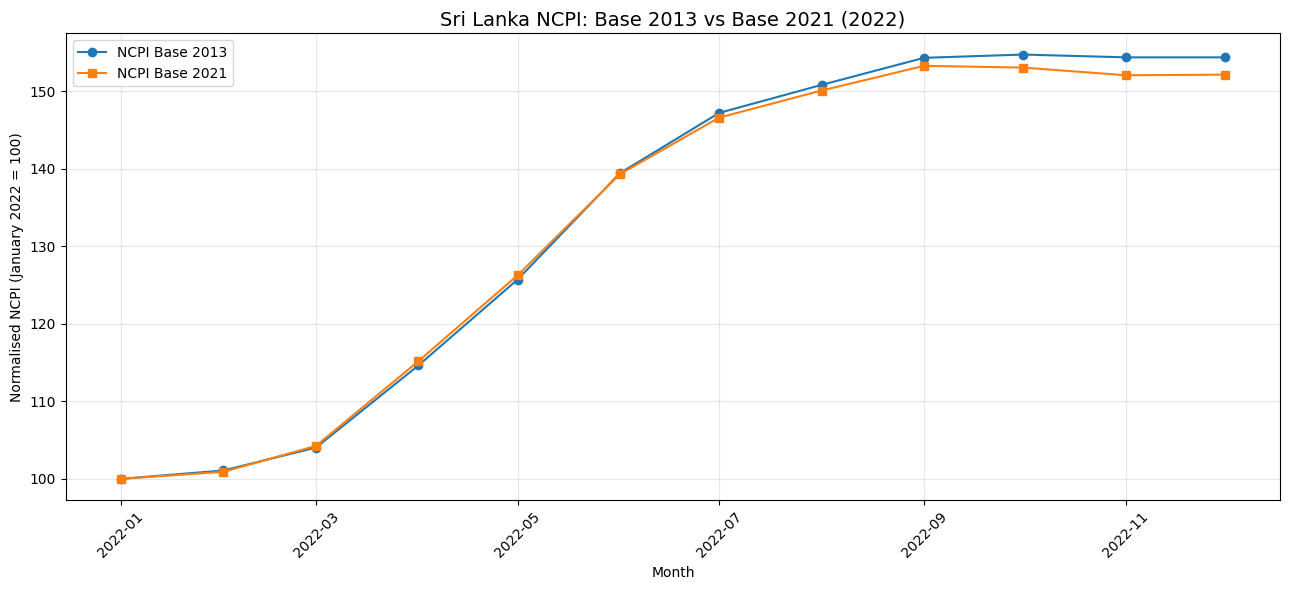

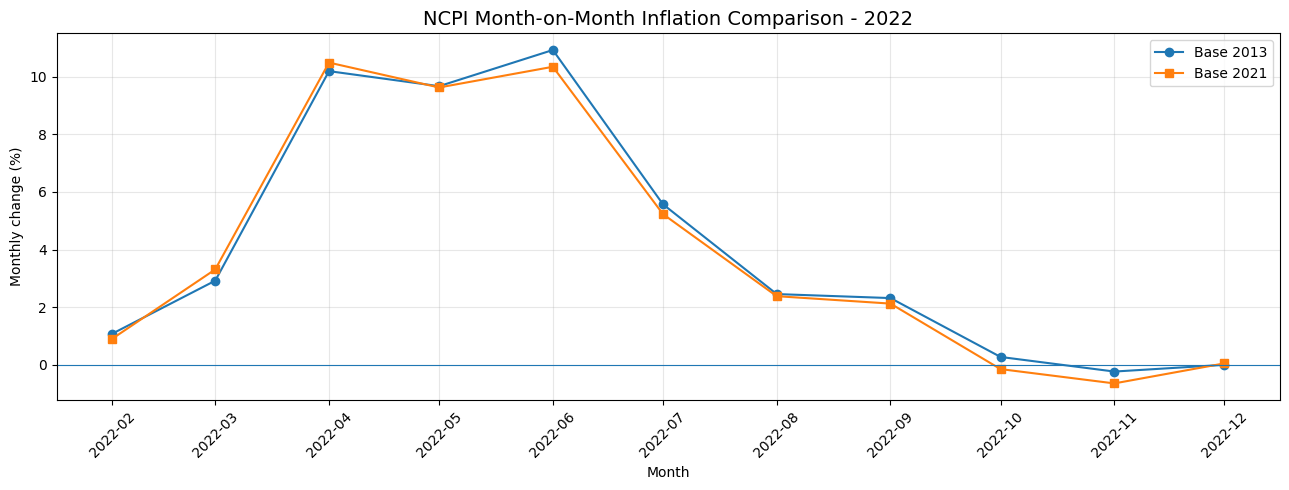


NCPI COMPARISON COMPLETED


In [ ]:

# ============================================================
# CELL 41: NCPI BASE 2013 VS BASE 2021 COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("=" * 70)
print("NCPI INDEX BASE COMPARISON - 2022")
print("=" * 70)

# ------------------------------------------------------------
# 1. PREPARE COPIES
# ------------------------------------------------------------

old = ncpi_2013_df.copy().sort_values("Date")
new = ncpi_2021_df.copy().sort_values("Date")

old["MoM_Change_Pct"] = old["NCPI_Index"].pct_change() * 100
new["MoM_Change_Pct"] = new["NCPI_Index"].pct_change() * 100

# Select the overlapping year
old_2022 = old[
    old["Date"].dt.year == 2022
].copy()

new_2022 = new[
    new["Date"].dt.year == 2022
].copy()

# ------------------------------------------------------------
# 2. NORMALISE BOTH SERIES
# January 2022 = 100
# ------------------------------------------------------------

old_base = old_2022.loc[
    old_2022["Date"].dt.month == 1,
    "NCPI_Index"
].iloc[0]

new_base = new_2022.loc[
    new_2022["Date"].dt.month == 1,
    "NCPI_Index"
].iloc[0]

old_2022["Normalised_Index"] = (
    old_2022["NCPI_Index"] / old_base
) * 100

new_2022["Normalised_Index"] = (
    new_2022["NCPI_Index"] / new_base
) * 100

# ------------------------------------------------------------
# 3. COMPARE MONTH-ON-MONTH CHANGES
# ------------------------------------------------------------

comparison = pd.merge(
    old_2022[["Date", "MoM_Change_Pct"]],
    new_2022[["Date", "MoM_Change_Pct"]],
    on="Date",
    suffixes=("_Base2013", "_Base2021")
)

# January is excluded because the Base 2021 series
# does not contain December 2021.
comparison = comparison.dropna().copy()

comparison["Difference_Pct_Points"] = (
    comparison["MoM_Change_Pct_Base2021"]
    - comparison["MoM_Change_Pct_Base2013"]
)

correlation = comparison[
    "MoM_Change_Pct_Base2013"
].corr(
    comparison["MoM_Change_Pct_Base2021"]
)

mean_difference = comparison[
    "Difference_Pct_Points"
].mean()

max_difference = comparison[
    "Difference_Pct_Points"
].abs().max()

# ------------------------------------------------------------
# 4. DISPLAY STATISTICS
# ------------------------------------------------------------

print("\nOVERLAPPING PERIOD")
print("-" * 50)
print("Period: January 2022 - December 2022")
print(f"Base 2013 January index: {old_base}")
print(f"Base 2021 January index: {new_base}")

print("\nMONTH-ON-MONTH COMPARISON")
print("-" * 50)
print(f"Compared months: {len(comparison)}")
print(f"Correlation: {correlation:.6f}")
print(f"Mean difference: {mean_difference:.6f} percentage points")
print(f"Maximum absolute difference: {max_difference:.6f} percentage points")

print("\nMONTHLY COMPARISON TABLE")
display(comparison.round(4))

# ------------------------------------------------------------
# 5. VISUALISE NORMALISED INDEX MOVEMENT
# ------------------------------------------------------------

plt.figure(figsize=(13, 6))

plt.plot(
    old_2022["Date"],
    old_2022["Normalised_Index"],
    marker="o",
    label="NCPI Base 2013"
)

plt.plot(
    new_2022["Date"],
    new_2022["Normalised_Index"],
    marker="s",
    label="NCPI Base 2021"
)

plt.title(
    "Sri Lanka NCPI: Base 2013 vs Base 2021 (2022)",
    fontsize=14
)

plt.xlabel("Month")
plt.ylabel("Normalised NCPI (January 2022 = 100)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. VISUALISE MONTHLY GROWTH RATE DIFFERENCES
# ------------------------------------------------------------

plt.figure(figsize=(13, 5))

plt.plot(
    comparison["Date"],
    comparison["MoM_Change_Pct_Base2013"],
    marker="o",
    label="Base 2013"
)

plt.plot(
    comparison["Date"],
    comparison["MoM_Change_Pct_Base2021"],
    marker="s",
    label="Base 2021"
)

plt.axhline(0, linewidth=0.8)

plt.title(
    "NCPI Month-on-Month Inflation Comparison - 2022",
    fontsize=14
)

plt.xlabel("Month")
plt.ylabel("Monthly change (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("NCPI COMPARISON COMPLETED")
print("=" * 70)


Cell 42 — Finalise and save NCPI datasets

In [ ]:

# ============================================================
# CELL 42: SAVE VALIDATED NCPI DATASETS
# ============================================================

import os
import pandas as pd

from pathlib import Path

print("=" * 70)
print("NCPI DATASET FINALISATION AND EXPORT")
print("=" * 70)

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"
)

if not OUTPUT_DIR.exists():
    raise FileNotFoundError(
        "Google Drive output directory not found. "
        "Mount Google Drive and verify the folder."
    )

# ------------------------------------------------------------
# 2. PREPARE CLEANED DATASETS
# ------------------------------------------------------------

ncpi_2013_final = ncpi_2013_df.copy()
ncpi_2021_final = ncpi_2021_df.copy()

for df in [ncpi_2013_final, ncpi_2021_final]:

    df["Date"] = pd.to_datetime(df["Date"])

    df["MoM_Change_Pct"] = (
        df["NCPI_Index"].pct_change() * 100
    )

    df.sort_values("Date", inplace=True)
    df.reset_index(drop=True, inplace=True)

# ------------------------------------------------------------
# 3. VALIDATE BEFORE EXPORT
# ------------------------------------------------------------

assert len(ncpi_2013_final) == 108
assert len(ncpi_2021_final) == 57

assert not ncpi_2013_final["Date"].duplicated().any()
assert not ncpi_2021_final["Date"].duplicated().any()

assert ncpi_2013_final["NCPI_Index"].notna().all()
assert ncpi_2021_final["NCPI_Index"].notna().all()

assert (ncpi_2013_final["NCPI_Index"] > 0).all()
assert (ncpi_2021_final["NCPI_Index"] > 0).all()

# ------------------------------------------------------------
# 4. EXPORT FILES
# ------------------------------------------------------------

files_to_save = {
    "ncpi_base2013_monthly_cleaned.csv": ncpi_2013_final,
    "ncpi_base2021_monthly_cleaned.csv": ncpi_2021_final,
    "ncpi_2022_base_comparison.csv": comparison
}

for filename, dataframe in files_to_save.items():

    output_path = OUTPUT_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        date_format="%Y-%m-%d"
    )

    print(f"\nSAVED: {filename}")
    print(f"Records: {len(dataframe)}")
    print(f"Size: {output_path.stat().st_size:,} bytes")

# ------------------------------------------------------------
# 5. READ-BACK VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FILE READ-BACK VERIFICATION")
print("=" * 70)

for filename, original_df in files_to_save.items():

    output_path = OUTPUT_DIR / filename

    if not output_path.exists():
        raise FileNotFoundError(filename)

    verified_df = pd.read_csv(output_path)

    assert len(verified_df) == len(original_df)

    print(
        f"VERIFIED: {filename} | "
        f"{len(verified_df)} records"
    )

# ------------------------------------------------------------
# 6. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NCPI DATASETS SUCCESSFULLY EXPORTED")
print("=" * 70)

print(f"Output directory: {OUTPUT_DIR}")
print("NCPI Base 2013: 108 observations")
print("NCPI Base 2021: 57 observations")
print("2022 comparison: 11 monthly comparisons")
print("Total monthly observations: 165")
print("Read-back verification: PASSED")


NCPI DATASET FINALISATION AND EXPORT

SAVED: ncpi_base2013_monthly_cleaned.csv
Records: 108
Size: 3,855 bytes

SAVED: ncpi_base2021_monthly_cleaned.csv
Records: 57
Size: 2,072 bytes

SAVED: ncpi_2022_base_comparison.csv
Records: 11
Size: 819 bytes

FILE READ-BACK VERIFICATION
VERIFIED: ncpi_base2013_monthly_cleaned.csv | 108 records
VERIFIED: ncpi_base2021_monthly_cleaned.csv | 57 records
VERIFIED: ncpi_2022_base_comparison.csv | 11 records

NCPI DATASETS SUCCESSFULLY EXPORTED
Output directory: /content/drive/MyDrive/Gold_Oil_Cost_of_Living
NCPI Base 2013: 108 observations
NCPI Base 2021: 57 observations
2022 comparison: 11 monthly comparisons
Total monthly observations: 165
Read-back verification: PASSED


Cell 43 — Audit our existing research datasets

In [ ]:

# ============================================================
# CELL 43: EXISTING DATASET INVENTORY & SCHEMA AUDIT
# ============================================================

import pandas as pd
from pathlib import Path

print("=" * 75)
print("GOLD, OIL & COST-OF-LIVING DATASET INVENTORY")
print("=" * 75)

DATA_DIR = Path(
    "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"
)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Research directory not found: {DATA_DIR}"
    )

csv_files = sorted(DATA_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError("No CSV files found in research directory.")

inventory = []

for file_path in csv_files:

    try:
        df = pd.read_csv(file_path)

        date_columns = [
            col for col in df.columns
            if "date" in col.lower()
        ]

        date_range = "Not identified"

        if date_columns:
            date_col = date_columns[0]
            dates = pd.to_datetime(
                df[date_col], errors="coerce"
            ).dropna()

            if not dates.empty:
                date_range = (
                    f"{dates.min():%Y-%m-%d} to "
                    f"{dates.max():%Y-%m-%d}"
                )

        inventory.append({
            "Filename": file_path.name,
            "Rows": len(df),
            "Columns": len(df.columns),
            "Date Range": date_range,
            "Missing Values": int(df.isna().sum().sum()),
            "Column Names": ", ".join(df.columns)
        })

    except Exception as error:
        inventory.append({
            "Filename": file_path.name,
            "Rows": "ERROR",
            "Columns": "-",
            "Date Range": "-",
            "Missing Values": "-",
            "Column Names": str(error)
        })

inventory_df = pd.DataFrame(inventory)

print(f"\nCSV FILES FOUND: {len(csv_files)}\n")
display(inventory_df)

# ------------------------------------------------------------
# IMPORTANT RESEARCH FILES
# ------------------------------------------------------------

important_files = [
    "international_market_data.csv",
    "usd_lkr_daily_cleaned.csv",
    "ncpi_base2013_monthly_cleaned.csv",
    "ncpi_base2021_monthly_cleaned.csv",
    "ncpi_2022_base_comparison.csv"
]

print("\n" + "=" * 75)
print("IMPORTANT DATASET AVAILABILITY")
print("=" * 75)

for filename in important_files:

    path = DATA_DIR / filename

    status = "FOUND" if path.exists() else "NOT FOUND"

    print(f"{status}: {filename}")

# ------------------------------------------------------------
# GOLD DATASET CANDIDATES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("GOLD DATASET CANDIDATES")
print("=" * 75)

gold_candidates = [
    item for item in inventory
    if "gold" in item["Filename"].lower()
]

if gold_candidates:
    display(pd.DataFrame(gold_candidates))
else:
    print("No CSV filename containing 'gold' was found.")

print("\n" + "=" * 75)
print("DATASET INVENTORY COMPLETED")
print("=" * 75)


GOLD, OIL & COST-OF-LIVING DATASET INVENTORY

CSV FILES FOUND: 46



,Filename,Rows,Columns,Date Range,Missing Values,Column Names
0,DCOILBRENTEU.csv,10301,2,1987-05-20 to 2026-11-11,1173,"observation_date, DCOILBRENTEU"
1,DCOILWTICO.csv,10660,2,1986-01-02 to 2026-11-11,1117,"observation_date, DCOILWTICO"
2,GVZCLS.csv,4813,2,2008-06-03 to 2026-11-12,169,"observation_date, GVZCLS"
3,OVXCLS.csv,3095,2,2015-01-02 to 2026-11-12,109,"observation_date, OVXCLS"
4,actual_vs_fitted_inflation_2023_2026.csv,90,5,2023-01-01 to 2026-09-01,0,"Date, Outcome, Actual_Inflation_Pct, Fitted_In..."
5,actual_vs_fitted_model_performance.csv,2,6,Not identified,0,"Outcome, Observations, R_Squared, Adjusted_R_S..."
6,brent_lag_coefficient_comparison.csv,40,8,Not identified,0,"Model, Period, Outcome, Brent_Specification, V..."
7,brent_lag_model_fit_comparison.csv,8,8,Not identified,0,"Period, Outcome, Brent_Specification, Observat..."
8,ccpi_all_items_base2013_monthly.csv,97,5,2015-01-01 to 2023-01-01,11,"Date, CCPI_All_Items_Base2013, All_Items_MoM_I..."
9,ccpi_food_nonfood_base2021_monthly.csv,58,13,2022-01-01 to 2026-10-01,111,"Date, CCPI_All_Items, All_Items_MoM_Inflation_..."



IMPORTANT DATASET AVAILABILITY
FOUND: international_market_data.csv
FOUND: usd_lkr_daily_cleaned.csv
FOUND: ncpi_base2013_monthly_cleaned.csv
FOUND: ncpi_base2021_monthly_cleaned.csv
FOUND: ncpi_2022_base_comparison.csv

GOLD DATASET CANDIDATES


,Filename,Rows,Columns,Date Range,Missing Values,Column Names
0,gold_monthly.csv,2326,2,1833-01-01 to 2026-10-01,0,"Date, Price"
1,gold_monthly_cleaned.csv,142,2,2015-01-01 to 2026-10-01,0,"Date, Gold_USD_per_Ounce"



DATASET INVENTORY COMPLETED


# Task 3 — Exploratory data analysis (EDA) and visual findings

**Analytical questions:** How do prices, exchange rates and inflation change over time? Are distributions heavy-tailed? Do associations change after the 2022 crisis? Does an oil-price movement appear more related to inflation at a delay, and what could confound that appearance?

**Visual evidence in original cells:** monthly time-series panels (Cells 44–45), correlation matrices and lagged comparisons (Cells 45–47), Brent/WTI and exchange-rate trend charts (Cell 55), confidence-interval coefficient visualisation (Cell 56), actual-versus-fitted (Cell 57), residual plots (Cell 58), extreme-return distribution (Cell 63), actual-versus-predicted return lines (Cell 68) and feature-importance charts (Cell 69). These are more than five distinct analytical views; the **caption, sample dates and interpretation** matter more than the count.

**Existing exploratory finding (Cell 46's saved results):** On the 56 monthly changes between February 2022 and September 2026, the USD/LKR month-on-month change correlated approximately **0.469** with CCPI change and **0.558** with NCPI change in Pearson analysis. The contemporaneous Brent change had close-to-zero simple correlation in the same period. Gold changes had negative simple correlations with both inflation series. **These are unconditional associations**, sensitive to unusual 2022 movements, different lag choices and other omitted drivers. The same relationship need not hold after 2022.

**Critical reading of the visuals:**

1. Trend plots illustrate **when** shocks and co-movements occurred; common trends in levels do not establish causal relationships.
2. Pearson/Spearman and lag grids are **screening tools**. Searching many lags increases the chance of selecting an apparently strong association by chance.
3. The monthly inflation regression sample is small relative to the long daily history. Wide confidence intervals and crisis sensitivity are important.
4. Market returns are **continuous, not categories**: there is no ordinary class imbalance to fix. Instead, there is tail-event sparsity, regime imbalance (quiet vs stressed periods), non-normality and temporal sample-selection bias.
5. High leverage, residual autocorrelation, heteroskedasticity and multicollinearity should be read alongside the regression coefficient plots before any substantive claim.

In the report, identify each exported plot by its **actual title**, dates, units, variable definitions and relevant cell. Never label a monthly correlation as an ML forecast result.

Cell 44 — Build the monthly market dataset and generate our first charts

BUILDING MONTHLY GOLD, OIL & EXCHANGE RATE DATASET

SOURCE DATASETS
---------------------------------------------------------------------------
Gold records: 142
Oil records: 3096
Exchange-rate records: 2850

MONTHLY DATASET VALIDATION
---------------------------------------------------------------------------
Monthly records: 143
First month: 2015-01
Last month: 2026-11

Missing monthly values:
Gold_USD_per_Ounce      1
Brent_USD_per_Barrel    0
WTI_USD_per_Barrel      0
USD_LKR_Mid             1
dtype: int64

Monthly observation coverage:
      Date  Gold_Observations  Brent_Observations  WTI_Observations  FX_Observations
2025-12-01                1.0                  21                22             21.0
2026-01-01                1.0                  21                20             21.0
2026-02-01                1.0                  20                19             19.0
2026-03-01                1.0                  22                22             21.0
2026-04-01                1.

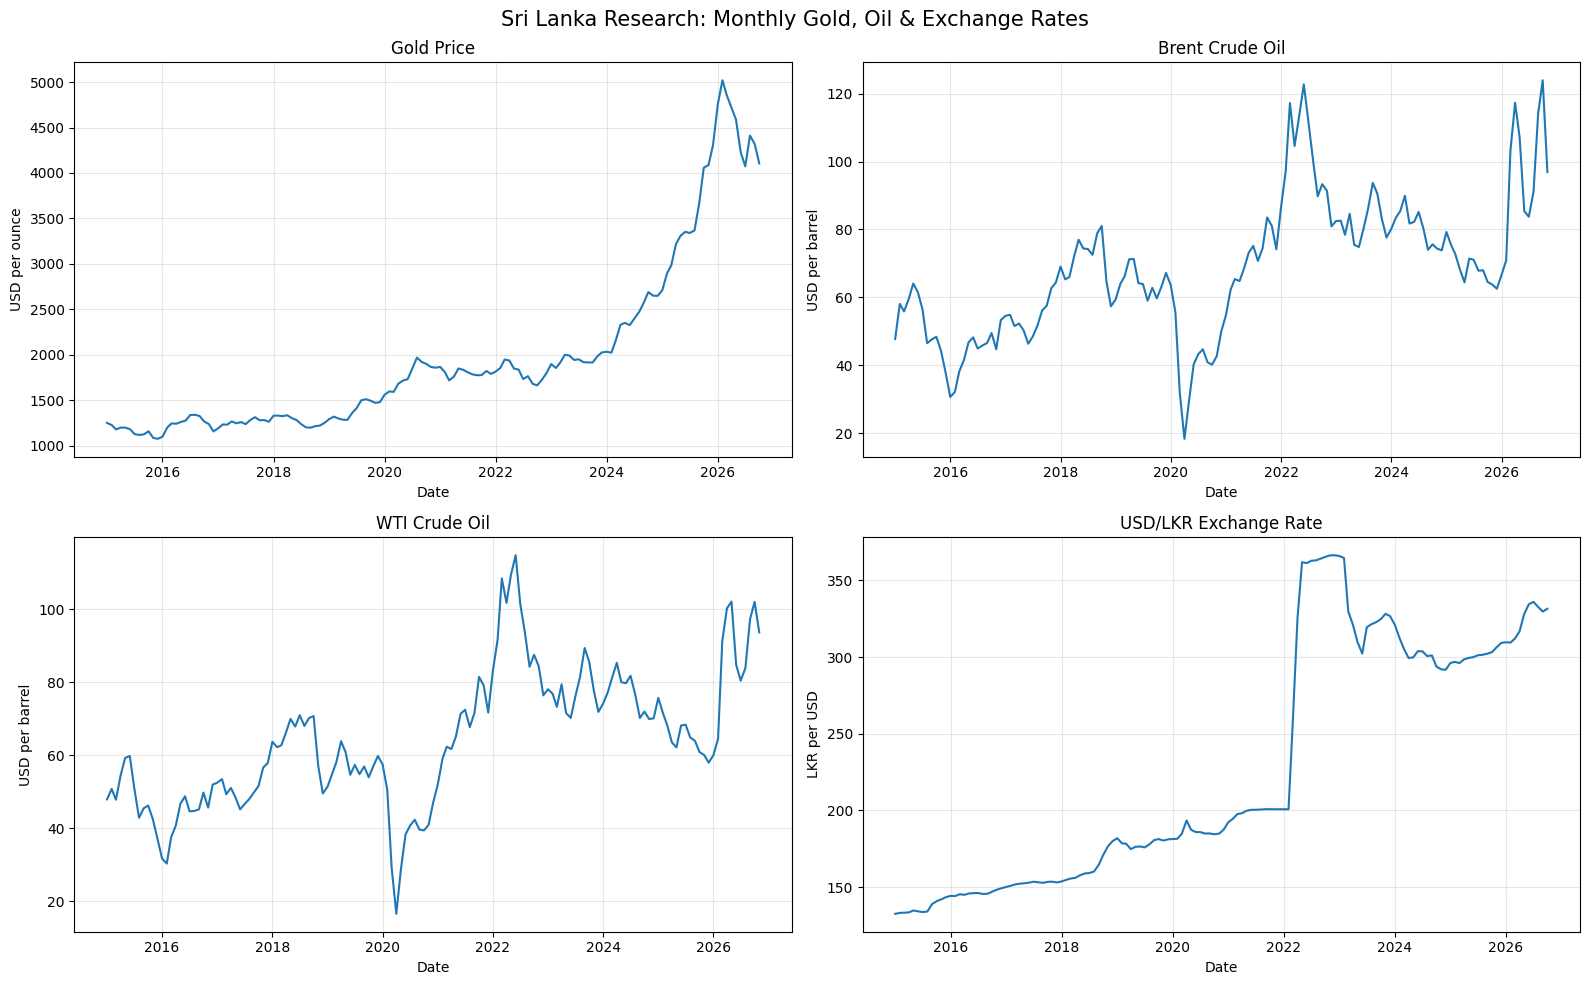

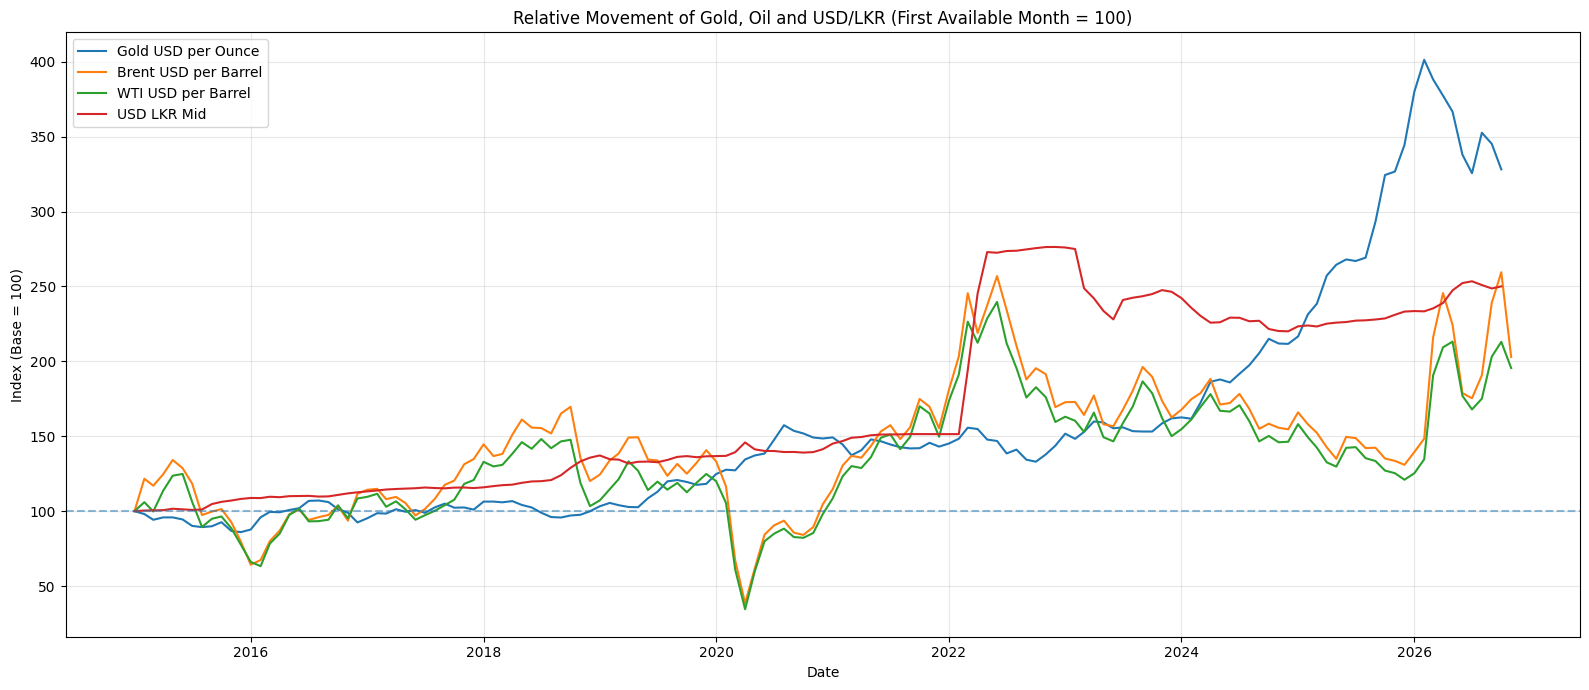


MONTHLY MARKET DATASET AND VISUALISATIONS COMPLETED


In [ ]:

# ============================================================
# CELL 44: MONTHLY MARKET DATASET & FIRST VISUALISATIONS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"
)

print("=" * 75)
print("BUILDING MONTHLY GOLD, OIL & EXCHANGE RATE DATASET")
print("=" * 75)

# ------------------------------------------------------------
# 1. LOAD EXISTING CLEANED DATASETS
# ------------------------------------------------------------

gold = pd.read_csv(DATA_DIR / "gold_monthly_cleaned.csv")
oil = pd.read_csv(DATA_DIR / "international_market_data.csv")
fx = pd.read_csv(DATA_DIR / "usd_lkr_daily_cleaned.csv")

# Parse dates
gold["Date"] = pd.to_datetime(gold["Date"], errors="coerce")
oil["Date"] = pd.to_datetime(oil["Date"], errors="coerce")
fx["Date"] = pd.to_datetime(fx["Date"], errors="coerce")

print("\nSOURCE DATASETS")
print("-" * 75)

print(f"Gold records: {len(gold)}")
print(f"Oil records: {len(oil)}")
print(f"Exchange-rate records: {len(fx)}")

# ------------------------------------------------------------
# 2. VALIDATE REQUIRED COLUMNS
# ------------------------------------------------------------

required_gold = ["Date", "Gold_USD_per_Ounce"]

required_oil = [
    "Date",
    "DCOILBRENTEU",
    "DCOILWTICO"
]

required_fx = [
    "Date",
    "USD_LKR_TT_Buying",
    "USD_LKR_TT_Selling"
]

for name, df, required in [
    ("Gold", gold, required_gold),
    ("Oil", oil, required_oil),
    ("Exchange rate", fx, required_fx)
]:
    missing = [col for col in required if col not in df.columns]

    if missing:
        raise ValueError(
            f"{name} dataset is missing required columns: {missing}"
        )

# Convert price/rate columns to numeric
for col in ["Gold_USD_per_Ounce"]:
    gold[col] = pd.to_numeric(gold[col], errors="coerce")

for col in ["DCOILBRENTEU", "DCOILWTICO"]:
    oil[col] = pd.to_numeric(oil[col], errors="coerce")

for col in ["USD_LKR_TT_Buying", "USD_LKR_TT_Selling"]:
    fx[col] = pd.to_numeric(fx[col], errors="coerce")

# ------------------------------------------------------------
# 3. CREATE MONTHLY GOLD DATA
# ------------------------------------------------------------

gold = gold.dropna(subset=["Date", "Gold_USD_per_Ounce"]).copy()

gold["Month"] = gold["Date"].dt.to_period("M")

gold_monthly = (
    gold.groupby("Month")
    .agg(
        Gold_USD_per_Ounce=("Gold_USD_per_Ounce", "mean"),
        Gold_Observations=("Gold_USD_per_Ounce", "count")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 4. CREATE MONTHLY OIL DATA
# ------------------------------------------------------------

oil = oil.dropna(subset=["Date"]).copy()
oil["Month"] = oil["Date"].dt.to_period("M")

oil_monthly = (
    oil.groupby("Month")
    .agg(
        Brent_USD_per_Barrel=("DCOILBRENTEU", "mean"),
        Brent_Observations=("DCOILBRENTEU", "count"),
        WTI_USD_per_Barrel=("DCOILWTICO", "mean"),
        WTI_Observations=("DCOILWTICO", "count")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 5. CREATE MONTHLY EXCHANGE-RATE DATA
# ------------------------------------------------------------

fx = fx.dropna(subset=["Date"]).copy()

# Midpoint between TT buying and TT selling rates
fx["USD_LKR_Mid"] = (
    fx["USD_LKR_TT_Buying"] +
    fx["USD_LKR_TT_Selling"]
) / 2

fx["Month"] = fx["Date"].dt.to_period("M")

fx_monthly = (
    fx.groupby("Month")
    .agg(
        USD_LKR_Mid=("USD_LKR_Mid", "mean"),
        FX_Observations=("USD_LKR_Mid", "count")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 6. MERGE ALL MONTHLY DATASETS
# ------------------------------------------------------------

market_monthly_df = (
    gold_monthly
    .merge(oil_monthly, on="Month", how="outer")
    .merge(fx_monthly, on="Month", how="outer")
    .sort_values("Month")
    .reset_index(drop=True)
)

# Convert monthly Period into a normal date (first day of month)
market_monthly_df.insert(
    0,
    "Date",
    market_monthly_df["Month"].dt.to_timestamp()
)

market_monthly_df.drop(columns=["Month"], inplace=True)

# ------------------------------------------------------------
# 7. VALIDATION AND COVERAGE REPORT
# ------------------------------------------------------------

price_columns = [
    "Gold_USD_per_Ounce",
    "Brent_USD_per_Barrel",
    "WTI_USD_per_Barrel",
    "USD_LKR_Mid"
]

print("\nMONTHLY DATASET VALIDATION")
print("-" * 75)

print(f"Monthly records: {len(market_monthly_df)}")
print(f"First month: {market_monthly_df['Date'].min():%Y-%m}")
print(f"Last month: {market_monthly_df['Date'].max():%Y-%m}")

print("\nMissing monthly values:")
print(market_monthly_df[price_columns].isna().sum())

print("\nMonthly observation coverage:")
print(
    market_monthly_df[
        [
            "Date",
            "Gold_Observations",
            "Brent_Observations",
            "WTI_Observations",
            "FX_Observations"
        ]
    ].tail(12).to_string(index=False)
)

# ------------------------------------------------------------
# 8. SAVE MERGED DATASET
# ------------------------------------------------------------

output_file = DATA_DIR / "market_monthly_2015_2026.csv"

market_monthly_df.to_csv(output_file, index=False)

# Read-back verification
verified = pd.read_csv(output_file)

assert len(verified) == len(market_monthly_df)
assert verified["Date"].notna().all()

print("\nSAVED:", output_file.name)
print("Read-back records:", len(verified))
print("FILE VERIFICATION: PASSED")

# ------------------------------------------------------------
# 9. VISUALISATION 1: RAW MONTHLY VALUES
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

chart_config = [
    ("Gold_USD_per_Ounce", "Gold Price", "USD per ounce"),
    ("Brent_USD_per_Barrel", "Brent Crude Oil", "USD per barrel"),
    ("WTI_USD_per_Barrel", "WTI Crude Oil", "USD per barrel"),
    ("USD_LKR_Mid", "USD/LKR Exchange Rate", "LKR per USD")
]

for ax, (column, title, ylabel) in zip(axes.flat, chart_config):

    valid = market_monthly_df.dropna(
        subset=["Date", column]
    )

    ax.plot(valid["Date"], valid[column])

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Date")
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Sri Lanka Research: Monthly Gold, Oil & Exchange Rates",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. VISUALISATION 2: NORMALISED PRICE MOVEMENT
# ------------------------------------------------------------

indexed_df = market_monthly_df[["Date"] + price_columns].copy()

for column in price_columns:

    first_valid = indexed_df[column].first_valid_index()

    if first_valid is not None:
        base_value = indexed_df.loc[first_valid, column]

        if pd.notna(base_value) and base_value != 0:
            indexed_df[column] = (
                indexed_df[column] / base_value
            ) * 100

plt.figure(figsize=(16, 7))

for column in price_columns:
    plt.plot(
        indexed_df["Date"],
        indexed_df[column],
        label=column.replace("_", " ")
    )

plt.axhline(100, linestyle="--", alpha=0.5)

plt.title(
    "Relative Movement of Gold, Oil and USD/LKR (First Available Month = 100)"
)

plt.xlabel("Date")
plt.ylabel("Index (Base = 100)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n" + "=" * 75)
print("MONTHLY MARKET DATASET AND VISUALISATIONS COMPLETED")
print("=" * 75)


Cell 45 — Combine market data with Sri Lankan inflation

SRI LANKAN INFLATION & INTERNATIONAL MARKET ANALYSIS

OVERLAPPING DATASET COVERAGE
---------------------------------------------------------------------------
Monthly observations: 57
First month: 2022-01
Last month: 2026-09
Rows removed due to missing values: 0

FIRST FIVE OBSERVATIONS


,Date,Gold_USD_per_Ounce,Brent_USD_per_Barrel,WTI_USD_per_Barrel,USD_LKR_Mid,CCPI_2021,NCPI_2021,Gold_MoM_Pct,Brent_MoM_Pct,WTI_MoM_Pct,USD_LKR_MoM_Pct,CCPI_MoM_Pct,NCPI_MoM_Pct
0,2022-01-01,1816.0,86.505238,83.222000,200.750000,124.3,131.7,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-02-01,1856.0,97.129000,91.641053,200.750000,125.8,132.9,2.202643,12.281062,10.116379,0.000000,1.206758,0.911162
2,2022-03-01,1948.0,117.245217,108.502609,257.387781,129.7,137.3,4.956897,20.710825,18.399566,28.213091,3.100159,3.310760
3,2022-04-01,1937.0,104.575263,101.777500,325.282294,142.1,151.7,-0.564682,-10.806372,-6.198108,26.378297,9.560524,10.487983
4,2022-05-01,1849.0,113.337619,109.552381,361.833122,153.6,166.3,-4.543108,8.378995,7.639096,11.236648,8.092892,9.624258



LAST FIVE OBSERVATIONS


,Date,Gold_USD_per_Ounce,Brent_USD_per_Barrel,WTI_USD_per_Barrel,USD_LKR_Mid,CCPI_2021,NCPI_2021,Gold_MoM_Pct,Brent_MoM_Pct,WTI_MoM_Pct,USD_LKR_MoM_Pct,CCPI_MoM_Pct,NCPI_MoM_Pct
52,2026-05-01,4587.0,107.139474,102.134000,327.942416,203.4,218.8,-2.838382,-8.652266,1.811597,3.531428,0.892857,1.155802
53,2026-06-01,4228.0,85.399091,84.807143,334.412360,207.7,222.3,-7.826466,-20.291665,-16.964828,1.972890,2.114061,1.599634
54,2026-07-01,4073.0,83.758696,80.456364,335.986011,208.2,223.4,-3.666036,-1.920858,-5.130204,0.470572,0.240732,0.494827
55,2026-08-01,4411.0,91.076000,83.897619,332.689145,208.8,223.9,8.298551,8.736173,4.277170,-0.981251,0.288184,0.223814
56,2026-09-01,4319.0,114.159091,97.308095,329.629768,209.1,224.2,-2.085695,25.344867,15.984335,-0.919590,0.143678,0.133988



MISSING VALUES
Gold_USD_per_Ounce      0
Brent_USD_per_Barrel    0
WTI_USD_per_Barrel      0
USD_LKR_Mid             0
CCPI_2021               0
NCPI_2021               0
dtype: int64

SAVED: sl_inflation_market_analysis_2022_2026.csv
Read-back records: 57
FILE VERIFICATION: PASSED


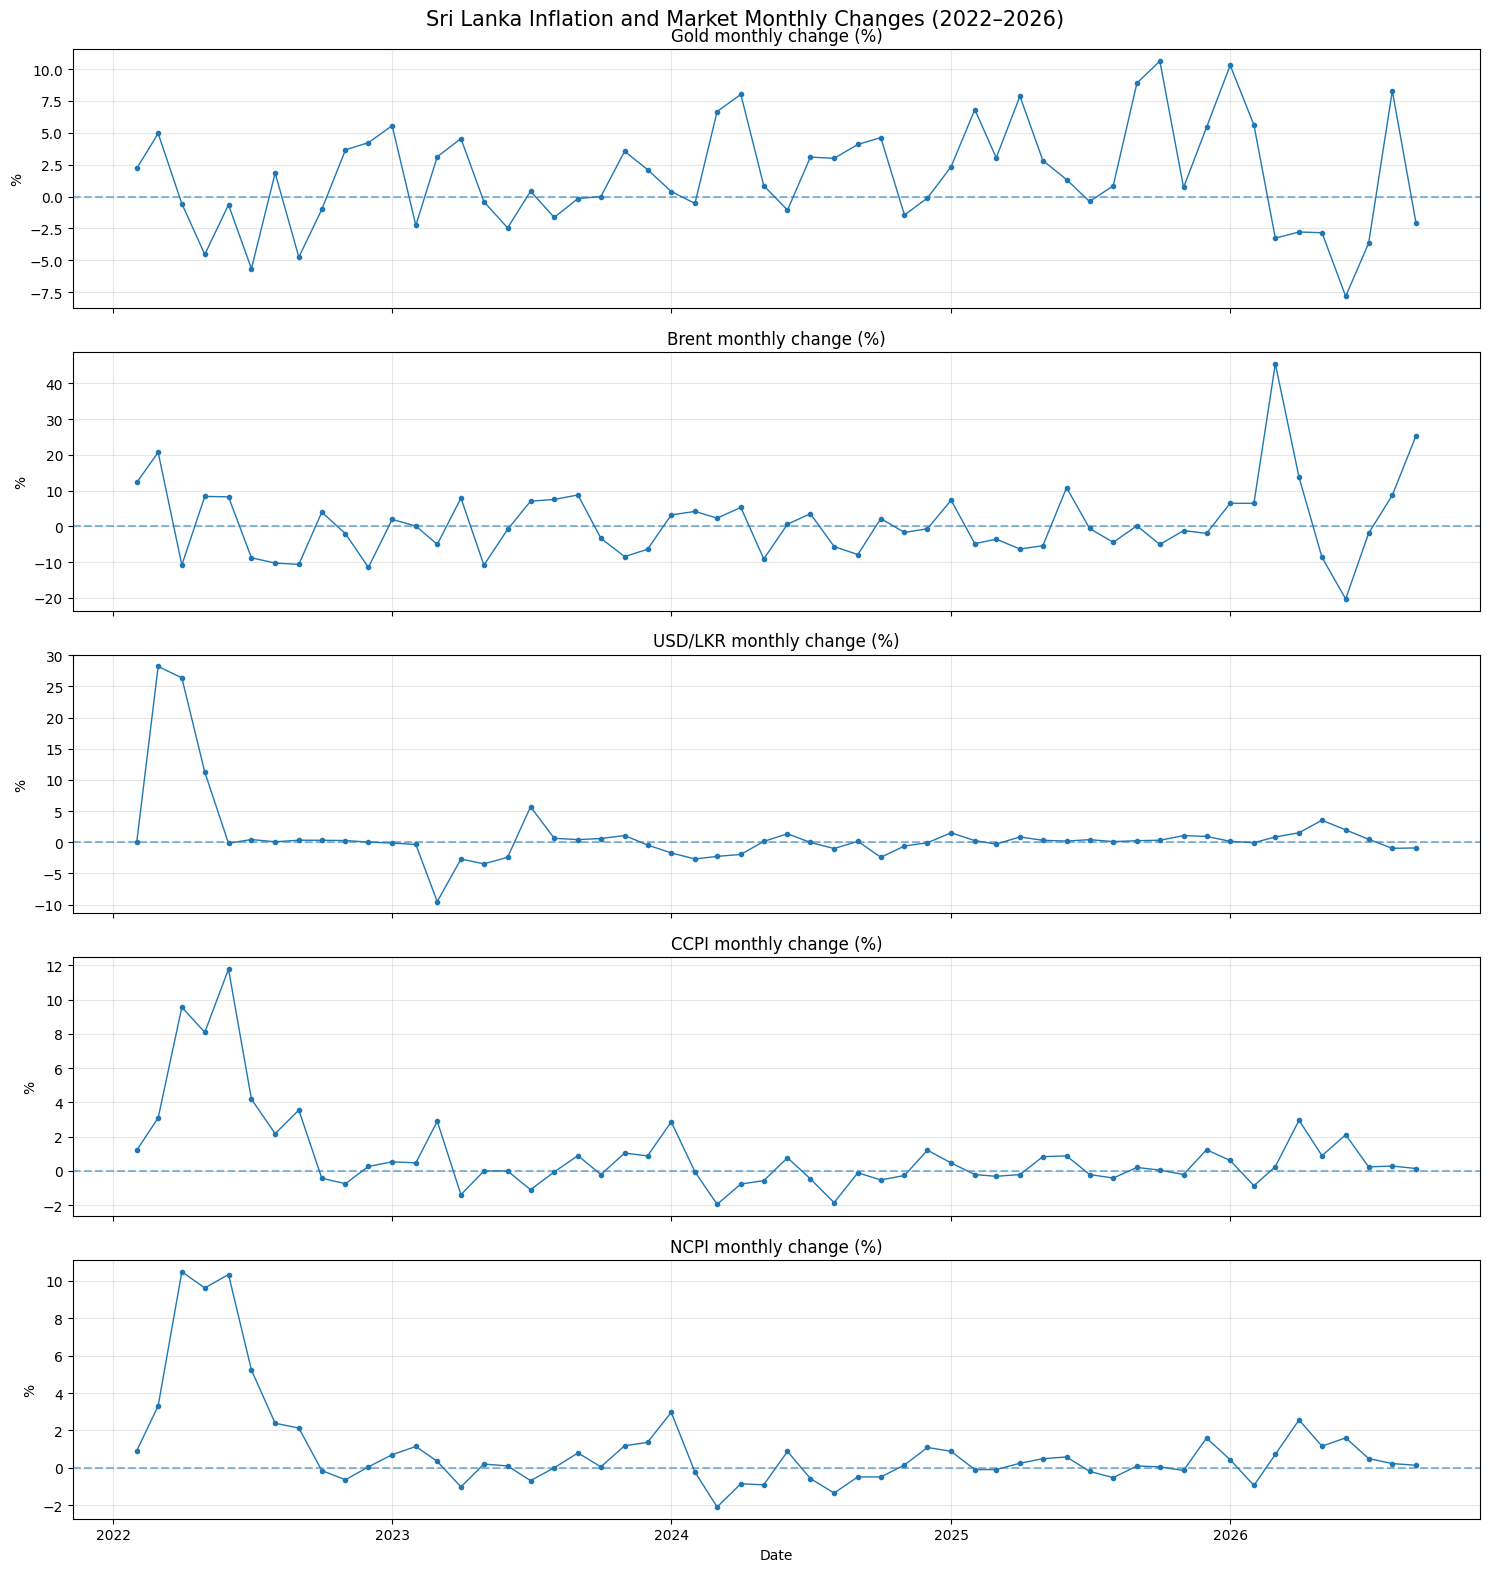


MONTHLY CHANGE CORRELATION MATRIX
---------------------------------------------------------------------------


,Gold_MoM_Pct,Brent_MoM_Pct,WTI_MoM_Pct,USD_LKR_MoM_Pct,CCPI_MoM_Pct,NCPI_MoM_Pct
Gold_MoM_Pct,1.000,0.005,-0.007,-0.090,-0.343,-0.362
Brent_MoM_Pct,0.005,1.000,0.970,0.111,-0.013,0.006
WTI_MoM_Pct,-0.007,0.970,1.000,0.163,-0.020,0.002
USD_LKR_MoM_Pct,-0.090,0.111,0.163,1.000,0.469,0.558
CCPI_MoM_Pct,-0.343,-0.013,-0.020,0.469,1.000,0.973
NCPI_MoM_Pct,-0.362,0.006,0.002,0.558,0.973,1.000


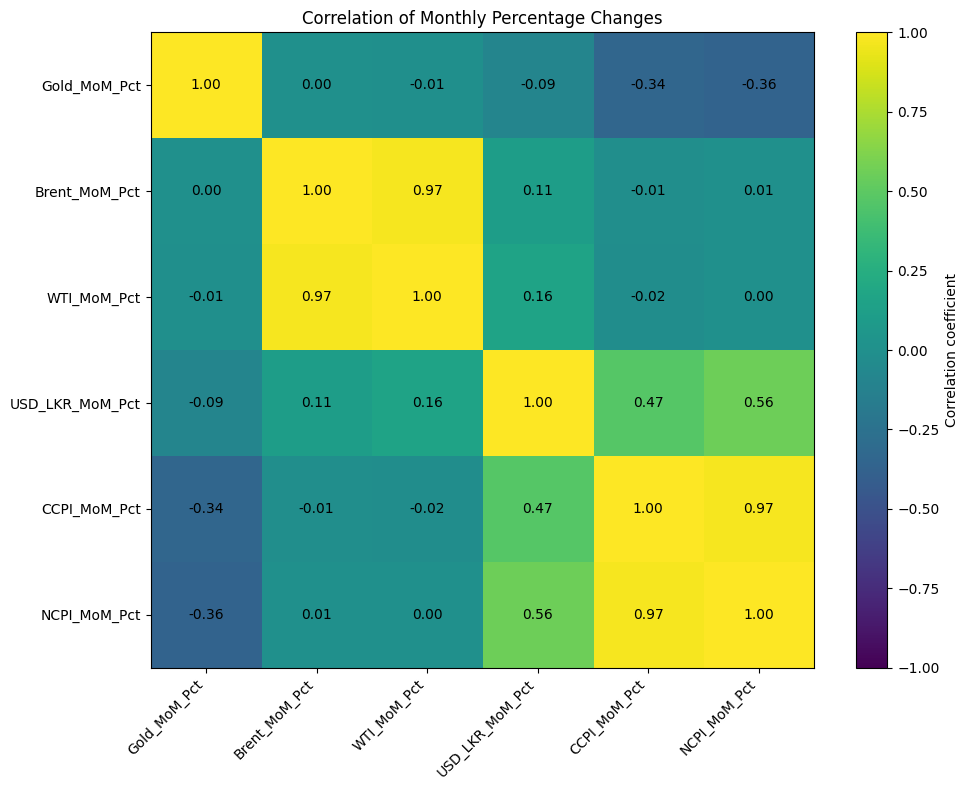


INFLATION & MARKET ANALYSIS DATASET COMPLETED


In [ ]:

# ============================================================
# CELL 45: COMBINE MARKET DATA WITH SRI LANKAN INFLATION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"
)

print("=" * 75)
print("SRI LANKAN INFLATION & INTERNATIONAL MARKET ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# 1. LOAD DATASETS
# ------------------------------------------------------------

market = pd.read_csv(
    DATA_DIR / "market_monthly_2015_2026.csv"
)

ccpi = pd.read_csv(
    DATA_DIR / "ccpi_food_nonfood_base2021_monthly.csv"
)

ncpi = pd.read_csv(
    DATA_DIR / "ncpi_base2021_monthly_cleaned.csv"
)

# ------------------------------------------------------------
# 2. VALIDATE REQUIRED COLUMNS
# ------------------------------------------------------------

required_market = [
    "Date",
    "Gold_USD_per_Ounce",
    "Brent_USD_per_Barrel",
    "WTI_USD_per_Barrel",
    "USD_LKR_Mid"
]

required_ccpi = ["Date", "CCPI_All_Items"]
required_ncpi = ["Date", "NCPI_Index"]

for name, df, required in [
    ("Market", market, required_market),
    ("CCPI", ccpi, required_ccpi),
    ("NCPI", ncpi, required_ncpi)
]:
    missing = [col for col in required if col not in df.columns]

    if missing:
        raise ValueError(
            f"{name} dataset is missing columns: {missing}\n"
            f"Available columns: {list(df.columns)}"
        )

# ------------------------------------------------------------
# 3. PREPARE DATE AND NUMERIC COLUMNS
# ------------------------------------------------------------

for df in [market, ccpi, ncpi]:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

numeric_columns = [
    "Gold_USD_per_Ounce",
    "Brent_USD_per_Barrel",
    "WTI_USD_per_Barrel",
    "USD_LKR_Mid"
]

for col in numeric_columns:
    market[col] = pd.to_numeric(
        market[col], errors="coerce"
    )

ccpi["CCPI_All_Items"] = pd.to_numeric(
    ccpi["CCPI_All_Items"], errors="coerce"
)

ncpi["NCPI_Index"] = pd.to_numeric(
    ncpi["NCPI_Index"], errors="coerce"
)

# Keep only the required columns
market = market[["Date"] + numeric_columns].copy()

ccpi = ccpi[
    ["Date", "CCPI_All_Items"]
].rename(
    columns={"CCPI_All_Items": "CCPI_2021"}
)

ncpi = ncpi[
    ["Date", "NCPI_Index"]
].rename(
    columns={"NCPI_Index": "NCPI_2021"}
)

# ------------------------------------------------------------
# 4. RESTRICT ANALYSIS TO JANUARY 2022 ONWARDS
# ------------------------------------------------------------

start_date = pd.Timestamp("2022-01-01")

market = market[market["Date"] >= start_date]
ccpi = ccpi[ccpi["Date"] >= start_date]
ncpi = ncpi[ncpi["Date"] >= start_date]

# ------------------------------------------------------------
# 5. MERGE THE THREE DATASETS
# ------------------------------------------------------------

analysis_df = (
    market
    .merge(ccpi, on="Date", how="inner")
    .merge(ncpi, on="Date", how="inner")
    .sort_values("Date")
    .reset_index(drop=True)
)

# Require all six index/price values to be present
analysis_columns = numeric_columns + [
    "CCPI_2021",
    "NCPI_2021"
]

before_cleanup = len(analysis_df)

analysis_df = (
    analysis_df
    .dropna(subset=analysis_columns)
    .reset_index(drop=True)
)

removed_rows = before_cleanup - len(analysis_df)

if analysis_df.empty:
    raise ValueError(
        "No complete overlapping monthly observations were found."
    )

if analysis_df["Date"].duplicated().any():
    raise ValueError("Duplicate monthly dates found after merging.")

# ------------------------------------------------------------
# 6. CALCULATE MONTH-ON-MONTH PERCENTAGE CHANGES
# ------------------------------------------------------------

change_columns = {
    "Gold_USD_per_Ounce": "Gold_MoM_Pct",
    "Brent_USD_per_Barrel": "Brent_MoM_Pct",
    "WTI_USD_per_Barrel": "WTI_MoM_Pct",
    "USD_LKR_Mid": "USD_LKR_MoM_Pct",
    "CCPI_2021": "CCPI_MoM_Pct",
    "NCPI_2021": "NCPI_MoM_Pct"
}

for source, destination in change_columns.items():
    analysis_df[destination] = (
        analysis_df[source]
        .pct_change(fill_method=None) * 100
    )

# ------------------------------------------------------------
# 7. DISPLAY COVERAGE AND DATA VALIDATION
# ------------------------------------------------------------

print("\nOVERLAPPING DATASET COVERAGE")
print("-" * 75)

print("Monthly observations:", len(analysis_df))
print("First month:", analysis_df["Date"].min().strftime("%Y-%m"))
print("Last month:", analysis_df["Date"].max().strftime("%Y-%m"))
print("Rows removed due to missing values:", removed_rows)

print("\nFIRST FIVE OBSERVATIONS")
display(analysis_df.head())

print("\nLAST FIVE OBSERVATIONS")
display(analysis_df.tail())

print("\nMISSING VALUES")
print(analysis_df[analysis_columns].isna().sum())

# ------------------------------------------------------------
# 8. SAVE THE COMBINED ANALYSIS DATASET
# ------------------------------------------------------------

output_file = DATA_DIR / "sl_inflation_market_analysis_2022_2026.csv"

analysis_df.to_csv(output_file, index=False)

verified = pd.read_csv(output_file)

assert len(verified) == len(analysis_df)
assert verified["Date"].notna().all()

print("\nSAVED:", output_file.name)
print("Read-back records:", len(verified))
print("FILE VERIFICATION: PASSED")

# ------------------------------------------------------------
# 9. VISUALISATION: MONTHLY INFLATION AND MARKET CHANGES
# ------------------------------------------------------------

change_chart_columns = [
    ("Gold_MoM_Pct", "Gold monthly change (%)"),
    ("Brent_MoM_Pct", "Brent monthly change (%)"),
    ("USD_LKR_MoM_Pct", "USD/LKR monthly change (%)"),
    ("CCPI_MoM_Pct", "CCPI monthly change (%)"),
    ("NCPI_MoM_Pct", "NCPI monthly change (%)")
]

fig, axes = plt.subplots(
    len(change_chart_columns),
    1,
    figsize=(15, 16),
    sharex=True
)

for ax, (column, title) in zip(
    axes, change_chart_columns
):
    ax.plot(
        analysis_df["Date"],
        analysis_df[column],
        marker=".",
        linewidth=1
    )

    ax.axhline(0, linestyle="--", alpha=0.5)
    ax.set_title(title)
    ax.set_ylabel("%")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date")

plt.suptitle(
    "Sri Lanka Inflation and Market Monthly Changes (2022–2026)",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. CORRELATION ANALYSIS
# ------------------------------------------------------------

correlation_columns = list(change_columns.values())

correlation_matrix = analysis_df[
    correlation_columns
].corr()

print("\nMONTHLY CHANGE CORRELATION MATRIX")
print("-" * 75)

display(correlation_matrix.round(3))

plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Correlation coefficient")

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

for row in range(len(correlation_columns)):
    for col in range(len(correlation_columns)):
        value = correlation_matrix.iloc[row, col]

        plt.text(
            col,
            row,
            f"{value:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation of Monthly Percentage Changes")
plt.tight_layout()
plt.show()

print("\n" + "=" * 75)
print("INFLATION & MARKET ANALYSIS DATASET COMPLETED")
print("=" * 75)


Cell 46 — Test whether the relationships are robust

CORRELATION ROBUSTNESS & LAGGED ANALYSIS

OBSERVATION COUNT
---------------------------------------------------------------------------
Available monthly changes: 56
First change month: 2022-02
Last change month: 2026-09

PEARSON VS SPEARMAN
---------------------------------------------------------------------------


,Market Variable,Inflation Variable,Observations,Pearson,Pearson p-value,Spearman,Spearman p-value
0,Gold_MoM_Pct,CCPI_MoM_Pct,56,-0.3432,0.0096,-0.3563,0.0070
1,Gold_MoM_Pct,NCPI_MoM_Pct,56,-0.3617,0.0062,-0.4170,0.0014
2,Brent_MoM_Pct,CCPI_MoM_Pct,56,-0.0133,0.9224,-0.0345,0.8010
3,Brent_MoM_Pct,NCPI_MoM_Pct,56,0.0063,0.9632,-0.0353,0.7960
4,WTI_MoM_Pct,CCPI_MoM_Pct,56,-0.0202,0.8823,-0.0488,0.7208
5,WTI_MoM_Pct,NCPI_MoM_Pct,56,0.0020,0.9885,-0.0556,0.6838
6,USD_LKR_MoM_Pct,CCPI_MoM_Pct,56,0.4694,0.0003,0.3378,0.0109
7,USD_LKR_MoM_Pct,NCPI_MoM_Pct,56,0.5583,0.0000,0.4027,0.0021



FULL PERIOD VS POST-2022
---------------------------------------------------------------------------


,Period,Market Variable,Inflation Variable,Observations,Pearson Correlation
0,Full period: 2022–2026,Gold_MoM_Pct,CCPI_MoM_Pct,56,-0.3432
1,Full period: 2022–2026,Gold_MoM_Pct,NCPI_MoM_Pct,56,-0.3617
2,Full period: 2022–2026,Brent_MoM_Pct,CCPI_MoM_Pct,56,-0.0133
3,Full period: 2022–2026,Brent_MoM_Pct,NCPI_MoM_Pct,56,0.0063
4,Full period: 2022–2026,WTI_MoM_Pct,CCPI_MoM_Pct,56,-0.0202
5,Full period: 2022–2026,WTI_MoM_Pct,NCPI_MoM_Pct,56,0.0020
6,Full period: 2022–2026,USD_LKR_MoM_Pct,CCPI_MoM_Pct,56,0.4694
7,Full period: 2022–2026,USD_LKR_MoM_Pct,NCPI_MoM_Pct,56,0.5583
8,Excluding 2022: 2023–2026,Gold_MoM_Pct,CCPI_MoM_Pct,45,-0.3005
9,Excluding 2022: 2023–2026,Gold_MoM_Pct,NCPI_MoM_Pct,45,-0.3620



ONE-MONTH LAGGED CORRELATIONS
---------------------------------------------------------------------------


,Market Variable,Inflation Variable,Observations,Lagged Correlation
0,Gold_MoM_Pct,CCPI_MoM_Pct,55,-0.2360
1,Gold_MoM_Pct,NCPI_MoM_Pct,55,-0.2071
2,Brent_MoM_Pct,CCPI_MoM_Pct,55,0.1924
3,Brent_MoM_Pct,NCPI_MoM_Pct,55,0.1878
4,WTI_MoM_Pct,CCPI_MoM_Pct,55,0.2110
5,WTI_MoM_Pct,NCPI_MoM_Pct,55,0.2058
6,USD_LKR_MoM_Pct,CCPI_MoM_Pct,55,0.7667
7,USD_LKR_MoM_Pct,NCPI_MoM_Pct,55,0.8180


... (6 outputs left out)


Largest absolute movements: CCPI_MoM_Pct


,Date,CCPI_MoM_Pct
5,2022-06-01,11.783854
3,2022-04-01,9.560524
4,2022-05-01,8.092892
6,2022-07-01,4.193361
8,2022-09-01,3.555799



Largest absolute movements: NCPI_MoM_Pct


,Date,NCPI_MoM_Pct
3,2022-04-01,10.487983
5,2022-06-01,10.342754
4,2022-05-01,9.624258
6,2022-07-01,5.231608
2,2022-03-01,3.310760


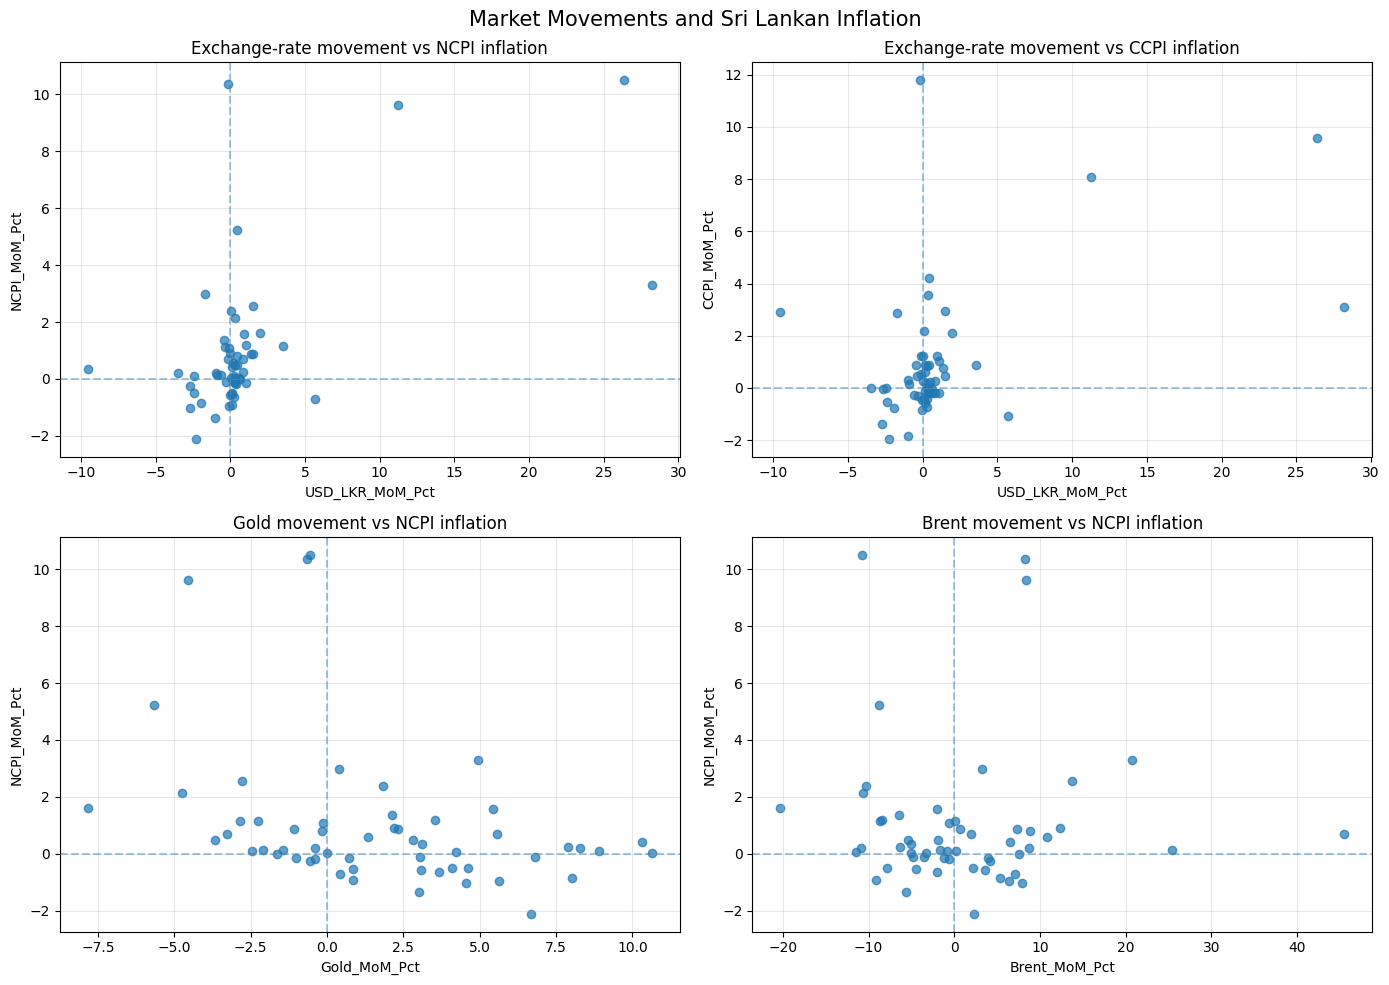


ROBUSTNESS ANALYSIS COMPLETED
Saved:
- correlation_pearson_spearman.csv
- correlation_period_comparison.csv
- correlation_lagged_one_month.csv


In [ ]:

# ============================================================
# CELL 46: CORRELATION ROBUSTNESS & LAGGED RELATIONSHIPS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr

DATA_DIR = "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"

# Load the dataset produced by Cell 45
df = pd.read_csv(
    f"{DATA_DIR}/sl_inflation_market_analysis_2022_2026.csv"
)

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print("=" * 75)
print("CORRELATION ROBUSTNESS & LAGGED ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# 1. DEFINE VARIABLES
# ------------------------------------------------------------

market_variables = [
    "Gold_MoM_Pct",
    "Brent_MoM_Pct",
    "WTI_MoM_Pct",
    "USD_LKR_MoM_Pct"
]

inflation_variables = [
    "CCPI_MoM_Pct",
    "NCPI_MoM_Pct"
]

# Remove the first month, which has no previous-month change
change_df = df.dropna(
    subset=market_variables + inflation_variables
).copy()

print("\nOBSERVATION COUNT")
print("-" * 75)
print("Available monthly changes:", len(change_df))
print("First change month:", change_df["Date"].min().strftime("%Y-%m"))
print("Last change month:", change_df["Date"].max().strftime("%Y-%m"))

# ------------------------------------------------------------
# 2. PEARSON AND SPEARMAN CORRELATIONS
# ------------------------------------------------------------

correlation_results = []

for market_col in market_variables:

    for inflation_col in inflation_variables:

        pair = change_df[
            [market_col, inflation_col]
        ].dropna()

        if len(pair) < 3:
            continue

        pearson_value, pearson_p = pearsonr(
            pair[market_col],
            pair[inflation_col]
        )

        spearman_value, spearman_p = spearmanr(
            pair[market_col],
            pair[inflation_col]
        )

        correlation_results.append({
            "Market Variable": market_col,
            "Inflation Variable": inflation_col,
            "Observations": len(pair),
            "Pearson": pearson_value,
            "Pearson p-value": pearson_p,
            "Spearman": spearman_value,
            "Spearman p-value": spearman_p
        })

correlation_results_df = pd.DataFrame(
    correlation_results
)

print("\nPEARSON VS SPEARMAN")
print("-" * 75)

display(
    correlation_results_df.round(4)
)

# ------------------------------------------------------------
# 3. CHECK WHETHER 2022 DOMINATES THE RESULTS
# ------------------------------------------------------------

full_period = change_df.copy()

post_2022 = change_df[
    change_df["Date"] >= "2023-01-01"
].copy()

period_results = []

for period_name, period_df in [
    ("Full period: 2022–2026", full_period),
    ("Excluding 2022: 2023–2026", post_2022)
]:

    for market_col in market_variables:

        for inflation_col in inflation_variables:

            pair = period_df[
                [market_col, inflation_col]
            ].dropna()

            if len(pair) < 3:
                continue

            period_results.append({
                "Period": period_name,
                "Market Variable": market_col,
                "Inflation Variable": inflation_col,
                "Observations": len(pair),
                "Pearson Correlation": pair[
                    market_col
                ].corr(pair[inflation_col])
            })

period_results_df = pd.DataFrame(period_results)

print("\nFULL PERIOD VS POST-2022")
print("-" * 75)

display(
    period_results_df.round(4)
)

# ------------------------------------------------------------
# 4. LAGGED CORRELATION
# ------------------------------------------------------------
# Question:
# Is a market movement in month T associated with
# inflation movement in month T+1?
#
# shift(1) aligns the previous month's market change
# with the current month's inflation change.

lagged_results = []

for market_col in market_variables:

    previous_month_market = change_df[market_col].shift(1)

    for inflation_col in inflation_variables:

        pair = pd.DataFrame({
            "Previous_Month_Market": previous_month_market,
            "Current_Month_Inflation": change_df[inflation_col]
        }).dropna()

        if len(pair) < 3:
            continue

        lagged_results.append({
            "Market Variable": market_col,
            "Inflation Variable": inflation_col,
            "Observations": len(pair),
            "Lagged Correlation": pair[
                "Previous_Month_Market"
            ].corr(pair["Current_Month_Inflation"])
        })

lagged_results_df = pd.DataFrame(lagged_results)

print("\nONE-MONTH LAGGED CORRELATIONS")
print("-" * 75)

display(
    lagged_results_df.round(4)
)

# ------------------------------------------------------------
# 5. IDENTIFY EXTREME MONTHLY MOVEMENTS
# ------------------------------------------------------------

print("\nLARGEST MONTHLY MOVEMENTS")
print("-" * 75)

for column in [
    "Gold_MoM_Pct",
    "Brent_MoM_Pct",
    "USD_LKR_MoM_Pct",
    "CCPI_MoM_Pct",
    "NCPI_MoM_Pct"
]:

    print(f"\nLargest absolute movements: {column}")

    extreme = (
        change_df.assign(
            Absolute_Change=change_df[column].abs()
        )
        .nlargest(5, "Absolute_Change")
        [["Date", column]]
    )

    display(extreme)

# ------------------------------------------------------------
# 6. SCATTER PLOTS: KEY RELATIONSHIPS
# ------------------------------------------------------------

plot_pairs = [
    ("USD_LKR_MoM_Pct", "NCPI_MoM_Pct",
     "Exchange-rate movement vs NCPI inflation"),

    ("USD_LKR_MoM_Pct", "CCPI_MoM_Pct",
     "Exchange-rate movement vs CCPI inflation"),

    ("Gold_MoM_Pct", "NCPI_MoM_Pct",
     "Gold movement vs NCPI inflation"),

    ("Brent_MoM_Pct", "NCPI_MoM_Pct",
     "Brent movement vs NCPI inflation")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (x_col, y_col, title) in zip(
    axes.flat, plot_pairs
):

    ax.scatter(
        change_df[x_col],
        change_df[y_col],
        alpha=0.7
    )

    ax.set_title(title)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.axhline(0, linestyle="--", alpha=0.4)
    ax.axvline(0, linestyle="--", alpha=0.4)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Market Movements and Sri Lankan Inflation",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. SAVE RESULTS
# ------------------------------------------------------------

correlation_results_df.to_csv(
    f"{DATA_DIR}/correlation_pearson_spearman.csv",
    index=False
)

period_results_df.to_csv(
    f"{DATA_DIR}/correlation_period_comparison.csv",
    index=False
)

lagged_results_df.to_csv(
    f"{DATA_DIR}/correlation_lagged_one_month.csv",
    index=False
)

print("\n" + "=" * 75)
print("ROBUSTNESS ANALYSIS COMPLETED")
print("=" * 75)
print("Saved:")
print("- correlation_pearson_spearman.csv")
print("- correlation_period_comparison.csv")
print("- correlation_lagged_one_month.csv")


Cell 47 — Distributed Lag Analysis (0–6 Months)

DISTRIBUTED LAG ANALYSIS: 0–6 MONTHS
Original monthly records: 57
Calendar months: 57
Missing calendar months: 0

Continuous calendar: 2022-01 to 2026-09

CORRELATION RESULTS BY LAG


,Period,Market Variable,Inflation Variable,Lag Months,Observations,Correlation
0,Full period: 2022–2026,Gold_MoM_Pct,CCPI_MoM_Pct,0,56,-0.3432
1,Full period: 2022–2026,Gold_MoM_Pct,CCPI_MoM_Pct,1,55,-0.2360
2,Full period: 2022–2026,Gold_MoM_Pct,CCPI_MoM_Pct,2,54,-0.0034
3,Full period: 2022–2026,Gold_MoM_Pct,CCPI_MoM_Pct,3,53,0.0876
4,Full period: 2022–2026,Gold_MoM_Pct,CCPI_MoM_Pct,4,52,-0.0338
...,...,...,...,...,...,...
107,Excluding 2022: 2023–2026,USD_LKR_MoM_Pct,NCPI_MoM_Pct,2,45,0.2123
108,Excluding 2022: 2023–2026,USD_LKR_MoM_Pct,NCPI_MoM_Pct,3,45,0.1030
109,Excluding 2022: 2023–2026,USD_LKR_MoM_Pct,NCPI_MoM_Pct,4,45,0.2225
110,Excluding 2022: 2023–2026,USD_LKR_MoM_Pct,NCPI_MoM_Pct,5,45,0.1813



LARGEST ABSOLUTE CORRELATION WITHIN EACH LAG WINDOW


,Period,Market Variable,Inflation Variable,Lag Months,Observations,Correlation
0,Excluding 2022: 2023–2026,Brent_MoM_Pct,CCPI_MoM_Pct,3,45,0.1945
1,Excluding 2022: 2023–2026,Gold_MoM_Pct,CCPI_MoM_Pct,1,45,-0.3008
2,Excluding 2022: 2023–2026,USD_LKR_MoM_Pct,CCPI_MoM_Pct,1,45,0.3841
3,Excluding 2022: 2023–2026,WTI_MoM_Pct,CCPI_MoM_Pct,5,45,0.1840
4,Excluding 2022: 2023–2026,Brent_MoM_Pct,NCPI_MoM_Pct,3,45,0.2617
5,Excluding 2022: 2023–2026,Gold_MoM_Pct,NCPI_MoM_Pct,0,45,-0.3620
6,Excluding 2022: 2023–2026,USD_LKR_MoM_Pct,NCPI_MoM_Pct,1,45,0.3827
7,Excluding 2022: 2023–2026,WTI_MoM_Pct,NCPI_MoM_Pct,3,45,0.2290
8,Full period: 2022–2026,Brent_MoM_Pct,CCPI_MoM_Pct,3,53,0.3664
9,Full period: 2022–2026,Gold_MoM_Pct,CCPI_MoM_Pct,0,56,-0.3432


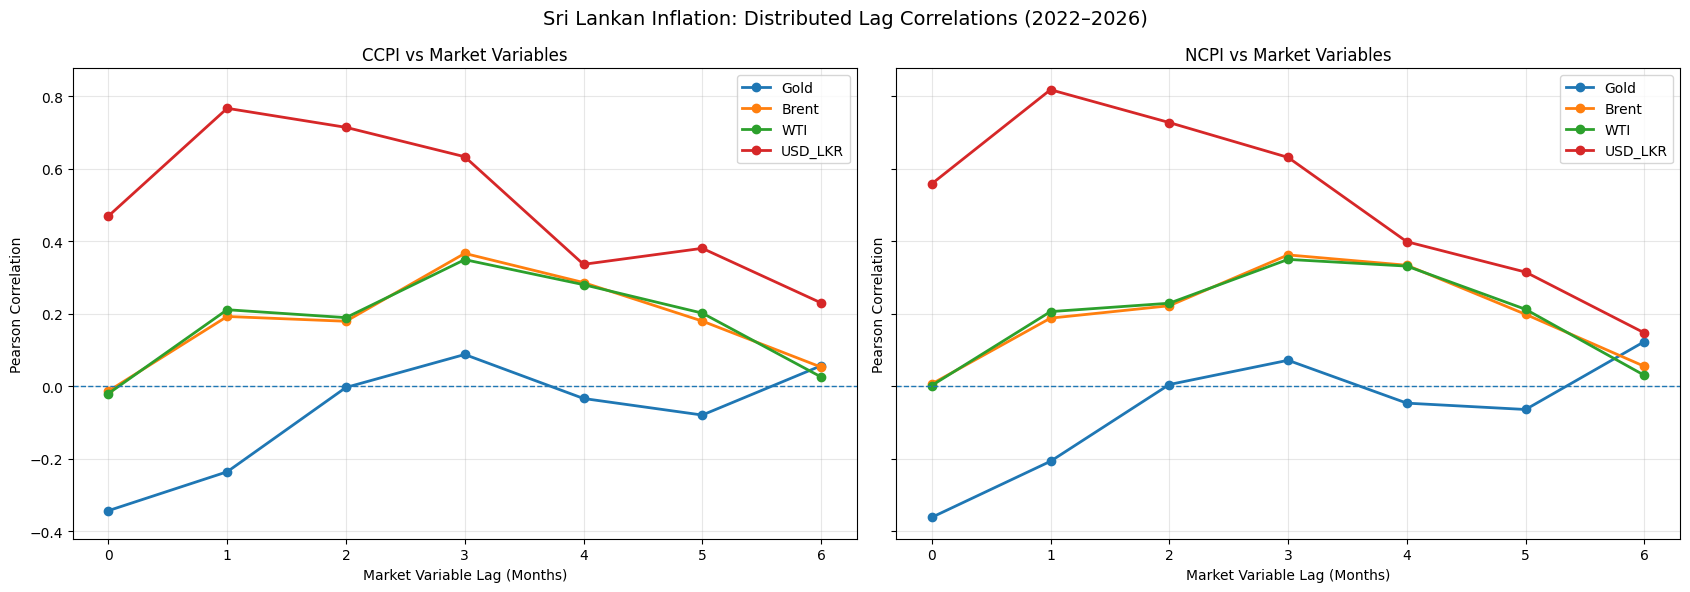


DISTRIBUTED LAG ANALYSIS COMPLETED
All lag results: 112 rows
Best-lag summaries: 16 rows

Saved files:
- /content/drive/MyDrive/Gold_Oil_Cost_of_Living/distributed_lag_correlations_0_6_months.csv
- /content/drive/MyDrive/Gold_Oil_Cost_of_Living/distributed_lag_best_correlations.csv

Read-back verification: PASSED


In [ ]:

# ============================================================
# CELL 47 — DISTRIBUTED LAG ANALYSIS (0–6 MONTHS)
# ============================================================

folder = "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"

input_file = os.path.join(
    folder,
    "sl_inflation_market_analysis_2022_2026.csv"
)

df = pd.read_csv(input_file)
df["Date"] = pd.to_datetime(df["Date"])

market_variables = [
    "Gold_MoM_Pct",
    "Brent_MoM_Pct",
    "WTI_MoM_Pct",
    "USD_LKR_MoM_Pct"
]

inflation_variables = [
    "CCPI_MoM_Pct",
    "NCPI_MoM_Pct"
]

required_columns = (
    ["Date"] + market_variables + inflation_variables
)

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

analysis_df = df[required_columns].copy()

# ------------------------------------------------------------
# 1. VALIDATE MONTHLY DATES
# ------------------------------------------------------------

analysis_df["Month"] = analysis_df["Date"].dt.to_period("M")

duplicate_months = analysis_df[
    analysis_df["Month"].duplicated(keep=False)
]["Month"].unique()

if len(duplicate_months) > 0:
    raise ValueError(
        f"Duplicate monthly records found: {duplicate_months}"
    )

analysis_df = analysis_df.drop(columns=["Date"])
analysis_df = analysis_df.set_index("Month").sort_index()

# Build a complete calendar without inventing observations.
complete_calendar = pd.period_range(
    start=analysis_df.index.min(),
    end=analysis_df.index.max(),
    freq="M"
)

missing_months = complete_calendar.difference(
    analysis_df.index
)

print("=" * 75)
print("DISTRIBUTED LAG ANALYSIS: 0–6 MONTHS")
print("=" * 75)

print(f"Original monthly records: {len(analysis_df)}")
print(f"Calendar months: {len(complete_calendar)}")
print(f"Missing calendar months: {len(missing_months)}")

if len(missing_months) > 0:
    print("\nMissing months:")
    for month in missing_months:
        print(f"- {month}")

# Reindex so that one row always represents one calendar month.
# Missing months remain NaN.
monthly_df = analysis_df.reindex(complete_calendar)

print(
    f"\nContinuous calendar: "
    f"{monthly_df.index.min()} to {monthly_df.index.max()}"
)


# ------------------------------------------------------------
# 2. DEFINE ANALYSIS PERIODS
# ------------------------------------------------------------

periods = {
    "Full period: 2022–2026": None,
    "Excluding 2022: 2023–2026": pd.Period("2023-01", freq="M")
}


# ------------------------------------------------------------
# 3. CALCULATE CORRELATIONS FOR EACH LAG
# ------------------------------------------------------------

lag_results = []

for period_name, period_start in periods.items():

    # Select the months being analysed as inflation outcomes.
    if period_start is None:
        target_df = monthly_df.copy()
    else:
        target_df = monthly_df[
            monthly_df.index >= period_start
        ].copy()

    for market_variable in market_variables:

        for inflation_variable in inflation_variables:

            for lag in range(0, 7):

                # Shift market movements by actual calendar months.
                # Positive lag means the market movement occurred
                # before the inflation movement.
                market_series = monthly_df[
                    market_variable
                ].shift(lag)

                inflation_series = monthly_df[
                    inflation_variable
                ]

                aligned_df = pd.DataFrame({
                    "Market": market_series.loc[target_df.index],
                    "Inflation": inflation_series.loc[target_df.index]
                }).dropna()

                observation_count = len(aligned_df)

                if observation_count < 10:
                    continue

                correlation = aligned_df["Market"].corr(
                    aligned_df["Inflation"]
                )

                lag_results.append({
                    "Period": period_name,
                    "Market Variable": market_variable,
                    "Inflation Variable": inflation_variable,
                    "Lag Months": lag,
                    "Observations": observation_count,
                    "Correlation": correlation
                })


lag_results_df = pd.DataFrame(lag_results)

print("\n" + "=" * 75)
print("CORRELATION RESULTS BY LAG")
print("=" * 75)

display(lag_results_df.round(4))


# ------------------------------------------------------------
# 4. FIND THE LARGEST ABSOLUTE CORRELATION
# ------------------------------------------------------------

best_lag_indices = (
    lag_results_df
    .groupby(
        ["Period", "Market Variable", "Inflation Variable"]
    )["Correlation"]
    .apply(lambda values: values.abs().idxmax())
)

best_lag_df = (
    lag_results_df.loc[best_lag_indices.values]
    .sort_values(
        ["Period", "Inflation Variable", "Market Variable"]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 75)
print("LARGEST ABSOLUTE CORRELATION WITHIN EACH LAG WINDOW")
print("=" * 75)

display(best_lag_df.round(4))


# ------------------------------------------------------------
# 5. VISUALISE FULL-PERIOD LAG RELATIONSHIPS
# ------------------------------------------------------------

full_period_results = lag_results_df[
    lag_results_df["Period"] == "Full period: 2022–2026"
]

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(17, 6),
    sharey=True
)

for ax, inflation_variable in zip(
    axes,
    inflation_variables
):

    plot_data = full_period_results[
        full_period_results["Inflation Variable"] == inflation_variable
    ]

    for market_variable in market_variables:

        series = plot_data[
            plot_data["Market Variable"] == market_variable
        ]

        ax.plot(
            series["Lag Months"],
            series["Correlation"],
            marker="o",
            linewidth=2,
            label=market_variable.replace("_MoM_Pct", "")
        )

    ax.axhline(y=0, linestyle="--", linewidth=1)

    ax.set_title(
        f"{inflation_variable.replace('_MoM_Pct', '')} "
        "vs Market Variables"
    )

    ax.set_xlabel("Market Variable Lag (Months)")
    ax.set_ylabel("Pearson Correlation")
    ax.set_xticks(range(0, 7))
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle(
    "Sri Lankan Inflation: Distributed Lag Correlations (2022–2026)",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

lag_output_file = os.path.join(
    folder,
    "distributed_lag_correlations_0_6_months.csv"
)

best_lag_output_file = os.path.join(
    folder,
    "distributed_lag_best_correlations.csv"
)

lag_results_df.to_csv(lag_output_file, index=False)
best_lag_df.to_csv(best_lag_output_file, index=False)


# ------------------------------------------------------------
# 7. VERIFY SAVED FILES
# ------------------------------------------------------------

verified_lags = pd.read_csv(lag_output_file)
verified_best = pd.read_csv(best_lag_output_file)

print("\n" + "=" * 75)
print("DISTRIBUTED LAG ANALYSIS COMPLETED")
print("=" * 75)

print(f"All lag results: {len(verified_lags)} rows")
print(f"Best-lag summaries: {len(verified_best)} rows")

print("\nSaved files:")
print(f"- {lag_output_file}")
print(f"- {best_lag_output_file}")

print("\nRead-back verification: PASSED")


# Task 4A — Monthly inflation association models

**Outcome variables:** monthly CCPI and NCPI changes; **explanatory variables:** observed monthly USD/LKR and Brent oil-price changes and alternative lag specifications as defined in the following cells. The notebooks also compare models including versus excluding 2022 because the crisis may have a disproportionate effect.

**Model design and choice:** Ordinary least squares gives interpretable conditional coefficient estimates for a limited monthly sample. Heteroskedasticity and autocorrelation consistent (HAC/Newey–West) standard errors support more cautious inference when short-run residual dependence is possible. HAC **does not** cure omitted-variable bias, simultaneity, incorrect functional form, measurement error or causal identification problems.

**Diagnostic pathway:** Cells 49–54 estimate coefficients, report confidence intervals/p-values and model fit, test residual assumptions, conduct influential-point sensitivity analysis, compare alternative one- and three-month Brent lags on matched observations and check variance inflation factors. Cells 56–59 visualise fitted relationships, residual patterns and consolidated findings.

**Decision rule:** Prefer language such as *'associated with'* or *'consistent with a delayed relationship'* rather than *'caused'*, *'proved'*, or *'transmission takes exactly three months'*. With lag exploration and multiple specifications, nominal p-values are descriptive rather than independent confirmatory tests.

Cell 48 — Prepare the regression dataset

In [ ]:

# ============================================================
# CELL 48: REGRESSION DATASET PREPARATION
# ============================================================

folder = "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"

input_file = os.path.join(
    folder,
    "sl_inflation_market_analysis_2022_2026.csv"
)

regression_df = pd.read_csv(input_file)

regression_df["Date"] = pd.to_datetime(
    regression_df["Date"]
)

regression_df = regression_df.sort_values(
    "Date"
).reset_index(drop=True)


# ------------------------------------------------------------
# 1. CREATE ONE-MONTH LAGGED EXPLANATORY VARIABLES
# ------------------------------------------------------------

regression_df["USD_LKR_Lag1"] = (
    regression_df["USD_LKR_MoM_Pct"].shift(1)
)

regression_df["Brent_Lag1"] = (
    regression_df["Brent_MoM_Pct"].shift(1)
)


# ------------------------------------------------------------
# 2. DEFINE THE REGRESSION VARIABLES
# ------------------------------------------------------------

predictors = [
    "USD_LKR_MoM_Pct",
    "USD_LKR_Lag1",
    "Brent_MoM_Pct",
    "Brent_Lag1"
]

dependent_variables = [
    "CCPI_MoM_Pct",
    "NCPI_MoM_Pct"
]

required_columns = (
    ["Date"] + predictors + dependent_variables
)

missing_columns = [
    column for column in required_columns
    if column not in regression_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ------------------------------------------------------------
# 3. CREATE COMPLETE REGRESSION DATASET
# ------------------------------------------------------------

model_df = regression_df[
    required_columns
].dropna().copy()

model_df = model_df.reset_index(drop=True)


# ------------------------------------------------------------
# 4. CREATE THE TWO ANALYSIS PERIODS
# ------------------------------------------------------------

model_full = model_df.copy()

model_post_2022 = model_df[
    model_df["Date"] >= "2023-01-01"
].copy()


# ------------------------------------------------------------
# 5. DISPLAY OBSERVATION COUNTS
# ------------------------------------------------------------

print("=" * 75)
print("REGRESSION DATASET VALIDATION")
print("=" * 75)

print(f"Original monthly records: {len(regression_df)}")

print(
    f"Complete regression observations: {len(model_full)}"
)

print(
    f"Post-2022 observations: {len(model_post_2022)}"
)

print(
    f"Full period: {model_full['Date'].min():%Y-%m} "
    f"to {model_full['Date'].max():%Y-%m}"
)

print(
    f"Post-2022 period: {model_post_2022['Date'].min():%Y-%m} "
    f"to {model_post_2022['Date'].max():%Y-%m}"
)


# ------------------------------------------------------------
# 6. CHECK MISSING VALUES
# ------------------------------------------------------------

print("\nMISSING VALUE CHECK")
print("-" * 75)

print(model_full[required_columns].isna().sum())


# ------------------------------------------------------------
# 7. CHECK DATA TYPES
# ------------------------------------------------------------

print("\nDATA TYPES")
print("-" * 75)

print(model_full.dtypes)


# ------------------------------------------------------------
# 8. DISPLAY DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

print("\nDESCRIPTIVE STATISTICS")
print("-" * 75)

display(
    model_full[predictors + dependent_variables]
    .describe()
    .round(4)
)


# ------------------------------------------------------------
# 9. SAVE REGRESSION DATASET
# ------------------------------------------------------------

output_file = os.path.join(
    folder,
    "regression_dataset_2022_2026.csv"
)

model_full.to_csv(
    output_file,
    index=False
)

# Read-back verification
verified_model = pd.read_csv(output_file)

assert len(verified_model) == len(model_full)

assert verified_model.isna().sum().sum() == 0

print("\n" + "=" * 75)
print("REGRESSION DATASET PREPARATION COMPLETED")
print("=" * 75)

print(f"Saved: {output_file}")
print(f"Verified observations: {len(verified_model)}")
print("Read-back verification: PASSED")


REGRESSION DATASET VALIDATION
Original monthly records: 57
Complete regression observations: 55
Post-2022 observations: 45
Full period: 2022-03 to 2026-09
Post-2022 period: 2023-01 to 2026-09

MISSING VALUE CHECK
---------------------------------------------------------------------------
Date               0
USD_LKR_MoM_Pct    0
USD_LKR_Lag1       0
Brent_MoM_Pct      0
Brent_Lag1         0
CCPI_MoM_Pct       0
NCPI_MoM_Pct       0
dtype: int64

DATA TYPES
---------------------------------------------------------------------------
Date               datetime64[ns]
USD_LKR_MoM_Pct           float64
USD_LKR_Lag1              float64
Brent_MoM_Pct             float64
Brent_Lag1                float64
CCPI_MoM_Pct              float64
NCPI_MoM_Pct              float64
dtype: object

DESCRIPTIVE STATISTICS
---------------------------------------------------------------------------


,USD_LKR_MoM_Pct,USD_LKR_Lag1,Brent_MoM_Pct,Brent_Lag1,CCPI_MoM_Pct,NCPI_MoM_Pct
count,55.0000,55.0000,55.0000,55.0000,55.0000,55.0000
mean,1.0467,1.0634,0.7721,0.5345,0.9578,0.9854
std,5.7165,5.7120,10.3218,9.8870,2.5223,2.5408
min,-9.5346,-9.5346,-20.2917,-20.2917,-1.9442,-2.0979
25%,-0.4081,-0.3341,-5.5188,-5.5188,-0.2360,-0.1701
50%,0.1801,0.1801,-0.6534,-0.6534,0.2407,0.2238
75%,0.7340,0.7340,6.4607,6.4607,0.9696,1.1478
max,28.2131,28.2131,45.4915,45.4915,11.7839,10.4880



REGRESSION DATASET PREPARATION COMPLETED
Saved: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/regression_dataset_2022_2026.csv
Verified observations: 55
Read-back verification: PASSED


## Cell 49 – Multiple Linear Regression Analysis

This cell estimates the relationship between monthly movements in the USD/LKR exchange rate, Brent crude oil prices, and Sri Lankan inflation.

Separate OLS regression models are estimated for CCPI and NCPI, using both the full observation period and a second period excluding 2022.

HAC (Newey–West) standard errors are used to make statistical inference more robust to heteroskedasticity and short-term autocorrelation.

The results include regression coefficients, robust standard errors, p-values, confidence intervals, and model fit statistics.

In [ ]:

# ============================================================
# CELL 49: OLS REGRESSION WITH HAC STANDARD ERRORS
# ============================================================

import statsmodels.api as sm


# ------------------------------------------------------------
# 1. DEFINE EXPLANATORY VARIABLES
# ------------------------------------------------------------

predictors = [
    "USD_LKR_MoM_Pct",
    "USD_LKR_Lag1",
    "Brent_MoM_Pct",
    "Brent_Lag1"
]


# ------------------------------------------------------------
# 2. DEFINE THE FOUR REGRESSION MODELS
# ------------------------------------------------------------

datasets = {
    "Full Period": model_full,
    "Excluding 2022": model_post_2022
}

outcomes = [
    "CCPI_MoM_Pct",
    "NCPI_MoM_Pct"
]


# ------------------------------------------------------------
# 3. FIT MODELS AND COLLECT RESULTS
# ------------------------------------------------------------

regression_results = []
fitted_models = {}

for period_name, period_df in datasets.items():

    for outcome in outcomes:

        X = period_df[predictors]

        y = period_df[outcome]

        # Add the intercept
        X = sm.add_constant(X, has_constant="add")

        # Fit OLS with HAC robust standard errors
        model = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": 1}
        )

        model_name = f"{outcome} - {period_name}"

        fitted_models[model_name] = model

        # Collect coefficient-level statistics
        confidence_intervals = model.conf_int()

        for variable in model.params.index:

            regression_results.append({
                "Model": model_name,
                "Period": period_name,
                "Outcome": outcome,
                "Variable": variable,
                "Coefficient": model.params[variable],
                "HAC_Std_Error": model.bse[variable],
                "P_Value": model.pvalues[variable],
                "CI_Lower": confidence_intervals.loc[
                    variable, 0
                ],
                "CI_Upper": confidence_intervals.loc[
                    variable, 1
                ],
                "R_Squared": model.rsquared,
                "Adjusted_R_Squared": model.rsquared_adj,
                "Observations": int(model.nobs)
            })


# ------------------------------------------------------------
# 4. DISPLAY MODEL FIT STATISTICS
# ------------------------------------------------------------

results_df = pd.DataFrame(regression_results)

model_summary = (
    results_df[
        [
            "Model",
            "R_Squared",
            "Adjusted_R_Squared",
            "Observations"
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("=" * 85)
print("REGRESSION MODEL FIT")
print("=" * 85)

display(model_summary.round(4))


# ------------------------------------------------------------
# 5. DISPLAY COEFFICIENT RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("REGRESSION COEFFICIENTS")
print("=" * 85)

display(
    results_df[
        [
            "Model",
            "Variable",
            "Coefficient",
            "HAC_Std_Error",
            "P_Value",
            "CI_Lower",
            "CI_Upper"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# 6. SAVE REGRESSION RESULTS
# ------------------------------------------------------------

output_file = os.path.join(
    folder,
    "ols_regression_hac_results.csv"
)

results_df.to_csv(
    output_file,
    index=False
)


# ------------------------------------------------------------
# 7. VERIFY SAVED RESULTS
# ------------------------------------------------------------

verified_results = pd.read_csv(output_file)

assert len(verified_results) == len(results_df)

assert verified_results.isna().sum().sum() == 0

print("\n" + "=" * 85)
print("OLS REGRESSION COMPLETED")
print("=" * 85)

print(f"Models estimated: {len(fitted_models)}")
print(f"Coefficient records: {len(results_df)}")
print(f"Saved: {output_file}")
print("Read-back verification: PASSED")


REGRESSION MODEL FIT


,Model,R_Squared,Adjusted_R_Squared,Observations
0,CCPI_MoM_Pct - Full Period,0.5961,0.5638,55
1,NCPI_MoM_Pct - Full Period,0.6811,0.6555,55
2,CCPI_MoM_Pct - Excluding 2022,0.2116,0.1327,45
3,NCPI_MoM_Pct - Excluding 2022,0.1574,0.0732,45



REGRESSION COEFFICIENTS


,Model,Variable,Coefficient,HAC_Std_Error,P_Value,CI_Lower,CI_Upper
0,CCPI_MoM_Pct - Full Period,const,0.5916,0.2370,0.0126,0.1270,1.0562
1,CCPI_MoM_Pct - Full Period,USD_LKR_MoM_Pct,-0.0029,0.0796,0.9706,-0.1589,0.1530
2,CCPI_MoM_Pct - Full Period,USD_LKR_Lag1,0.3349,0.0780,0.0000,0.1821,0.4878
3,CCPI_MoM_Pct - Full Period,Brent_MoM_Pct,0.0007,0.0165,0.9678,-0.0316,0.0330
4,CCPI_MoM_Pct - Full Period,Brent_Lag1,0.0235,0.0220,0.2847,-0.0196,0.0666
5,NCPI_MoM_Pct - Full Period,const,0.5731,0.2290,0.0123,0.1243,1.0219
6,NCPI_MoM_Pct - Full Period,USD_LKR_MoM_Pct,0.0396,0.0558,0.4774,-0.0697,0.1489
7,NCPI_MoM_Pct - Full Period,USD_LKR_Lag1,0.3374,0.0636,0.0000,0.2128,0.4620
8,NCPI_MoM_Pct - Full Period,Brent_MoM_Pct,0.0055,0.0152,0.7169,-0.0243,0.0353
9,NCPI_MoM_Pct - Full Period,Brent_Lag1,0.0146,0.0198,0.4604,-0.0242,0.0535



OLS REGRESSION COMPLETED
Models estimated: 4
Coefficient records: 20
Saved: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/ols_regression_hac_results.csv
Read-back verification: PASSED


## Cell 50 – Regression Diagnostic Tests

This cell evaluates the reliability of the four OLS regression models.

Diagnostic tests examine residual autocorrelation, heteroskedasticity, residual normality, and influential observations.

The results help identify potential weaknesses in the regression assumptions and determine whether individual months disproportionately influence the estimated relationships.

In [ ]:

# ============================================================
# CELL 50: REGRESSION DIAGNOSTICS
# ============================================================

from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_breuschpagan
)

from statsmodels.stats.stattools import (
    durbin_watson,
    jarque_bera
)


# ------------------------------------------------------------
# 1. PREPARE DIAGNOSTIC RESULTS
# ------------------------------------------------------------

diagnostic_results = []

influence_results = []


# ------------------------------------------------------------
# 2. RUN DIAGNOSTIC TESTS FOR EACH MODEL
# ------------------------------------------------------------

for period_name, period_df in datasets.items():

    for outcome in outcomes:

        model_name = f"{outcome} - {period_name}"

        model = fitted_models[model_name]

        residuals = model.resid

        # Durbin-Watson
        dw_stat = durbin_watson(residuals)

        # Ljung-Box tests at lags 1 and 3
        ljung_box = acorr_ljungbox(
            residuals,
            lags=[1, 3],
            return_df=True
        )

        # Breusch-Pagan test
        bp_lm, bp_lm_p, bp_f, bp_f_p = (
            het_breuschpagan(
                residuals,
                model.model.exog
            )
        )

        # Jarque-Bera test
        jb_stat, jb_p, skewness, kurtosis = (
            jarque_bera(residuals)
        )

        # Cook's distance
        influence = model.get_influence()

        cooks_distance = influence.cooks_distance[0]

        max_index = int(np.argmax(cooks_distance))

        max_cooks = float(cooks_distance[max_index])

        influence_threshold = 4 / len(period_df)

        influential_date = period_df["Date"].iloc[
            max_index
        ]

        # Store diagnostic results
        diagnostic_results.append({
            "Model": model_name,
            "Observations": int(model.nobs),
            "Durbin_Watson": dw_stat,
            "Ljung_Box_Lag1_P": ljung_box.loc[1, "lb_pvalue"],
            "Ljung_Box_Lag3_P": ljung_box.loc[3, "lb_pvalue"],
            "Breusch_Pagan_P": bp_lm_p,
            "Jarque_Bera_P": jb_p,
            "Residual_Skewness": skewness,
            "Residual_Kurtosis": kurtosis
        })

        # Store influential observation
        influence_results.append({
            "Model": model_name,
            "Most_Influential_Month": influential_date,
            "Maximum_Cooks_Distance": max_cooks,
            "Influence_Threshold_4_over_n": influence_threshold,
            "Exceeds_Threshold": max_cooks > influence_threshold
        })


# ------------------------------------------------------------
# 3. DISPLAY DIAGNOSTIC TEST RESULTS
# ------------------------------------------------------------

diagnostics_df = pd.DataFrame(
    diagnostic_results
)

print("=" * 100)
print("REGRESSION DIAGNOSTIC TESTS")
print("=" * 100)

display(
    diagnostics_df.round(4)
)


# ------------------------------------------------------------
# 4. DISPLAY INFLUENTIAL OBSERVATIONS
# ------------------------------------------------------------

influence_df = pd.DataFrame(
    influence_results
)

print("\n" + "=" * 100)
print("INFLUENTIAL OBSERVATIONS")
print("=" * 100)

display(
    influence_df.round(4)
)


# ------------------------------------------------------------
# 5. SAVE DIAGNOSTIC RESULTS
# ------------------------------------------------------------

diagnostic_file = os.path.join(
    folder,
    "regression_diagnostic_results.csv"
)

influence_file = os.path.join(
    folder,
    "regression_influential_observations.csv"
)

diagnostics_df.to_csv(
    diagnostic_file,
    index=False
)

influence_df.to_csv(
    influence_file,
    index=False
)


# ------------------------------------------------------------
# 6. VERIFY SAVED FILES
# ------------------------------------------------------------

verified_diagnostics = pd.read_csv(
    diagnostic_file
)

verified_influence = pd.read_csv(
    influence_file
)

assert len(verified_diagnostics) == 4
assert len(verified_influence) == 4

assert not verified_diagnostics.isna().any().any()
assert not verified_influence.isna().any().any()

print("\n" + "=" * 100)
print("REGRESSION DIAGNOSTICS COMPLETED")
print("=" * 100)

print(f"Diagnostics: {diagnostic_file}")
print(f"Influence results: {influence_file}")
print("Read-back verification: PASSED")


REGRESSION DIAGNOSTIC TESTS


,Model,Observations,Durbin_Watson,Ljung_Box_Lag1_P,Ljung_Box_Lag3_P,Breusch_Pagan_P,Jarque_Bera_P,Residual_Skewness,Residual_Kurtosis
0,CCPI_MoM_Pct - Full Period,55,1.3824,0.0274,0.0571,0.1724,0.0000,1.9816,9.2269
1,NCPI_MoM_Pct - Full Period,55,1.0498,0.0004,0.0044,0.2628,0.0000,1.7996,7.9699
2,CCPI_MoM_Pct - Excluding 2022,45,1.6834,0.2792,0.4279,0.0787,0.4851,0.1955,3.7866
3,NCPI_MoM_Pct - Excluding 2022,45,1.3806,0.0337,0.0881,0.6830,0.1094,0.4742,4.2087



INFLUENTIAL OBSERVATIONS


,Model,Most_Influential_Month,Maximum_Cooks_Distance,Influence_Threshold_4_over_n,Exceeds_Threshold
0,CCPI_MoM_Pct - Full Period,2022-03-01,3.2608,0.0727,True
1,NCPI_MoM_Pct - Full Period,2022-03-01,1.3666,0.0727,True
2,CCPI_MoM_Pct - Excluding 2022,2026-04-01,1.9683,0.0889,True
3,NCPI_MoM_Pct - Excluding 2022,2026-04-01,1.6656,0.0889,True



REGRESSION DIAGNOSTICS COMPLETED
Diagnostics: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/regression_diagnostic_results.csv
Influence results: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/regression_influential_observations.csv
Read-back verification: PASSED


## Cell 51 – Regression Sensitivity Analysis

This cell evaluates whether the regression coefficients remain stable under alternative statistical specifications.

Three specifications are compared:

1. Original regression with HAC standard errors using one lag.
2. Original regression with HAC standard errors using three lags.
3. Regression excluding the most influential observation, using HAC standard errors with three lags.

The analysis compares coefficient estimates and p-values to determine whether the findings depend heavily on individual observations or the HAC lag setting.

Influential observations are excluded only for this sensitivity test, not from the original dataset.

In [ ]:

# ============================================================
# CELL 51: REGRESSION SENSITIVITY ANALYSIS
# ============================================================


# ------------------------------------------------------------
# 1. IDENTIFY THE MOST INFLUENTIAL MONTH IN EACH PERIOD
# ------------------------------------------------------------

influential_dates = {
    "Full Period": pd.Timestamp("2022-03-01"),
    "Excluding 2022": pd.Timestamp("2026-04-01")
}


# ------------------------------------------------------------
# 2. PREPARE RESULTS
# ------------------------------------------------------------

sensitivity_results = []


# ------------------------------------------------------------
# 3. COMPARE THREE MODEL SPECIFICATIONS
# ------------------------------------------------------------

for period_name, period_df in datasets.items():

    influential_date = influential_dates[period_name]

    for outcome in outcomes:

        model_name = f"{outcome} - {period_name}"

        # Original model: HAC lag 1
        original_model = fitted_models[model_name]

        specifications = [
            {
                "Specification": "Original HAC 1",
                "Model": original_model
            }
        ]

        # Refit original observations with HAC lag 3
        X = sm.add_constant(
            period_df[predictors],
            has_constant="add"
        )

        y = period_df[outcome]

        hac3_model = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": 3}
        )

        specifications.append({
            "Specification": "Original HAC 3",
            "Model": hac3_model
        })

        # Exclude the most influential observation
        sensitivity_df = period_df[
            period_df["Date"] != influential_date
        ].copy()

        X_sensitivity = sm.add_constant(
            sensitivity_df[predictors],
            has_constant="add"
        )

        y_sensitivity = sensitivity_df[outcome]

        excluded_model = sm.OLS(
            y_sensitivity,
            X_sensitivity
        ).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": 3}
        )

        specifications.append({
            "Specification": (
                f"Excluding {influential_date:%Y-%m} - HAC 3"
            ),
            "Model": excluded_model
        })

        # Collect all coefficient results
        for specification in specifications:

            fitted_model = specification["Model"]

            confidence_intervals = fitted_model.conf_int()

            for variable in fitted_model.params.index:

                sensitivity_results.append({
                    "Model": model_name,
                    "Specification": specification["Specification"],
                    "Variable": variable,
                    "Coefficient": fitted_model.params[variable],
                    "Std_Error": fitted_model.bse[variable],
                    "P_Value": fitted_model.pvalues[variable],
                    "CI_Lower": confidence_intervals.loc[
                        variable, 0
                    ],
                    "CI_Upper": confidence_intervals.loc[
                        variable, 1
                    ],
                    "R_Squared": fitted_model.rsquared,
                    "Observations": int(fitted_model.nobs)
                })


# ------------------------------------------------------------
# 4. CREATE RESULTS DATAFRAME
# ------------------------------------------------------------

sensitivity_df = pd.DataFrame(
    sensitivity_results
)


# ------------------------------------------------------------
# 5. DISPLAY EXPLANATORY VARIABLE RESULTS
# ------------------------------------------------------------

print("=" * 100)
print("REGRESSION SENSITIVITY ANALYSIS")
print("=" * 100)

display(
    sensitivity_df[
        sensitivity_df["Variable"] != "const"
    ][
        [
            "Model",
            "Specification",
            "Variable",
            "Coefficient",
            "Std_Error",
            "P_Value",
            "CI_Lower",
            "CI_Upper",
            "R_Squared",
            "Observations"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

output_file = os.path.join(
    folder,
    "regression_sensitivity_analysis.csv"
)

sensitivity_df.to_csv(
    output_file,
    index=False
)


# ------------------------------------------------------------
# 7. VERIFY SAVED RESULTS
# ------------------------------------------------------------

verified_sensitivity = pd.read_csv(
    output_file
)

assert len(verified_sensitivity) == len(sensitivity_df)

assert not verified_sensitivity.isna().any().any()

print("\n" + "=" * 100)
print("SENSITIVITY ANALYSIS COMPLETED")
print("=" * 100)

print(f"Specifications tested: 3 per model")
print(f"Models evaluated: 4")
print(f"Coefficient records: {len(sensitivity_df)}")
print(f"Saved: {output_file}")
print("Read-back verification: PASSED")


REGRESSION SENSITIVITY ANALYSIS


,Model,Specification,Variable,Coefficient,Std_Error,P_Value,CI_Lower,CI_Upper,R_Squared,Observations
1,CCPI_MoM_Pct - Full Period,Original HAC 1,USD_LKR_MoM_Pct,-0.0029,0.0796,0.9706,-0.1589,0.1530,0.5961,55
2,CCPI_MoM_Pct - Full Period,Original HAC 1,USD_LKR_Lag1,0.3349,0.0780,0.0000,0.1821,0.4878,0.5961,55
3,CCPI_MoM_Pct - Full Period,Original HAC 1,Brent_MoM_Pct,0.0007,0.0165,0.9678,-0.0316,0.0330,0.5961,55
4,CCPI_MoM_Pct - Full Period,Original HAC 1,Brent_Lag1,0.0235,0.0220,0.2847,-0.0196,0.0666,0.5961,55
6,CCPI_MoM_Pct - Full Period,Original HAC 3,USD_LKR_MoM_Pct,-0.0029,0.0691,0.9662,-0.1384,0.1326,0.5961,55
7,CCPI_MoM_Pct - Full Period,Original HAC 3,USD_LKR_Lag1,0.3349,0.0634,0.0000,0.2107,0.4592,0.5961,55
8,CCPI_MoM_Pct - Full Period,Original HAC 3,Brent_MoM_Pct,0.0007,0.0159,0.9667,-0.0306,0.0319,0.5961,55
9,CCPI_MoM_Pct - Full Period,Original HAC 3,Brent_Lag1,0.0235,0.0205,0.2503,-0.0166,0.0636,0.5961,55
11,CCPI_MoM_Pct - Full Period,Excluding 2022-03 - HAC 3,USD_LKR_MoM_Pct,-0.1952,0.1164,0.0936,-0.4233,0.0329,0.6444,54
12,CCPI_MoM_Pct - Full Period,Excluding 2022-03 - HAC 3,USD_LKR_Lag1,0.4513,0.0904,0.0000,0.2742,0.6285,0.6444,54



SENSITIVITY ANALYSIS COMPLETED
Specifications tested: 3 per model
Models evaluated: 4
Coefficient records: 60
Saved: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/regression_sensitivity_analysis.csv
Read-back verification: PASSED


## Cell 52 – Three-Month Brent Oil Lag Regression

Previous exploratory analysis suggested that Brent crude oil price changes may have a stronger association with Sri Lankan inflation after approximately three months.

This cell tests that possibility by replacing the one-month Brent lag with a three-month lag.

The exchange-rate variables remain unchanged. Separate CCPI and NCPI models are estimated for the full period and the period excluding 2022.

HAC standard errors with three lags are used. The three-month lag is exploratory and should not be interpreted as a confirmed economic transmission period.

In [ ]:

# ============================================================
# CELL 52: THREE-MONTH BRENT LAG REGRESSION
# ============================================================


# ------------------------------------------------------------
# 1. CREATE THREE-MONTH LAGGED BRENT VARIABLE
# ------------------------------------------------------------

lag3_df = regression_df.copy()

lag3_df["Brent_Lag3"] = (
    lag3_df["Brent_MoM_Pct"].shift(3)
)


# ------------------------------------------------------------
# 2. DEFINE MODEL VARIABLES
# ------------------------------------------------------------

lag3_predictors = [
    "USD_LKR_MoM_Pct",
    "USD_LKR_Lag1",
    "Brent_MoM_Pct",
    "Brent_Lag3"
]

lag3_outcomes = [
    "CCPI_MoM_Pct",
    "NCPI_MoM_Pct"
]

required_columns = (
    ["Date"] + lag3_predictors + lag3_outcomes
)


# ------------------------------------------------------------
# 3. CREATE COMPLETE DATASET
# ------------------------------------------------------------

lag3_model_df = (
    lag3_df[required_columns]
    .dropna()
    .copy()
    .reset_index(drop=True)
)

lag3_full = lag3_model_df.copy()

lag3_post_2022 = lag3_model_df[
    lag3_model_df["Date"] >= "2023-01-01"
].copy()


# ------------------------------------------------------------
# 4. VALIDATE OBSERVATION COUNTS
# ------------------------------------------------------------

print("=" * 85)
print("THREE-MONTH LAG DATASET VALIDATION")
print("=" * 85)

print(f"Complete observations: {len(lag3_full)}")
print(f"Post-2022 observations: {len(lag3_post_2022)}")

print(
    f"Full period: {lag3_full['Date'].min():%Y-%m} "
    f"to {lag3_full['Date'].max():%Y-%m}"
)

print(
    f"Post-2022 period: {lag3_post_2022['Date'].min():%Y-%m} "
    f"to {lag3_post_2022['Date'].max():%Y-%m}"
)

assert lag3_full.isna().sum().sum() == 0


# ------------------------------------------------------------
# 5. ESTIMATE FOUR REGRESSION MODELS
# ------------------------------------------------------------

lag3_datasets = {
    "Full Period": lag3_full,
    "Excluding 2022": lag3_post_2022
}

lag3_fitted_models = {}

lag3_results = []

for period_name, period_df in lag3_datasets.items():

    for outcome in lag3_outcomes:

        X = sm.add_constant(
            period_df[lag3_predictors],
            has_constant="add"
        )

        y = period_df[outcome]

        model = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": 3}
        )

        model_name = f"{outcome} - {period_name}"

        lag3_fitted_models[model_name] = model

        confidence_intervals = model.conf_int()

        for variable in model.params.index:

            lag3_results.append({
                "Model": model_name,
                "Period": period_name,
                "Outcome": outcome,
                "Variable": variable,
                "Coefficient": model.params[variable],
                "HAC_Std_Error": model.bse[variable],
                "P_Value": model.pvalues[variable],
                "CI_Lower": confidence_intervals.loc[
                    variable, 0
                ],
                "CI_Upper": confidence_intervals.loc[
                    variable, 1
                ],
                "R_Squared": model.rsquared,
                "Adjusted_R_Squared": model.rsquared_adj,
                "Observations": int(model.nobs)
            })


# ------------------------------------------------------------
# 6. DISPLAY MODEL FIT
# ------------------------------------------------------------

lag3_results_df = pd.DataFrame(lag3_results)

print("\n" + "=" * 85)
print("THREE-MONTH LAG MODEL FIT")
print("=" * 85)

display(
    lag3_results_df[
        [
            "Model",
            "R_Squared",
            "Adjusted_R_Squared",
            "Observations"
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
    .round(4)
)


# ------------------------------------------------------------
# 7. DISPLAY COEFFICIENT RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("THREE-MONTH LAG REGRESSION COEFFICIENTS")
print("=" * 85)

display(
    lag3_results_df[
        [
            "Model",
            "Variable",
            "Coefficient",
            "HAC_Std_Error",
            "P_Value",
            "CI_Lower",
            "CI_Upper"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

output_file = os.path.join(
    folder,
    "ols_regression_brent_lag3_results.csv"
)

lag3_results_df.to_csv(
    output_file,
    index=False
)


# ------------------------------------------------------------
# 9. VERIFY SAVED RESULTS
# ------------------------------------------------------------

verified_lag3 = pd.read_csv(output_file)

assert len(verified_lag3) == len(lag3_results_df)
assert not verified_lag3.isna().any().any()

print("\n" + "=" * 85)
print("THREE-MONTH LAG REGRESSION COMPLETED")
print("=" * 85)

print(f"Models estimated: {len(lag3_fitted_models)}")
print(f"Coefficient records: {len(lag3_results_df)}")
print(f"Saved: {output_file}")
print("Read-back verification: PASSED")


THREE-MONTH LAG DATASET VALIDATION
Complete observations: 53
Post-2022 observations: 45
Full period: 2022-05 to 2026-09
Post-2022 period: 2023-01 to 2026-09

THREE-MONTH LAG MODEL FIT


,Model,R_Squared,Adjusted_R_Squared,Observations
0,CCPI_MoM_Pct - Full Period,0.5849,0.5503,53
1,NCPI_MoM_Pct - Full Period,0.6009,0.5677,53
2,CCPI_MoM_Pct - Excluding 2022,0.2608,0.1869,45
3,NCPI_MoM_Pct - Excluding 2022,0.2061,0.1267,45



THREE-MONTH LAG REGRESSION COEFFICIENTS


,Model,Variable,Coefficient,HAC_Std_Error,P_Value,CI_Lower,CI_Upper
0,CCPI_MoM_Pct - Full Period,const,0.4949,0.2186,0.0236,0.0665,0.9232
1,CCPI_MoM_Pct - Full Period,USD_LKR_MoM_Pct,-0.3196,0.1319,0.0154,-0.5780,-0.0612
2,CCPI_MoM_Pct - Full Period,USD_LKR_Lag1,0.4278,0.0737,0.0000,0.2834,0.5722
3,CCPI_MoM_Pct - Full Period,Brent_MoM_Pct,0.0154,0.0161,0.3408,-0.0163,0.0470
4,CCPI_MoM_Pct - Full Period,Brent_Lag3,0.0571,0.0268,0.0331,0.0046,0.1097
5,NCPI_MoM_Pct - Full Period,const,0.5207,0.2269,0.0218,0.0759,0.9654
6,NCPI_MoM_Pct - Full Period,USD_LKR_MoM_Pct,-0.1225,0.1056,0.2460,-0.3295,0.0845
7,NCPI_MoM_Pct - Full Period,USD_LKR_Lag1,0.3877,0.0728,0.0000,0.2450,0.5305
8,NCPI_MoM_Pct - Full Period,Brent_MoM_Pct,0.0153,0.0155,0.3225,-0.0150,0.0457
9,NCPI_MoM_Pct - Full Period,Brent_Lag3,0.0413,0.0242,0.0882,-0.0062,0.0887



THREE-MONTH LAG REGRESSION COMPLETED
Models estimated: 4
Coefficient records: 20
Saved: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/ols_regression_brent_lag3_results.csv
Read-back verification: PASSED


## Cell 53 – Comparing One-Month and Three-Month Brent Lags

This cell compares alternative Brent crude oil lag specifications using identical observations and explanatory variables.

The models differ only in whether the Brent price change is measured one month or three months before the inflation observation.

The comparison uses adjusted R-squared, AIC, BIC, and HAC-adjusted coefficient estimates.

Using identical observations ensures that differences in model fit are not caused by different sample sizes or date coverage.

This comparison is exploratory and does not establish a causal oil-price transmission period.

In [ ]:

# ============================================================
# CELL 53: ONE-MONTH VS THREE-MONTH BRENT LAG COMPARISON
# ============================================================


# ------------------------------------------------------------
# 1. CREATE A COMMON DATASET FOR BOTH LAG SPECIFICATIONS
# ------------------------------------------------------------

comparison_columns = [
    "Date",
    "USD_LKR_MoM_Pct",
    "USD_LKR_Lag1",
    "Brent_MoM_Pct",
    "Brent_Lag1",
    "Brent_Lag3",
    "CCPI_MoM_Pct",
    "NCPI_MoM_Pct"
]

comparison_df = (
    lag3_df[comparison_columns]
    .dropna()
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. DEFINE COMPARISON PERIODS
# ------------------------------------------------------------

comparison_datasets = {
    "Full Comparable Period": comparison_df,
    "Excluding 2022": comparison_df[
        comparison_df["Date"] >= "2023-01-01"
    ].copy()
}


# ------------------------------------------------------------
# 3. DEFINE THE TWO BRENT SPECIFICATIONS
# ------------------------------------------------------------

brent_specifications = {
    "Brent Lag 1": [
        "USD_LKR_MoM_Pct",
        "USD_LKR_Lag1",
        "Brent_MoM_Pct",
        "Brent_Lag1"
    ],
    "Brent Lag 3": [
        "USD_LKR_MoM_Pct",
        "USD_LKR_Lag1",
        "Brent_MoM_Pct",
        "Brent_Lag3"
    ]
}


# ------------------------------------------------------------
# 4. VALIDATE COMMON SAMPLE
# ------------------------------------------------------------

print("=" * 90)
print("COMMON SAMPLE VALIDATION")
print("=" * 90)

print(f"Comparable observations: {len(comparison_df)}")

print(
    f"Full comparable period: "
    f"{comparison_df['Date'].min():%Y-%m} "
    f"to {comparison_df['Date'].max():%Y-%m}"
)

print(
    f"Post-2022 observations: "
    f"{len(comparison_datasets['Excluding 2022'])}"
)

assert comparison_df.isna().sum().sum() == 0


# ------------------------------------------------------------
# 5. FIT AND COMPARE THE MODELS
# ------------------------------------------------------------

comparison_results = []

comparison_coefficients = []

for period_name, period_df in comparison_datasets.items():

    for outcome in ["CCPI_MoM_Pct", "NCPI_MoM_Pct"]:

        for specification_name, predictors_used in (
            brent_specifications.items()
        ):

            X = sm.add_constant(
                period_df[predictors_used],
                has_constant="add"
            )

            y = period_df[outcome]

            model = sm.OLS(y, X).fit(
                cov_type="HAC",
                cov_kwds={"maxlags": 3}
            )

            model_name = (
                f"{outcome} - {period_name} - "
                f"{specification_name}"
            )

            comparison_results.append({
                "Period": period_name,
                "Outcome": outcome,
                "Brent_Specification": specification_name,
                "Observations": int(model.nobs),
                "R_Squared": model.rsquared,
                "Adjusted_R_Squared": model.rsquared_adj,
                "AIC": model.aic,
                "BIC": model.bic
            })

            for variable in model.params.index:

                comparison_coefficients.append({
                    "Model": model_name,
                    "Period": period_name,
                    "Outcome": outcome,
                    "Brent_Specification": specification_name,
                    "Variable": variable,
                    "Coefficient": model.params[variable],
                    "HAC_Std_Error": model.bse[variable],
                    "P_Value": model.pvalues[variable]
                })


# ------------------------------------------------------------
# 6. DISPLAY MODEL FIT COMPARISON
# ------------------------------------------------------------

comparison_results_df = pd.DataFrame(
    comparison_results
)

print("\n" + "=" * 90)
print("MODEL FIT COMPARISON")
print("=" * 90)

display(
    comparison_results_df.round(4)
)


# ------------------------------------------------------------
# 7. DISPLAY BRENT COEFFICIENT COMPARISON
# ------------------------------------------------------------

comparison_coefficients_df = pd.DataFrame(
    comparison_coefficients
)

brent_coefficients_df = comparison_coefficients_df[
    comparison_coefficients_df["Variable"].isin(
        ["Brent_Lag1", "Brent_Lag3"]
    )
]

print("\n" + "=" * 90)
print("BRENT LAG COEFFICIENT COMPARISON")
print("=" * 90)

display(
    brent_coefficients_df[
        [
            "Period",
            "Outcome",
            "Brent_Specification",
            "Variable",
            "Coefficient",
            "HAC_Std_Error",
            "P_Value"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# 8. SAVE BOTH RESULT TABLES
# ------------------------------------------------------------

fit_file = os.path.join(
    folder,
    "brent_lag_model_fit_comparison.csv"
)

coefficient_file = os.path.join(
    folder,
    "brent_lag_coefficient_comparison.csv"
)

comparison_results_df.to_csv(
    fit_file,
    index=False
)

comparison_coefficients_df.to_csv(
    coefficient_file,
    index=False
)


# ------------------------------------------------------------
# 9. VERIFY SAVED RESULTS
# ------------------------------------------------------------

verified_fit = pd.read_csv(fit_file)

verified_coefficients = pd.read_csv(coefficient_file)

assert len(verified_fit) == len(comparison_results_df)
assert len(verified_coefficients) == len(comparison_coefficients_df)

assert not verified_fit.isna().any().any()
assert not verified_coefficients.isna().any().any()

print("\n" + "=" * 90)
print("BRENT LAG COMPARISON COMPLETED")
print("=" * 90)

print(f"Models compared: {len(comparison_results_df)}")
print(f"Coefficient records: {len(comparison_coefficients_df)}")
print(f"Model fit file: {fit_file}")
print(f"Coefficient file: {coefficient_file}")
print("Read-back verification: PASSED")


COMMON SAMPLE VALIDATION
Comparable observations: 53
Full comparable period: 2022-05 to 2026-09
Post-2022 observations: 45

MODEL FIT COMPARISON


,Period,Outcome,Brent_Specification,Observations,R_Squared,Adjusted_R_Squared,AIC,BIC
0,Full Comparable Period,CCPI_MoM_Pct,Brent Lag 1,53,0.5472,0.5095,203.2602,213.1117
1,Full Comparable Period,CCPI_MoM_Pct,Brent Lag 3,53,0.5849,0.5503,198.6582,208.5097
2,Full Comparable Period,NCPI_MoM_Pct,Brent Lag 1,53,0.5802,0.5452,196.6729,206.5244
3,Full Comparable Period,NCPI_MoM_Pct,Brent Lag 3,53,0.6009,0.5677,193.9854,203.8368
4,Excluding 2022,CCPI_MoM_Pct,Brent Lag 1,45,0.2116,0.1327,131.8397,140.8730
5,Excluding 2022,CCPI_MoM_Pct,Brent Lag 3,45,0.2608,0.1869,128.9387,137.9720
6,Excluding 2022,NCPI_MoM_Pct,Brent Lag 1,45,0.1574,0.0732,125.3097,134.3430
7,Excluding 2022,NCPI_MoM_Pct,Brent Lag 3,45,0.2061,0.1267,122.6327,131.6660



BRENT LAG COEFFICIENT COMPARISON


,Period,Outcome,Brent_Specification,Variable,Coefficient,HAC_Std_Error,P_Value
4,Full Comparable Period,CCPI_MoM_Pct,Brent Lag 1,Brent_Lag1,0.0259,0.0264,0.3253
9,Full Comparable Period,CCPI_MoM_Pct,Brent Lag 3,Brent_Lag3,0.0571,0.0268,0.0331
14,Full Comparable Period,NCPI_MoM_Pct,Brent Lag 1,Brent_Lag1,0.0185,0.0239,0.4387
19,Full Comparable Period,NCPI_MoM_Pct,Brent Lag 3,Brent_Lag3,0.0413,0.0242,0.0882
24,Excluding 2022,CCPI_MoM_Pct,Brent Lag 1,Brent_Lag1,0.0135,0.0250,0.5897
29,Excluding 2022,CCPI_MoM_Pct,Brent Lag 3,Brent_Lag3,0.0341,0.0112,0.0024
34,Excluding 2022,NCPI_MoM_Pct,Brent Lag 1,Brent_Lag1,0.0053,0.0221,0.8107
39,Excluding 2022,NCPI_MoM_Pct,Brent Lag 3,Brent_Lag3,0.0277,0.0092,0.0027



BRENT LAG COMPARISON COMPLETED
Models compared: 8
Coefficient records: 40
Model fit file: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/brent_lag_model_fit_comparison.csv
Coefficient file: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/brent_lag_coefficient_comparison.csv
Read-back verification: PASSED


### Cell 54 — Multicollinearity Diagnostics (VIF)

This cell calculates the Variance Inflation Factor (VIF) for the predictors used in the Brent lag-1 and lag-3 regression models.

VIF measures how much the variance of a regression coefficient is inflated because of relationships between independent variables.

This helps identify whether multicollinearity could be affecting the stability and interpretation of our regression coefficients.

In [ ]:

from statsmodels.stats.outliers_influence import variance_inflation_factor

print("=" * 90)
print("MULTICOLLINEARITY DIAGNOSTICS — VIF")
print("=" * 90)

vif_records = []

# The same samples used in Cell 53
periods = {
    "Full Comparable Period": comparison_df.copy(),
    "Excluding 2022": comparison_df[
        comparison_df["Date"] >= "2023-01-01"
    ].copy()
}

brent_specifications = {
    "Brent Lag 1": [
        "USD_LKR_MoM_Pct",
        "USD_LKR_Lag1",
        "Brent_MoM_Pct",
        "Brent_Lag1"
    ],
    "Brent Lag 3": [
        "USD_LKR_MoM_Pct",
        "USD_LKR_Lag1",
        "Brent_MoM_Pct",
        "Brent_Lag3"
    ]
}

for period_name, period_df in periods.items():

    for specification, predictors in brent_specifications.items():

        X = period_df[predictors].copy()

        # Add an intercept for the VIF calculation.
        X = sm.add_constant(X)

        for index, variable in enumerate(X.columns):

            if variable == "const":
                continue

            vif_value = variance_inflation_factor(
                X.values,
                index
            )

            vif_records.append({
                "Period": period_name,
                "Brent_Specification": specification,
                "Variable": variable,
                "VIF": vif_value
            })

vif_df = pd.DataFrame(vif_records)

# Add a simple interpretation category.
def classify_vif(value):
    if value >= 10:
        return "High multicollinearity"
    elif value >= 5:
        return "Moderate multicollinearity"
    else:
        return "Generally acceptable"

vif_df["Assessment"] = vif_df["VIF"].apply(classify_vif)

print("\n" + "=" * 90)
print("VIF RESULTS")
print("=" * 90)

display(
    vif_df.round(4)
)

print("\n" + "=" * 90)
print("MAXIMUM VIF BY MODEL")
print("=" * 90)

max_vif_df = (
    vif_df
    .groupby(["Period", "Brent_Specification"])["VIF"]
    .max()
    .reset_index(name="Maximum_VIF")
)

display(max_vif_df.round(4))

# Save VIF results using the known project directory.
project_folder = "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"
# Save results
vif_path = os.path.join(
    project_folder,
    "regression_vif_diagnostics.csv"
)

vif_df.to_csv(vif_path, index=False)

# Verify saved file
vif_check = pd.read_csv(vif_path)

print("\n" + "=" * 90)
print("VIF DIAGNOSTICS COMPLETED")
print("=" * 90)

print("VIF records:", len(vif_df))
print("Saved file:", vif_path)
print("Read-back verification:", "PASSED" if len(vif_check) == len(vif_df) else "FAILED")


MULTICOLLINEARITY DIAGNOSTICS — VIF

VIF RESULTS


,Period,Brent_Specification,Variable,VIF,Assessment
0,Full Comparable Period,Brent Lag 1,USD_LKR_MoM_Pct,1.6552,Generally acceptable
1,Full Comparable Period,Brent Lag 1,USD_LKR_Lag1,1.6601,Generally acceptable
2,Full Comparable Period,Brent Lag 1,Brent_MoM_Pct,1.0859,Generally acceptable
3,Full Comparable Period,Brent Lag 1,Brent_Lag1,1.0822,Generally acceptable
4,Full Comparable Period,Brent Lag 3,USD_LKR_MoM_Pct,1.7810,Generally acceptable
5,Full Comparable Period,Brent Lag 3,USD_LKR_Lag1,1.6790,Generally acceptable
6,Full Comparable Period,Brent Lag 3,Brent_MoM_Pct,1.1363,Generally acceptable
7,Full Comparable Period,Brent Lag 3,Brent_Lag3,1.3252,Generally acceptable
8,Excluding 2022,Brent Lag 1,USD_LKR_MoM_Pct,1.1447,Generally acceptable
9,Excluding 2022,Brent Lag 1,USD_LKR_Lag1,1.1584,Generally acceptable



MAXIMUM VIF BY MODEL


,Period,Brent_Specification,Maximum_VIF
0,Excluding 2022,Brent Lag 1,1.1584
1,Excluding 2022,Brent Lag 3,1.5066
2,Full Comparable Period,Brent Lag 1,1.6601
3,Full Comparable Period,Brent Lag 3,1.7810



VIF DIAGNOSTICS COMPLETED
VIF records: 16
Saved file: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/regression_vif_diagnostics.csv
Read-back verification: PASSED


### Cell 55 — Economic Trend Visualisations (2022–2026)

This cell visualises the historical movements of key international market indicators and Sri Lankan inflation.

Four separate time-series charts are generated:

1. USD/LKR exchange rate — tracks changes in the rupee's value against the US dollar.
2. Brent and WTI crude oil prices — compares international crude oil price movements.
3. CCPI and NCPI monthly inflation — compares changes in Colombo and national consumer prices.
4. Gold prices — tracks international gold prices in USD per troy ounce.

The analysis covers January 2022 to September 2026. The year 2022 is highlighted because Sri Lanka experienced exceptional economic conditions during this period.

All charts are saved as high-resolution PNG files for later use in the research report.

CELL 55 — VISUALISATION DATA VALIDATION
Observations: 57
First month: 2022-01
Last month: 2026-09
Duplicate dates: 0

Missing values:


,Missing Values
Date,0
USD_LKR_Mid,0
Brent_USD_per_Barrel,0
WTI_USD_per_Barrel,0
Gold_USD_per_Ounce,0
CCPI_MoM_Pct,1
NCPI_MoM_Pct,1


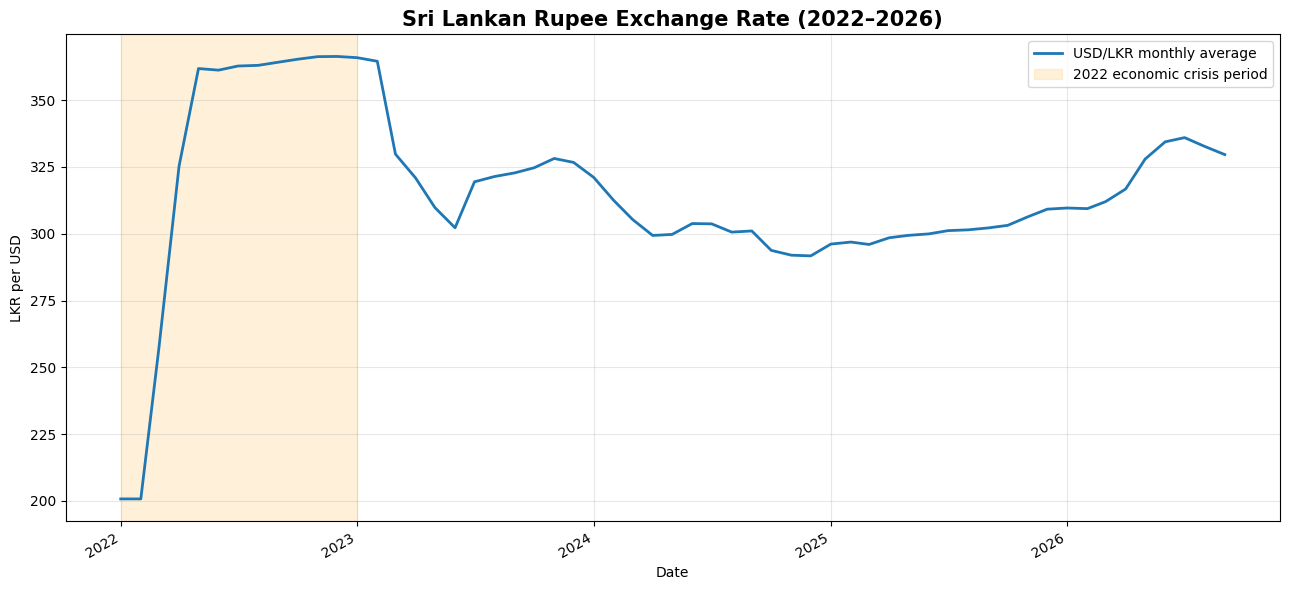

Saved: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/chart_55_usd_lkr_exchange_rate.png


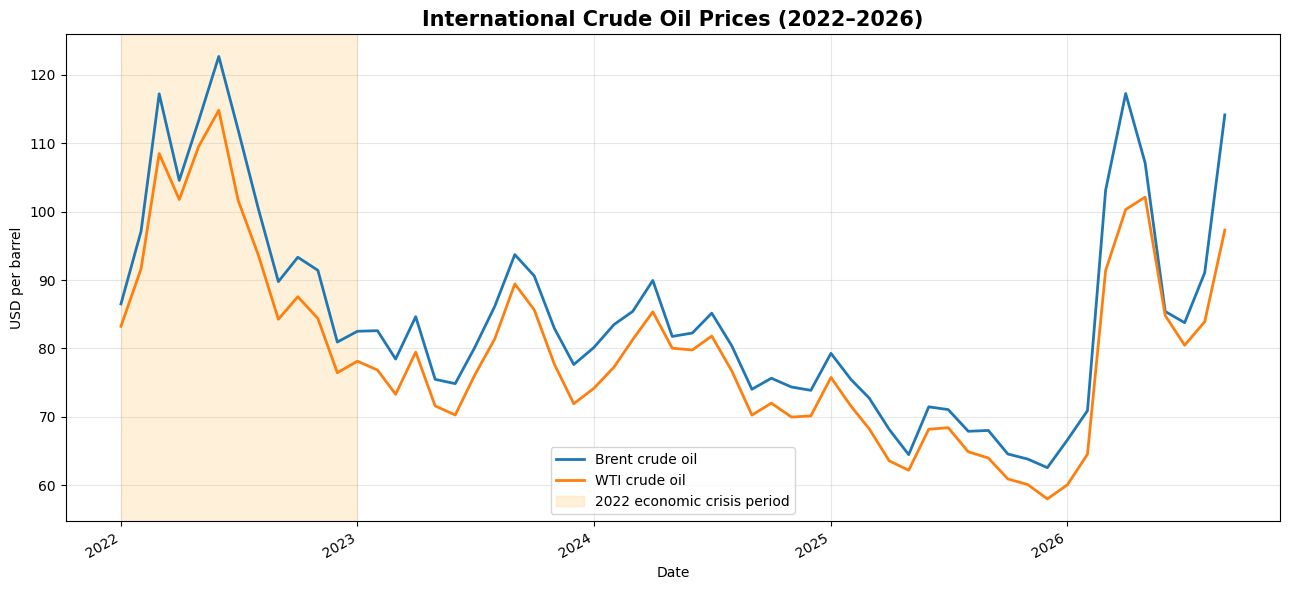

Saved: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/chart_55_brent_wti_prices.png


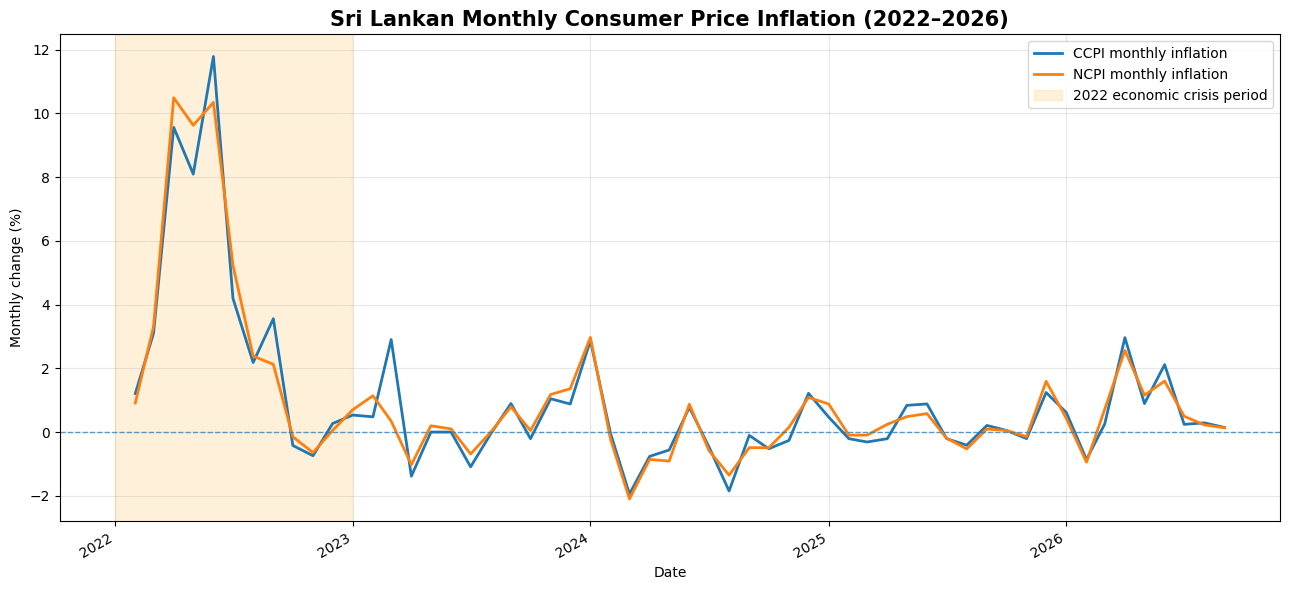

Saved: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/chart_55_ccpi_ncpi_inflation.png


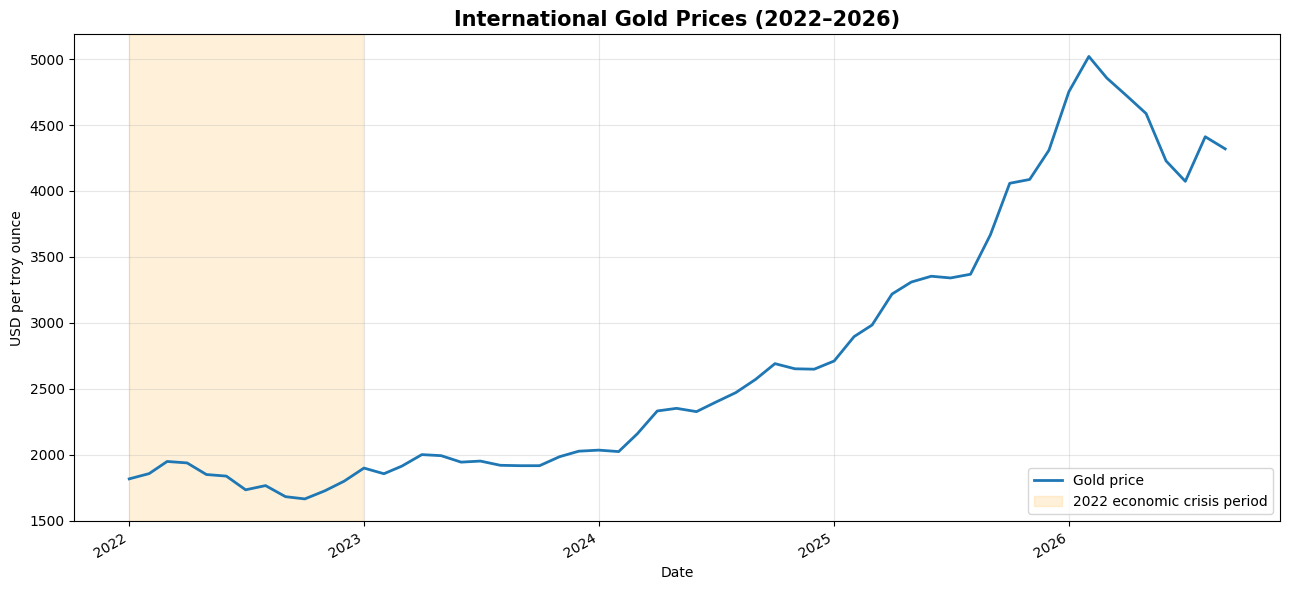

Saved: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/chart_55_gold_prices.png

CELL 55 — VISUALISATION COMPLETED
FOUND: chart_55_usd_lkr_exchange_rate.png
FOUND: chart_55_brent_wti_prices.png
FOUND: chart_55_ccpi_ncpi_inflation.png
FOUND: chart_55_gold_prices.png


In [ ]:

# ============================================================
# CELL 55 — ECONOMIC TREND VISUALISATIONS (2022–2026)
# ============================================================

# Use the existing combined market and inflation dataset.
project_folder = "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"

file_path = os.path.join(
    project_folder,
    "sl_inflation_market_analysis_2022_2026.csv"
)

visual_df = pd.read_csv(file_path)

# ------------------------------------------------------------
# 1. DATA PREPARATION AND VALIDATION
# ------------------------------------------------------------

visual_df["Date"] = pd.to_datetime(visual_df["Date"])

visual_df = (
    visual_df
    .sort_values("Date")
    .reset_index(drop=True)
)

required_columns = [
    "Date",
    "USD_LKR_Mid",
    "Brent_USD_per_Barrel",
    "WTI_USD_per_Barrel",
    "Gold_USD_per_Ounce",
    "CCPI_MoM_Pct",
    "NCPI_MoM_Pct"
]

missing_columns = [
    column for column in required_columns
    if column not in visual_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Restrict the visual analysis to January 2022–September 2026.
visual_df = visual_df[
    (visual_df["Date"] >= "2022-01-01") &
    (visual_df["Date"] <= "2026-09-30")
].copy()

if visual_df.empty:
    raise ValueError("No observations found in the requested period.")

if visual_df["Date"].duplicated().any():
    raise ValueError("Duplicate monthly dates detected.")

print("=" * 80)
print("CELL 55 — VISUALISATION DATA VALIDATION")
print("=" * 80)

print("Observations:", len(visual_df))
print("First month:", visual_df["Date"].min().strftime("%Y-%m"))
print("Last month:", visual_df["Date"].max().strftime("%Y-%m"))
print("Duplicate dates:", visual_df["Date"].duplicated().sum())

print("\nMissing values:")
display(visual_df[required_columns].isna().sum().to_frame("Missing Values"))


# ------------------------------------------------------------
# 2. SHARED CHART FORMATTING
# ------------------------------------------------------------

crisis_start = pd.Timestamp("2022-01-01")
crisis_end = pd.Timestamp("2022-12-31")

def highlight_2022(ax):
    """
    Highlight the exceptional 2022 economic period.
    """
    ax.axvspan(
        crisis_start,
        crisis_end,
        alpha=0.15,
        color="orange",
        label="2022 economic crisis period"
    )

def finish_chart(fig, ax, filename):
    """
    Apply consistent formatting and save the chart.
    """
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")
    fig.autofmt_xdate()
    fig.tight_layout()

    output_path = os.path.join(
        project_folder,
        filename
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_path)


# ------------------------------------------------------------
# 3. USD/LKR EXCHANGE RATE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    visual_df["Date"],
    visual_df["USD_LKR_Mid"],
    linewidth=2,
    label="USD/LKR monthly average"
)

highlight_2022(ax)

ax.set_title(
    "Sri Lankan Rupee Exchange Rate (2022–2026)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("LKR per USD")

finish_chart(
    fig,
    ax,
    "chart_55_usd_lkr_exchange_rate.png"
)


# ------------------------------------------------------------
# 4. BRENT AND WTI CRUDE OIL PRICES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    visual_df["Date"],
    visual_df["Brent_USD_per_Barrel"],
    linewidth=2,
    label="Brent crude oil"
)

ax.plot(
    visual_df["Date"],
    visual_df["WTI_USD_per_Barrel"],
    linewidth=2,
    label="WTI crude oil"
)

highlight_2022(ax)

ax.set_title(
    "International Crude Oil Prices (2022–2026)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("USD per barrel")

finish_chart(
    fig,
    ax,
    "chart_55_brent_wti_prices.png"
)


# ------------------------------------------------------------
# 5. SRI LANKAN MONTHLY INFLATION
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    visual_df["Date"],
    visual_df["CCPI_MoM_Pct"],
    linewidth=2,
    label="CCPI monthly inflation"
)

ax.plot(
    visual_df["Date"],
    visual_df["NCPI_MoM_Pct"],
    linewidth=2,
    label="NCPI monthly inflation"
)

ax.axhline(
    0,
    linewidth=1,
    linestyle="--",
    alpha=0.7
)

highlight_2022(ax)

ax.set_title(
    "Sri Lankan Monthly Consumer Price Inflation (2022–2026)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("Monthly change (%)")

finish_chart(
    fig,
    ax,
    "chart_55_ccpi_ncpi_inflation.png"
)


# ------------------------------------------------------------
# 6. INTERNATIONAL GOLD PRICES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    visual_df["Date"],
    visual_df["Gold_USD_per_Ounce"],
    linewidth=2,
    label="Gold price"
)

highlight_2022(ax)

ax.set_title(
    "International Gold Prices (2022–2026)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("USD per troy ounce")

finish_chart(
    fig,
    ax,
    "chart_55_gold_prices.png"
)


# ------------------------------------------------------------
# 7. FINAL VERIFICATION
# ------------------------------------------------------------

chart_files = [
    "chart_55_usd_lkr_exchange_rate.png",
    "chart_55_brent_wti_prices.png",
    "chart_55_ccpi_ncpi_inflation.png",
    "chart_55_gold_prices.png"
]

print("\n" + "=" * 80)
print("CELL 55 — VISUALISATION COMPLETED")
print("=" * 80)

for filename in chart_files:
    output_path = os.path.join(project_folder, filename)

    status = "FOUND" if os.path.exists(output_path) else "MISSING"

    print(f"{status}: {filename}")


### Cell 56 — Regression Coefficient Visualisation (Post-2022 Models)

This cell creates a coefficient comparison chart using the regression results produced in earlier analysis cells.

**Data sources and model selection**

- `ols_regression_hac_results.csv` contains the original regression results using Brent's one-month lag (Cell 49).
- `ols_regression_brent_lag3_results.csv` contains the alternative regression results using Brent's three-month lag (Cell 52).

These files are combined to compare the exchange-rate and oil-price coefficients across the two Brent specifications.

**Why focus on the post-2022 period?**

Sri Lanka experienced an exceptional economic crisis in 2022. Including this period can disproportionately influence regression estimates. Therefore, this visualisation focuses on January 2023 to September 2026 to examine whether the observed relationships persist outside the crisis period.

**What the chart displays**

- USD/LKR current-month movement.
- USD/LKR previous-month movement.
- Brent current-month movement.
- Brent one-month lag.
- Brent three-month lag.

The chart displays coefficient estimates with 95% confidence intervals calculated using HAC-robust standard errors with three lags.

Coefficients whose confidence intervals do not cross zero indicate statistically significant associations at approximately the 5% level.

**Important methodological note:** The one-month and three-month Brent specifications are alternative regression models. Their coefficients should be compared as alternative estimates, not interpreted as independent effects within the same model. The three-month lag was selected after exploratory lag testing, so its statistical significance should be interpreted cautiously.

The results represent conditional statistical associations and do not establish causation.

CELL 56 — POST-2022 REGRESSION COEFFICIENT VISUALISATION

Regression files loaded successfully.

POST-2022 COEFFICIENT RESULTS


,Outcome,Brent_Specification,Display_Variable,Coefficient,HAC_Std_Error,P_Value,CI_Lower,CI_Upper
1,CCPI_MoM_Pct,Brent Lag 1,USD/LKR Current,-0.1228,0.0885,0.1655,-0.2963,0.0507
2,CCPI_MoM_Pct,Brent Lag 1,USD/LKR Lag 1,0.2277,0.0657,0.0005,0.0989,0.3564
3,CCPI_MoM_Pct,Brent Lag 1,Brent Current,-0.0013,0.0098,0.8939,-0.0204,0.0178
4,CCPI_MoM_Pct,Brent Lag 1,Brent Lag 1,0.0135,0.0254,0.5960,-0.0363,0.0633
6,NCPI_MoM_Pct,Brent Lag 1,USD/LKR Current,0.0285,0.0492,0.5625,-0.0679,0.1249
7,NCPI_MoM_Pct,Brent Lag 1,USD/LKR Lag 1,0.1619,0.0524,0.0020,0.0591,0.2646
8,NCPI_MoM_Pct,Brent Lag 1,Brent Current,0.0043,0.0082,0.6014,-0.0119,0.0205
9,NCPI_MoM_Pct,Brent Lag 1,Brent Lag 1,0.0053,0.0222,0.8111,-0.0381,0.0487
11,CCPI_MoM_Pct,Brent Lag 3,USD/LKR Current,-0.1818,0.0932,0.0511,-0.3644,0.0008
12,CCPI_MoM_Pct,Brent Lag 3,USD/LKR Lag 1,0.2299,0.0603,0.0001,0.1117,0.3482


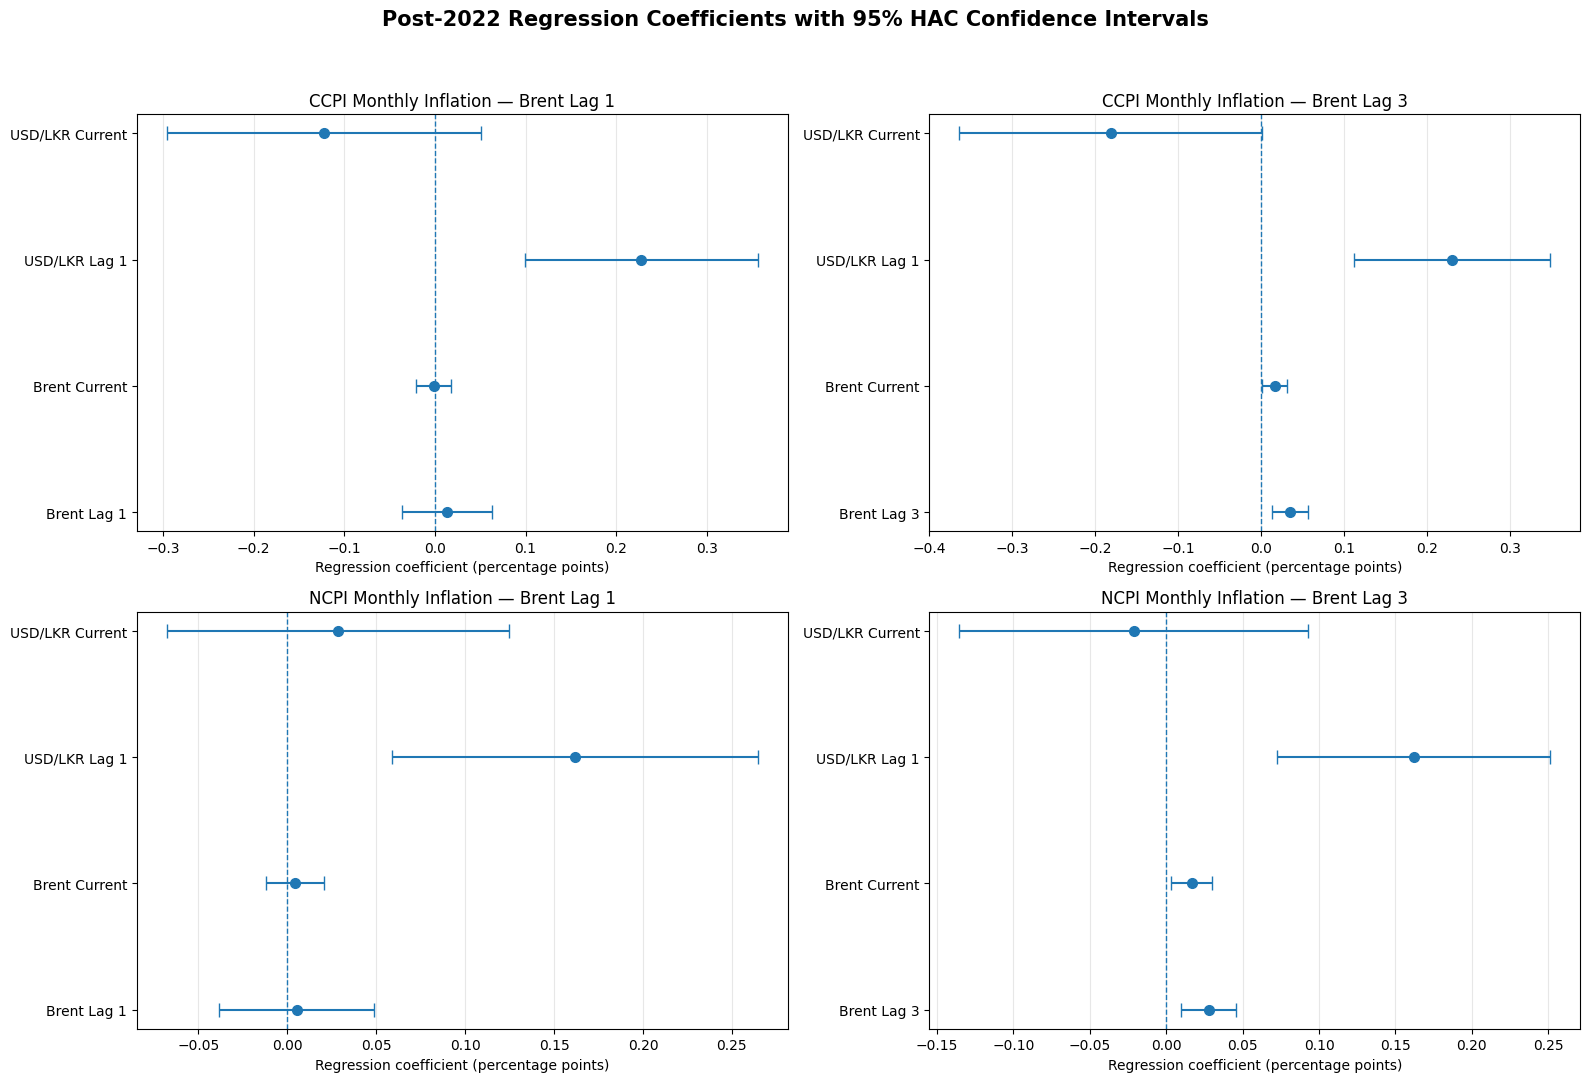


CELL 56 — VISUALISATION COMPLETED
FOUND: chart_56_post_2022_regression_coefficients.png
FOUND: post_2022_regression_coefficients_with_ci.csv

Coefficient records: 16
Confidence interval method: Estimate ± 1.96 × HAC standard error
Regression specifications: Brent Lag 1 and Brent Lag 3
Period: January 2023 – September 2026
Read-back verification: PASSED


In [ ]:

print("=" * 90)
print("CELL 56 — POST-2022 REGRESSION COEFFICIENT VISUALISATION")
print("=" * 90)

# ------------------------------------------------------------
# 1. Load existing regression results
# ------------------------------------------------------------

project_folder = "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"

lag1_path = os.path.join(
    project_folder,
    "ols_regression_hac_results.csv"
)

lag3_path = os.path.join(
    project_folder,
    "ols_regression_brent_lag3_results.csv"
)

if not os.path.exists(lag1_path):
    raise FileNotFoundError(f"Missing regression file: {lag1_path}")

if not os.path.exists(lag3_path):
    raise FileNotFoundError(f"Missing regression file: {lag3_path}")

lag1_results = pd.read_csv(lag1_path)
lag3_results = pd.read_csv(lag3_path)

print("\nRegression files loaded successfully.")

# ------------------------------------------------------------
# 2. Inspect and validate expected columns
# ------------------------------------------------------------

required_columns = {
    "Period",
    "Outcome",
    "Variable",
    "Coefficient",
    "HAC_Std_Error",
    "P_Value"
}

for filename, df in [
    ("Brent Lag 1", lag1_results),
    ("Brent Lag 3", lag3_results)
]:
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"{filename} file is missing columns: {missing_columns}"
        )

# ------------------------------------------------------------
# 3. Filter post-2022 regression results
# ------------------------------------------------------------

post_2022_label = "Excluding 2022"

lag1_post = lag1_results[
    lag1_results["Period"] == post_2022_label
].copy()

lag3_post = lag3_results[
    lag3_results["Period"] == post_2022_label
].copy()

if lag1_post.empty or lag3_post.empty:
    raise ValueError(
        "Post-2022 regression results were not found. "
        "Check the Period column in both CSV files."
    )

lag1_post["Brent_Specification"] = "Brent Lag 1"
lag3_post["Brent_Specification"] = "Brent Lag 3"

coefficient_df = pd.concat(
    [lag1_post, lag3_post],
    ignore_index=True
)

# ------------------------------------------------------------
# 4. Keep the relevant coefficients
# ------------------------------------------------------------

variables_to_plot = [
    "USD_LKR_MoM_Pct",
    "USD_LKR_Lag1",
    "Brent_MoM_Pct",
    "Brent_Lag1",
    "Brent_Lag3"
]

coefficient_df = coefficient_df[
    coefficient_df["Variable"].isin(variables_to_plot)
].copy()

# Keep each Brent lag only in its corresponding specification.
coefficient_df = coefficient_df[
    ~(
        (coefficient_df["Brent_Specification"] == "Brent Lag 1") &
        (coefficient_df["Variable"] == "Brent_Lag3")
    ) &
    ~(
        (coefficient_df["Brent_Specification"] == "Brent Lag 3") &
        (coefficient_df["Variable"] == "Brent_Lag1")
    )
].copy()

# ------------------------------------------------------------
# 5. Validate coefficient records
# ------------------------------------------------------------

expected_records = 2 * 2 * 4

if len(coefficient_df) != expected_records:
    raise ValueError(
        f"Expected {expected_records} coefficient records, "
        f"but found {len(coefficient_df)}. "
        "Check the regression result files."
    )

numeric_columns = [
    "Coefficient",
    "HAC_Std_Error",
    "P_Value"
]

for column in numeric_columns:
    coefficient_df[column] = pd.to_numeric(
        coefficient_df[column],
        errors="coerce"
    )

if coefficient_df[numeric_columns].isna().any().any():
    raise ValueError("Missing or invalid numerical coefficient values.")

if (coefficient_df["HAC_Std_Error"] < 0).any():
    raise ValueError("Standard errors cannot be negative.")

# ------------------------------------------------------------
# 6. Calculate 95% HAC confidence intervals
# ------------------------------------------------------------

coefficient_df["CI_Lower"] = (
    coefficient_df["Coefficient"]
    - 1.96 * coefficient_df["HAC_Std_Error"]
)

coefficient_df["CI_Upper"] = (
    coefficient_df["Coefficient"]
    + 1.96 * coefficient_df["HAC_Std_Error"]
)

# Human-readable variable labels
variable_labels = {
    "USD_LKR_MoM_Pct": "USD/LKR Current",
    "USD_LKR_Lag1": "USD/LKR Lag 1",
    "Brent_MoM_Pct": "Brent Current",
    "Brent_Lag1": "Brent Lag 1",
    "Brent_Lag3": "Brent Lag 3"
}

coefficient_df["Display_Variable"] = (
    coefficient_df["Variable"].map(variable_labels)
)

# ------------------------------------------------------------
# 7. Display coefficient results
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("POST-2022 COEFFICIENT RESULTS")
print("=" * 90)

display(
    coefficient_df[
        [
            "Outcome",
            "Brent_Specification",
            "Display_Variable",
            "Coefficient",
            "HAC_Std_Error",
            "P_Value",
            "CI_Lower",
            "CI_Upper"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 8. Create coefficient comparison visualisation
# ------------------------------------------------------------

outcomes = [
    ("CCPI_MoM_Pct", "CCPI Monthly Inflation"),
    ("NCPI_MoM_Pct", "NCPI Monthly Inflation")
]

specifications = [
    "Brent Lag 1",
    "Brent Lag 3"
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(16, 11),
    sharex=False
)

for row_index, (outcome, outcome_label) in enumerate(outcomes):

    for col_index, specification in enumerate(specifications):

        ax = axes[row_index, col_index]

        plot_df = coefficient_df[
            (coefficient_df["Outcome"] == outcome) &
            (coefficient_df["Brent_Specification"] == specification)
        ].copy()

        plot_df = plot_df.set_index("Variable").reindex(
            [
                "USD_LKR_MoM_Pct",
                "USD_LKR_Lag1",
                "Brent_MoM_Pct",
                "Brent_Lag1" if specification == "Brent Lag 1"
                else "Brent_Lag3"
            ]
        ).reset_index()

        y_positions = np.arange(len(plot_df))

        coefficients = plot_df["Coefficient"].values

        lower_errors = (
            coefficients - plot_df["CI_Lower"].values
        )

        upper_errors = (
            plot_df["CI_Upper"].values - coefficients
        )

        ax.errorbar(
            coefficients,
            y_positions,
            xerr=np.array([lower_errors, upper_errors]),
            fmt="o",
            capsize=5,
            markersize=7
        )

        ax.axvline(
            x=0,
            linestyle="--",
            linewidth=1
        )

        ax.set_yticks(y_positions)

        ax.set_yticklabels(
            plot_df["Display_Variable"].values
        )

        ax.invert_yaxis()

        ax.set_title(
            f"{outcome_label} — {specification}"
        )

        ax.set_xlabel(
            "Regression coefficient (percentage points)"
        )

        ax.grid(
            axis="x",
            alpha=0.3
        )

fig.suptitle(
    "Post-2022 Regression Coefficients with 95% HAC Confidence Intervals",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# ------------------------------------------------------------
# 9. Save visualisation
# ------------------------------------------------------------

chart_path = os.path.join(
    project_folder,
    "chart_56_post_2022_regression_coefficients.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 10. Save coefficient data with confidence intervals
# ------------------------------------------------------------

csv_path = os.path.join(
    project_folder,
    "post_2022_regression_coefficients_with_ci.csv"
)

coefficient_df.to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# 11. Verify saved files
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("CELL 56 — VISUALISATION COMPLETED")
print("=" * 90)

for path in [chart_path, csv_path]:

    if os.path.exists(path):
        print("FOUND:", os.path.basename(path))
    else:
        raise FileNotFoundError(
            f"Output file was not created: {path}"
        )

saved_coefficients = pd.read_csv(csv_path)

if len(saved_coefficients) != expected_records:
    raise ValueError("Coefficient CSV verification failed.")

print("\nCoefficient records:", len(saved_coefficients))
print("Confidence interval method: Estimate ± 1.96 × HAC standard error")
print("Regression specifications: Brent Lag 1 and Brent Lag 3")
print("Period: January 2023 – September 2026")
print("Read-back verification: PASSED")


### Cell 57 — Actual vs Fitted Inflation (Post-2022)

This cell evaluates how closely our regression models track observed Sri Lankan inflation.

**Model specification**

We use the post-2022 Brent Lag 3 regression specification developed in Cell 52:

- Current-month USD/LKR percentage change.
- Previous-month USD/LKR percentage change.
- Current-month Brent crude oil percentage change.
- Three-month-lagged Brent crude oil percentage change.

The analysis covers January 2023 to September 2026, using 45 monthly observations.

Separate models are estimated for CCPI and NCPI monthly inflation. HAC-robust standard errors with three lags are retained for consistency with the earlier regression analysis.

**Visualisation**

The charts compare actual monthly inflation against the values fitted by each regression model.

This helps assess how closely the models track observed inflation movements and identify periods where their estimates differ substantially from actual values.

**Important:** Fitted values measure how well the model explains observations within the estimation sample. They are not out-of-sample forecasts and should not be presented as evidence of future predictive accuracy.

CELL 57 — ACTUAL VS FITTED INFLATION

POST-2022 DATA VALIDATION
------------------------------------------------------------
Observations: 45
First month: 2023-01
Last month: 2026-09

IN-SAMPLE MODEL PERFORMANCE


,Outcome,Observations,R_Squared,Adjusted_R_Squared,RMSE,MAE
0,CCPI,45,0.2608,0.1869,0.9072,0.6677
1,NCPI,45,0.2061,0.1267,0.8458,0.6418


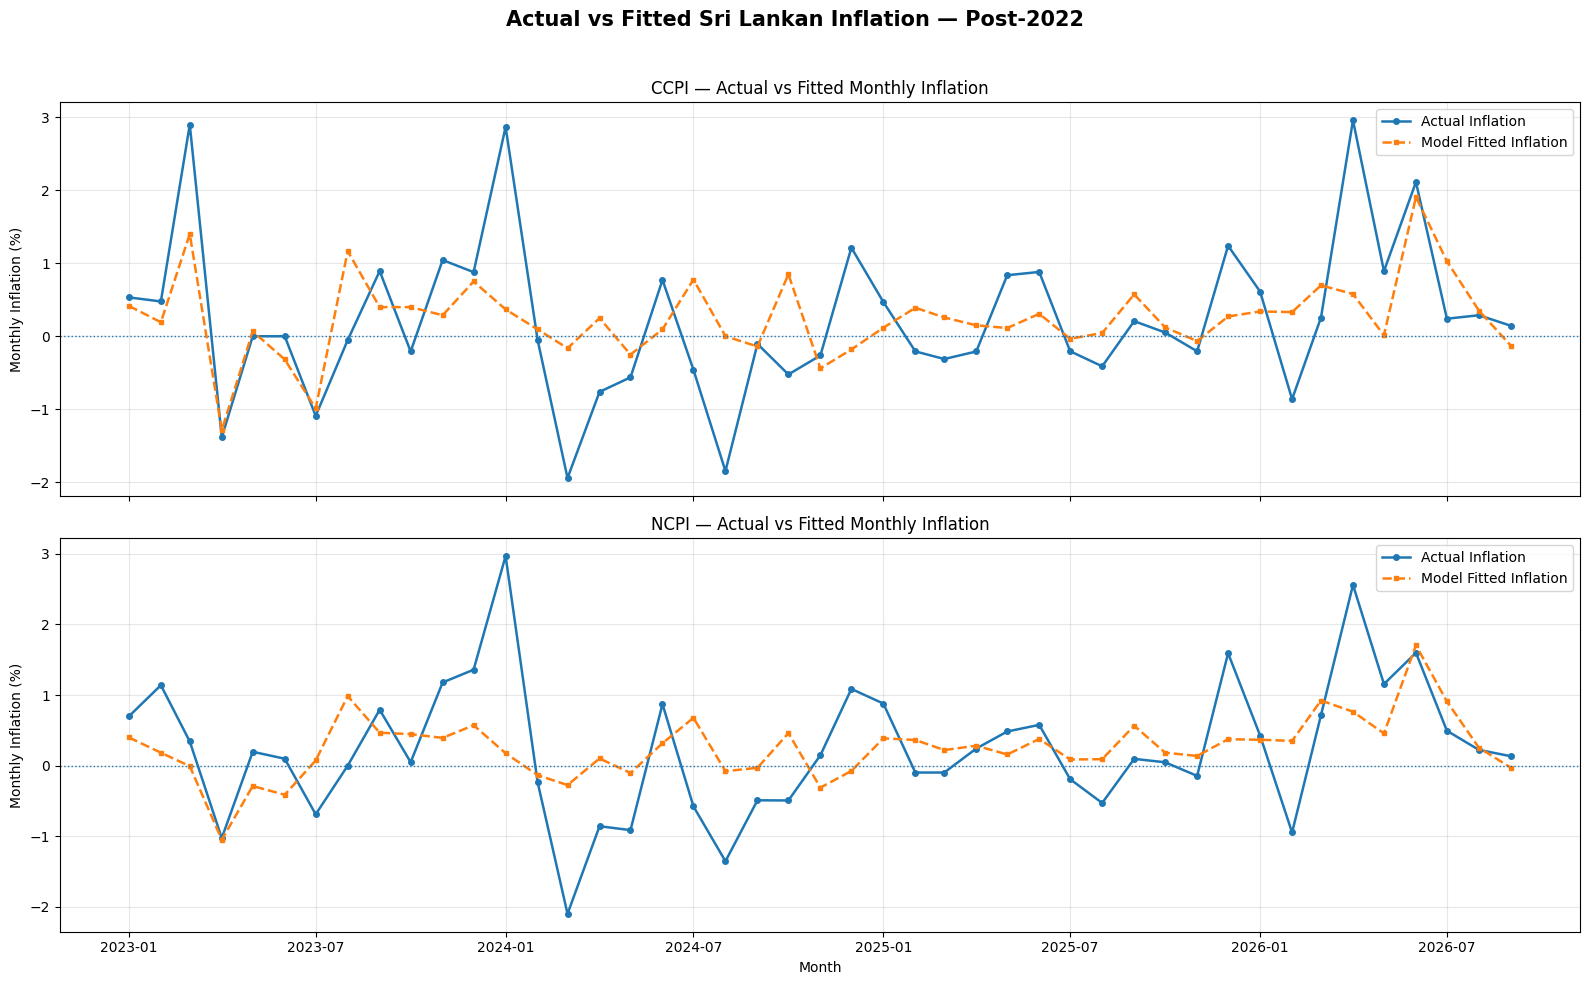


CELL 57 — VISUALISATION COMPLETED
Chart: chart_57_actual_vs_fitted_inflation.png
Fitted values: actual_vs_fitted_inflation_2023_2026.csv
Model performance: actual_vs_fitted_model_performance.csv

Fitted observations: 90
Model summary records: 2
Read-back verification: PASSED


In [ ]:

print("=" * 90)
print("CELL 57 — ACTUAL VS FITTED INFLATION")
print("=" * 90)

# ------------------------------------------------------------
# 1. Prepare the post-2022 dataset
# ------------------------------------------------------------

post_2022_df = comparison_df[
    comparison_df["Date"] >= "2023-01-01"
].copy()

post_2022_df["Date"] = pd.to_datetime(
    post_2022_df["Date"]
)

post_2022_df = (
    post_2022_df
    .sort_values("Date")
    .reset_index(drop=True)
)

predictors = [
    "USD_LKR_MoM_Pct",
    "USD_LKR_Lag1",
    "Brent_MoM_Pct",
    "Brent_Lag3"
]

outcomes = [
    "CCPI_MoM_Pct",
    "NCPI_MoM_Pct"
]

# Validate observations and required data.
if len(post_2022_df) != 45:
    raise ValueError(
        f"Expected 45 post-2022 observations, "
        f"found {len(post_2022_df)}."
    )

required_columns = predictors + outcomes + ["Date"]

if post_2022_df[required_columns].isna().any().any():
    raise ValueError(
        "Missing values detected in the regression dataset."
    )

print("\nPOST-2022 DATA VALIDATION")
print("-" * 60)
print("Observations:", len(post_2022_df))
print("First month:", post_2022_df["Date"].min().strftime("%Y-%m"))
print("Last month:", post_2022_df["Date"].max().strftime("%Y-%m"))

# ------------------------------------------------------------
# 2. Fit the two regression models
# ------------------------------------------------------------

fitted_results = []
model_summary_records = []

for outcome in outcomes:

    X = post_2022_df[predictors].copy()
    X = sm.add_constant(X)

    y = post_2022_df[outcome]

    model = sm.OLS(y, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 3}
    )

    fitted_values = model.fittedvalues
    residuals = model.resid

    outcome_label = (
        "CCPI" if outcome == "CCPI_MoM_Pct"
        else "NCPI"
    )

    # Store actual, fitted and residual values.
    for index in range(len(post_2022_df)):

        fitted_results.append({
            "Date": post_2022_df.loc[index, "Date"],
            "Outcome": outcome_label,
            "Actual_Inflation_Pct": y.iloc[index],
            "Fitted_Inflation_Pct": fitted_values.iloc[index],
            "Residual": residuals.iloc[index]
        })

    # Calculate in-sample fit measurements.
    rmse = np.sqrt(np.mean(residuals ** 2))
    mae = np.mean(np.abs(residuals))

    model_summary_records.append({
        "Outcome": outcome_label,
        "Observations": int(model.nobs),
        "R_Squared": model.rsquared,
        "Adjusted_R_Squared": model.rsquared_adj,
        "RMSE": rmse,
        "MAE": mae
    })

# Convert results to DataFrames.
fitted_df = pd.DataFrame(fitted_results)
model_summary_df = pd.DataFrame(model_summary_records)

# ------------------------------------------------------------
# 3. Display model performance
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("IN-SAMPLE MODEL PERFORMANCE")
print("=" * 90)

display(
    model_summary_df.round(4)
)

# ------------------------------------------------------------
# 4. Create actual vs fitted visualisations
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(16, 10),
    sharex=True
)

outcome_order = ["CCPI", "NCPI"]

for ax, outcome_label in zip(axes, outcome_order):

    plot_df = fitted_df[
        fitted_df["Outcome"] == outcome_label
    ].copy()

    ax.plot(
        plot_df["Date"],
        plot_df["Actual_Inflation_Pct"],
        marker="o",
        markersize=4,
        linewidth=1.8,
        label="Actual Inflation"
    )

    ax.plot(
        plot_df["Date"],
        plot_df["Fitted_Inflation_Pct"],
        marker="s",
        markersize=3,
        linewidth=1.8,
        linestyle="--",
        label="Model Fitted Inflation"
    )

    ax.axhline(
        y=0,
        linestyle=":",
        linewidth=1
    )

    ax.set_title(
        f"{outcome_label} — Actual vs Fitted Monthly Inflation"
    )

    ax.set_ylabel("Monthly Inflation (%)")

    ax.legend()

    ax.grid(
        alpha=0.3
    )

axes[-1].set_xlabel("Month")

fig.suptitle(
    "Actual vs Fitted Sri Lankan Inflation — Post-2022",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# ------------------------------------------------------------
# 5. Save chart
# ------------------------------------------------------------

chart_path = os.path.join(
    project_folder,
    "chart_57_actual_vs_fitted_inflation.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 6. Save fitted values and model performance
# ------------------------------------------------------------

fitted_path = os.path.join(
    project_folder,
    "actual_vs_fitted_inflation_2023_2026.csv"
)

summary_path = os.path.join(
    project_folder,
    "actual_vs_fitted_model_performance.csv"
)

fitted_df.to_csv(
    fitted_path,
    index=False
)

model_summary_df.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# 7. Read-back verification
# ------------------------------------------------------------

fitted_check = pd.read_csv(fitted_path)
summary_check = pd.read_csv(summary_path)

print("\n" + "=" * 90)
print("CELL 57 — VISUALISATION COMPLETED")
print("=" * 90)

print("Chart:", os.path.basename(chart_path))
print("Fitted values:", os.path.basename(fitted_path))
print("Model performance:", os.path.basename(summary_path))

print("\nFitted observations:", len(fitted_check))
print("Model summary records:", len(summary_check))

if (
    len(fitted_check) == 90
    and len(summary_check) == 2
    and os.path.exists(chart_path)
):
    print("Read-back verification: PASSED")
else:
    raise ValueError("Cell 57 output verification failed.")


### Cell 58 — Regression Residual Analysis (Post-2022)

This cell examines the residuals generated by the post-2022 CCPI and NCPI regression models from Cell 57.

A residual represents the difference between the observed inflation rate and the model's fitted inflation rate.

Residual analysis helps evaluate whether the models systematically overestimate or underestimate inflation and whether unexplained errors exhibit patterns over time.

The analysis includes:

- Residual time-series plots.
- Residual distribution histograms.
- Actual versus fitted scatter plots.
- Mean residual and residual standard deviation.

These diagnostics help assess model adequacy. Residuals should not display obvious systematic patterns if the model adequately captures the relationships represented by its specification.

The analysis is conducted using the same 45 in-sample observations from January 2023 to September 2026.

**Important:** Residual diagnostics do not establish causality or out-of-sample forecasting accuracy.

CELL 58 — REGRESSION RESIDUAL ANALYSIS

DATA VALIDATION
------------------------------------------------------------
Total records: 90
CCPI records: 45
NCPI records: 45

RESIDUAL STATISTICS


,Outcome,Observations,Mean_Residual,Residual_Std,Minimum_Residual,Maximum_Residual,Mean_Absolute_Residual
0,CCPI,45,-0.0,0.9174,-1.8495,2.5021,0.6677
1,NCPI,45,0.0,0.8554,-1.8236,2.7929,0.6418


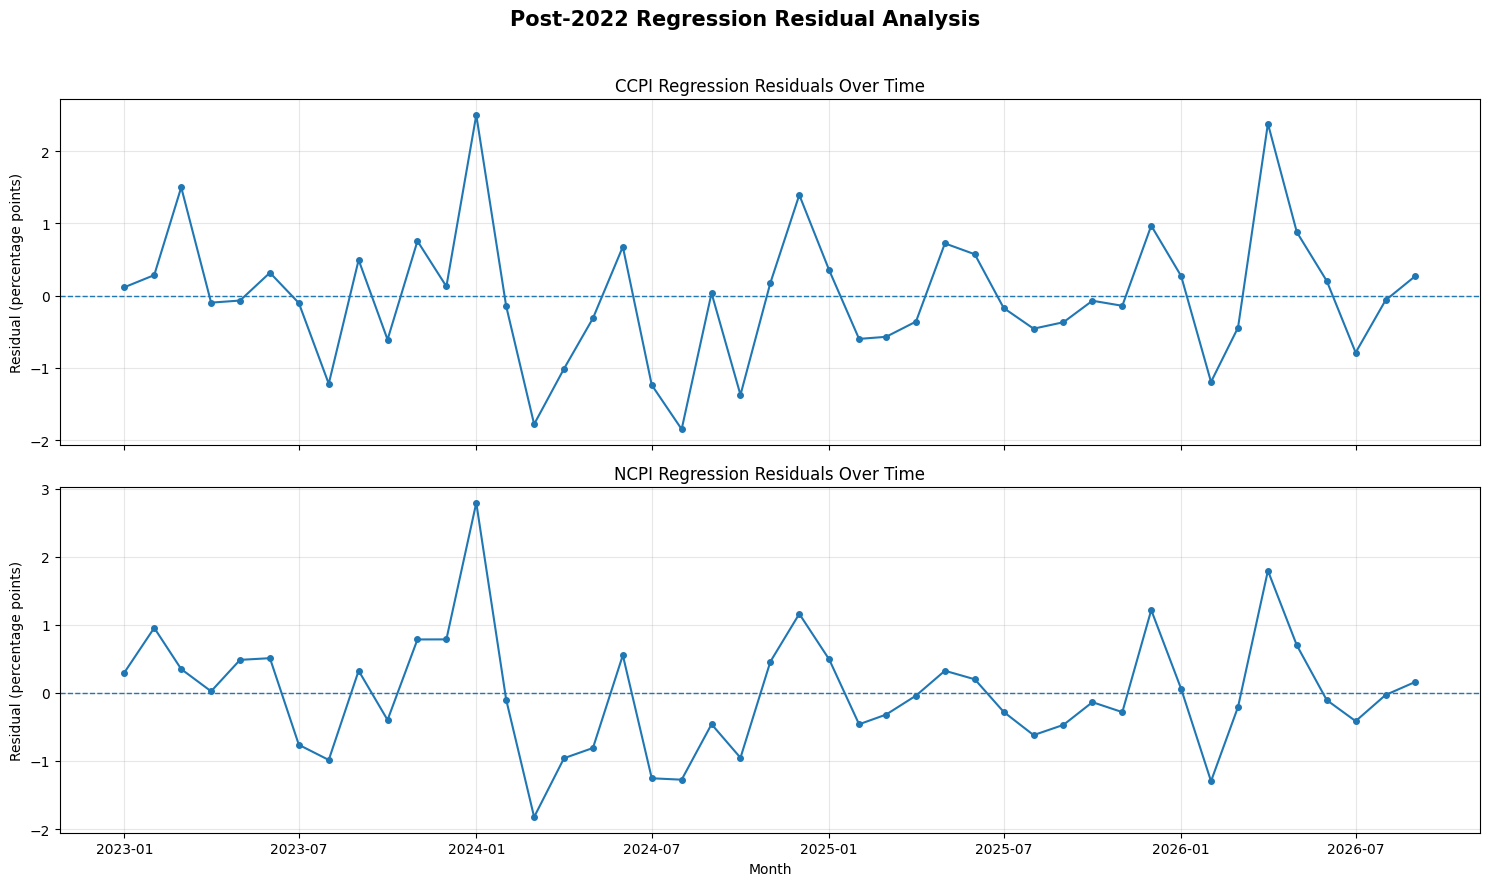

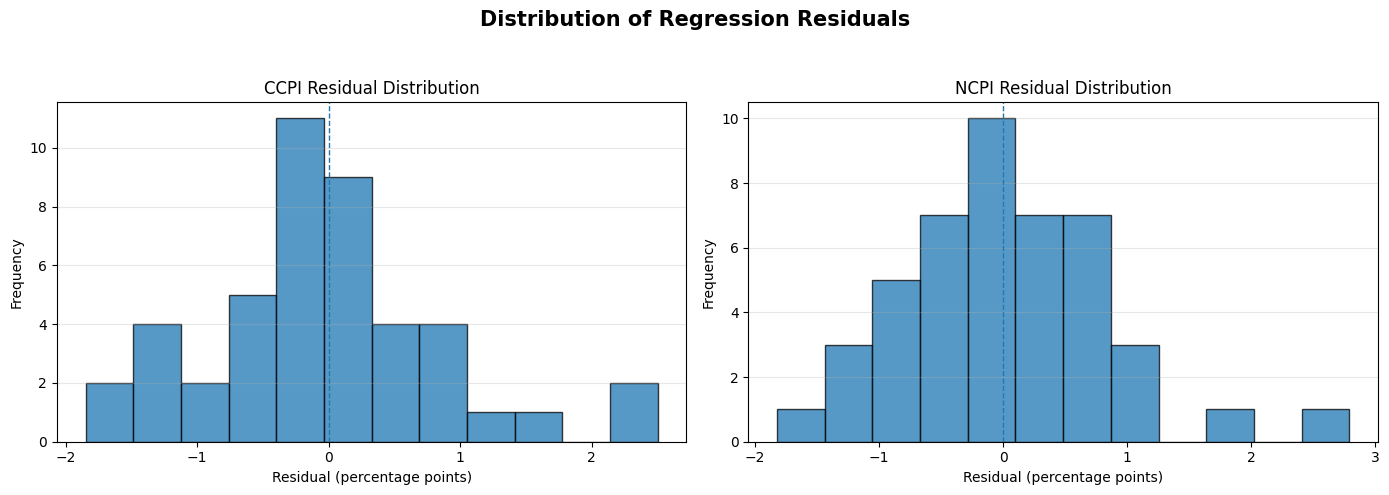

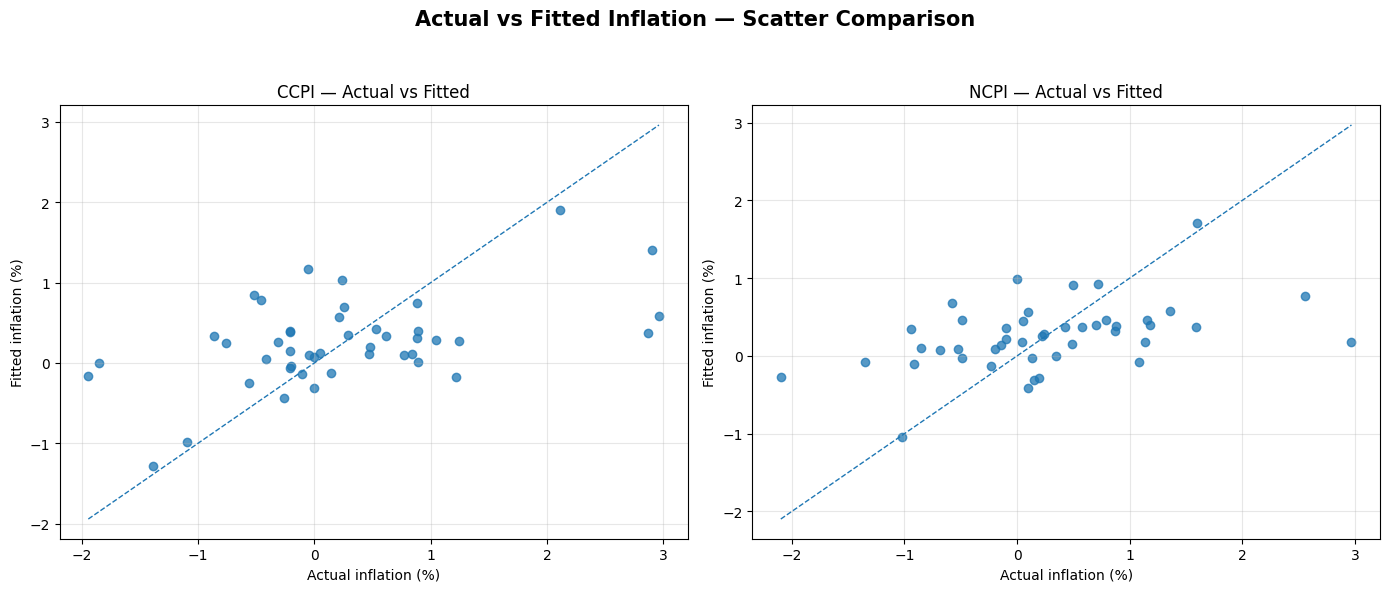


CELL 58 — RESIDUAL ANALYSIS COMPLETED
FOUND: chart_58_residuals_over_time.png
FOUND: chart_58_residual_distribution.png
FOUND: chart_58_actual_vs_fitted_scatter.png
FOUND: regression_residuals_2023_2026.csv
FOUND: regression_residual_summary.csv

Read-back verification: PASSED


In [ ]:

print("=" * 90)
print("CELL 58 — REGRESSION RESIDUAL ANALYSIS")
print("=" * 90)

# ------------------------------------------------------------
# 1. Validate fitted results from Cell 57
# ------------------------------------------------------------

required_columns = [
    "Date",
    "Outcome",
    "Actual_Inflation_Pct",
    "Fitted_Inflation_Pct",
    "Residual"
]

if not all(column in fitted_df.columns for column in required_columns):
    raise ValueError("Required fitted-value columns are missing.")

residual_df = fitted_df.copy()

residual_df["Date"] = pd.to_datetime(
    residual_df["Date"]
)

if residual_df.isna().any().any():
    raise ValueError("Missing values detected in residual dataset.")

print("\nDATA VALIDATION")
print("-" * 60)
print("Total records:", len(residual_df))
print("CCPI records:", len(residual_df[residual_df["Outcome"] == "CCPI"]))
print("NCPI records:", len(residual_df[residual_df["Outcome"] == "NCPI"]))

# ------------------------------------------------------------
# 2. Calculate residual statistics
# ------------------------------------------------------------

residual_summary = []

for outcome in ["CCPI", "NCPI"]:

    subset = residual_df[
        residual_df["Outcome"] == outcome
    ]

    residuals = subset["Residual"]

    residual_summary.append({
        "Outcome": outcome,
        "Observations": len(subset),
        "Mean_Residual": residuals.mean(),
        "Residual_Std": residuals.std(),
        "Minimum_Residual": residuals.min(),
        "Maximum_Residual": residuals.max(),
        "Mean_Absolute_Residual": residuals.abs().mean()
    })

residual_summary_df = pd.DataFrame(
    residual_summary
)

print("\n" + "=" * 90)
print("RESIDUAL STATISTICS")
print("=" * 90)

display(
    residual_summary_df.round(4)
)

# ------------------------------------------------------------
# 3. Residual time-series plots
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 9),
    sharex=True
)

for ax, outcome in zip(axes, ["CCPI", "NCPI"]):

    subset = residual_df[
        residual_df["Outcome"] == outcome
    ].sort_values("Date")

    ax.plot(
        subset["Date"],
        subset["Residual"],
        marker="o",
        markersize=4,
        linewidth=1.5
    )

    ax.axhline(
        y=0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        f"{outcome} Regression Residuals Over Time"
    )

    ax.set_ylabel("Residual (percentage points)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Month")

fig.suptitle(
    "Post-2022 Regression Residual Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

residual_chart_path = os.path.join(
    project_folder,
    "chart_58_residuals_over_time.png"
)

plt.savefig(
    residual_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 4. Residual distribution histograms
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5)
)

for ax, outcome in zip(axes, ["CCPI", "NCPI"]):

    subset = residual_df[
        residual_df["Outcome"] == outcome
    ]

    ax.hist(
        subset["Residual"],
        bins=12,
        edgecolor="black",
        alpha=0.75
    )

    ax.axvline(
        x=0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        f"{outcome} Residual Distribution"
    )

    ax.set_xlabel("Residual (percentage points)")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Distribution of Regression Residuals",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.94])

histogram_path = os.path.join(
    project_folder,
    "chart_58_residual_distribution.png"
)

plt.savefig(
    histogram_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 5. Actual versus fitted scatter plots
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 6)
)

for ax, outcome in zip(axes, ["CCPI", "NCPI"]):

    subset = residual_df[
        residual_df["Outcome"] == outcome
    ]

    actual = subset["Actual_Inflation_Pct"]
    fitted = subset["Fitted_Inflation_Pct"]

    ax.scatter(
        actual,
        fitted,
        alpha=0.75
    )

    # Reference line: perfect fitted values.
    lower = min(actual.min(), fitted.min())
    upper = max(actual.max(), fitted.max())

    ax.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        f"{outcome} — Actual vs Fitted"
    )

    ax.set_xlabel("Actual inflation (%)")
    ax.set_ylabel("Fitted inflation (%)")
    ax.grid(alpha=0.3)

fig.suptitle(
    "Actual vs Fitted Inflation — Scatter Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.94])

scatter_path = os.path.join(
    project_folder,
    "chart_58_actual_vs_fitted_scatter.png"
)

plt.savefig(
    scatter_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 6. Save residual statistics and observations
# ------------------------------------------------------------

residual_data_path = os.path.join(
    project_folder,
    "regression_residuals_2023_2026.csv"
)

residual_summary_path = os.path.join(
    project_folder,
    "regression_residual_summary.csv"
)

residual_df.to_csv(
    residual_data_path,
    index=False
)

residual_summary_df.to_csv(
    residual_summary_path,
    index=False
)

# ------------------------------------------------------------
# 7. Verify saved outputs
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("CELL 58 — RESIDUAL ANALYSIS COMPLETED")
print("=" * 90)

output_paths = [
    residual_chart_path,
    histogram_path,
    scatter_path,
    residual_data_path,
    residual_summary_path
]

for path in output_paths:

    if os.path.exists(path):
        print("FOUND:", os.path.basename(path))
    else:
        raise FileNotFoundError(
            f"Missing output: {path}"
        )

residual_check = pd.read_csv(residual_data_path)
summary_check = pd.read_csv(residual_summary_path)

if len(residual_check) == 90 and len(summary_check) == 2:
    print("\nRead-back verification: PASSED")
else:
    raise ValueError("Residual output verification failed.")


# Cell 59 — Consolidated Research Findings

## Purpose
Consolidate the statistical results from the previous analysis cells into a
single research findings report.

## Data sources
This cell reads the previously generated CSV outputs:

- OLS regression results using Brent lag 1 and lag 3 specifications.
- Regression diagnostic results.
- Regression sensitivity analysis.
- Brent lag model comparison.
- Brent lag coefficient comparison.
- Variance Inflation Factor (VIF) diagnostics.
- Actual versus fitted model performance.
- Regression residual summary.

## Research focus
The report consolidates evidence concerning the relationship between:

1. USD/LKR exchange-rate movements and Sri Lankan inflation.
2. International Brent crude oil price movements and Sri Lankan inflation.
3. Differences between CCPI and NCPI results.
4. Differences between the full comparable period and the post-2022 period.

## Methodological considerations
- Regression coefficients represent statistical associations, not causal effects.
- The post-2022 regression models contain 45 monthly observations.
- HAC standard errors are used to account for potential heteroskedasticity
  and autocorrelation.
- Brent lag 3 was identified through exploratory lag comparisons.
- Model fit and residual diagnostics must be considered alongside
  coefficient significance.
- In-sample fitted values must not be interpreted as out-of-sample forecasts.

## Output
The cell produces a consolidated Markdown report containing the main
research findings and supporting statistical tables.

In [ ]:
# ============================================================
# CELL 59 — CONSOLIDATED RESEARCH FINDINGS
# ============================================================

print("=" * 90)
print("CELL 59 — CONSOLIDATED RESEARCH FINDINGS")
print("=" * 90)

# ------------------------------------------------------------
# 1. PROJECT DIRECTORY
# ------------------------------------------------------------

project_folder = "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"

# ------------------------------------------------------------
# 2. REQUIRED ANALYSIS OUTPUTS
# ------------------------------------------------------------

required_files = {
    "OLS HAC Lag 1": "ols_regression_hac_results.csv",
    "OLS Brent Lag 3": "ols_regression_brent_lag3_results.csv",
    "Regression Diagnostics": "regression_diagnostic_results.csv",
    "Regression Sensitivity": "regression_sensitivity_analysis.csv",
    "Brent Model Fit Comparison": "brent_lag_model_fit_comparison.csv",
    "Brent Coefficient Comparison": "brent_lag_coefficient_comparison.csv",
    "VIF Diagnostics": "regression_vif_diagnostics.csv",
    "Model Performance": "actual_vs_fitted_model_performance.csv",
    "Residual Summary": "regression_residual_summary.csv"
}

print("\nFILE VALIDATION")
print("-" * 60)

loaded_data = {}
missing_files = []

for description, filename in required_files.items():

    file_path = os.path.join(project_folder, filename)

    if os.path.exists(file_path):

        df = pd.read_csv(file_path)

        loaded_data[description] = df

        print(
            f"FOUND: {filename} "
            f"({len(df)} records)"
        )

    else:

        missing_files.append(filename)

        print(f"MISSING: {filename}")


if missing_files:

    raise FileNotFoundError(
        "The following required files are missing:\n"
        + "\n".join(missing_files)
    )


# ------------------------------------------------------------
# 3. HELPER FUNCTION — CONVERT DATAFRAME TO MARKDOWN TABLE
# ------------------------------------------------------------

def dataframe_to_markdown(df):

    if df.empty:
        return "_No records available._"

    display_df = df.copy()

    # Format floating-point values for readability.
    for column in display_df.select_dtypes(
        include=["float"]
    ).columns:

        display_df[column] = display_df[column].map(
            lambda value: (
                f"{value:.4f}"
                if pd.notna(value)
                else ""
            )
        )

    # Convert all values to strings.
    display_df = display_df.fillna("").astype(str)

    headers = list(display_df.columns)

    header_row = "| " + " | ".join(headers) + " |"

    separator_row = (
        "| " +
        " | ".join(["---"] * len(headers)) +
        " |"
    )

    data_rows = []

    for _, row in display_df.iterrows():

        values = [
            value.replace("|", "\\|").replace("\n", " ")
            for value in row.tolist()
        ]

        data_rows.append(
            "| " + " | ".join(values) + " |"
        )

    return "\n".join(
        [header_row, separator_row] + data_rows
    )


# ------------------------------------------------------------
# 4. RESEARCH FINDINGS
# ------------------------------------------------------------

findings = """

# Sri Lanka — Gold, Oil, Exchange Rates and Cost of Living

## Consolidated Research Findings

### 1. Research Overview

This research examines the relationships between international market
movements, exchange-rate movements and Sri Lankan consumer inflation.

The analysis considers:

- International gold prices.
- International Brent and WTI crude oil prices.
- USD/LKR exchange-rate movements.
- Colombo Consumer Price Index (CCPI).
- National Consumer Price Index (NCPI).

The regression analysis focuses on monthly percentage changes rather
than comparing raw price or index levels.

The full comparable inflation analysis covers the period from 2022
onwards. The post-2022 regression sample covers January 2023 to
September 2026.

---

### 2. Exchange Rate and Inflation

The regression results consistently indicate a positive association
between the previous month's USD/LKR movement and current monthly
inflation.

The USD/LKR lag-1 coefficient was positive and statistically significant
in all four principal regression specifications:

- Full-period CCPI.
- Full-period NCPI.
- Post-2022 CCPI.
- Post-2022 NCPI.

The post-2022 models also retained statistical significance when
alternative HAC standard-error settings were applied and influential
observations were excluded.

This suggests that exchange-rate movements contain useful information
about subsequent monthly inflation movements in the analysed sample.

However, the results do not establish causality. They should be
interpreted as statistical associations rather than proof that
exchange-rate depreciation independently caused a specific amount
of inflation.

---

### 3. International Oil Prices and Inflation

The initial Brent lag-1 specifications did not identify a statistically
significant relationship between Brent movements and inflation.

The exploratory lag analysis subsequently identified a stronger
association at a three-month lag.

In the post-2022 Brent lag-3 specification:

- Brent current movement was statistically significant for both CCPI
  and NCPI.
- Brent lag-3 movement was statistically significant for both CCPI
  and NCPI.

The common-sample model comparison also favoured the Brent lag-3
specification over the Brent lag-1 specification based on R-squared,
adjusted R-squared, AIC and BIC.

Nevertheless, the three-month lag was selected after examining
multiple lag specifications. This creates a risk of selection bias
and means the result should be treated as exploratory.

It does not establish a definitive three-month oil-price transmission
period.

---

### 4. CCPI and NCPI Comparison

Both inflation measures show a positive and statistically significant
association with the previous month's USD/LKR movement in the
post-2022 regression models.

The estimated exchange-rate lag-1 coefficients differ between
CCPI and NCPI, reflecting differences in their underlying
geographical coverage and consumption baskets.

The two indices should therefore be interpreted as complementary
measures rather than interchangeable datasets.

---

### 5. Model Explanatory Performance

The post-2022 Brent lag-3 models produced the following results:

| Metric | CCPI | NCPI |
|---|---:|---:|
| Observations | 45 | 45 |
| R-squared | 0.2608 | 0.2061 |
| Adjusted R-squared | 0.1869 | 0.1267 |
| RMSE | 0.9072 | 0.8458 |
| MAE | 0.6677 | 0.6418 |

The models explain approximately 26.1% of CCPI monthly inflation
variation and 20.6% of NCPI monthly inflation variation.

Their explanatory power is therefore modest.

This indicates that exchange-rate and oil-price movements alone
do not capture most of the variation in Sri Lankan monthly inflation.

Other factors, including food prices, domestic supply conditions,
taxation, administered prices, monetary policy and other economic
conditions, may also influence inflation.

The fitted values are in-sample estimates and should not be
interpreted as evidence of future forecasting accuracy.

---

### 6. Regression Diagnostics

The diagnostic analysis identified several considerations:

- Some specifications exhibit residual autocorrelation.
- Full-period residuals show evidence of non-normality.
- Several observations have high influence statistics.
- The VIF results did not indicate concerning multicollinearity.
- Sensitivity analysis showed that the positive USD/LKR lag-1
  relationship remained statistically significant under alternative
  standard-error settings and influential-observation exclusions.

HAC standard errors help address heteroskedasticity and
autocorrelation in coefficient inference, but they do not correct
every possible model specification problem.

The diagnostic results should therefore remain part of the
interpretation of the regression findings.

---

### 7. Residual Analysis

The post-2022 residual analysis contains 45 observations for each
inflation measure.

| Metric | CCPI | NCPI |
|---|---:|---:|
| Mean residual | Approximately 0 | Approximately 0 |
| Residual standard deviation | 0.9174 | 0.8554 |
| Mean absolute residual | 0.6677 | 0.6418 |
| Minimum residual | -1.8495 | -1.8236 |
| Maximum residual | 2.5021 | 2.7929 |

The mean residual is approximately zero, as expected for an
ordinary least squares model with an intercept.

However, the residual ranges demonstrate that individual monthly
inflation movements are not always closely captured by the models.

---

### 8. Overall Research Interpretation

The strongest and most consistent empirical finding is the
positive association between previous-month USD/LKR movements
and current monthly inflation.

The Brent results suggest a possible delayed association with
inflation, particularly under the exploratory three-month lag
specification.

However, the models have modest explanatory power, the sample
is relatively small, and the lag-selection process introduces
additional uncertainty.

The findings should therefore be presented as evidence of
relationships within the observed Sri Lankan data, not as proof
of causal effects or reliable future forecasts.

---

### 9. Research Limitations

The following limitations should be acknowledged:

1. The regression sample is relatively small, particularly after
   restricting the analysis to the post-2022 period.

2. The 2022 economic crisis contains unusually large movements
   that may influence full-period estimates.

3. Brent lag-3 was selected following exploratory comparisons
   across multiple lags.

4. Important domestic economic variables are not included in the
   current regression specifications.

5. CCPI and NCPI have different geographical coverage and
   consumption baskets.

6. The analysis uses observational monthly data and cannot
   independently establish causality.

7. In-sample model performance does not demonstrate
   out-of-sample forecasting ability.

"""

# ------------------------------------------------------------
# 5. APPEND ACTUAL STATISTICAL OUTPUT TABLES
# ------------------------------------------------------------

findings += "\n\n## 10. Supporting Statistical Results\n"

for description, df in loaded_data.items():

    findings += f"\n\n### {description}\n\n"

    findings += dataframe_to_markdown(df)

    findings += "\n"


# ------------------------------------------------------------
# 6. SAVE CONSOLIDATED REPORT
# ------------------------------------------------------------

report_filename = "research_findings_summary_2026.md"

report_path = os.path.join(
    project_folder,
    report_filename
)

with open(report_path, "w", encoding="utf-8") as report_file:

    report_file.write(findings)


# ------------------------------------------------------------
# 7. SAVE SOURCE FILE INVENTORY
# ------------------------------------------------------------

inventory_records = []

for description, filename in required_files.items():

    df = loaded_data[description]

    inventory_records.append({
        "Analysis": description,
        "Source_File": filename,
        "Records": len(df),
        "Columns": len(df.columns),
        "Column_Names": ", ".join(df.columns.astype(str))
    })


inventory_df = pd.DataFrame(inventory_records)

inventory_path = os.path.join(
    project_folder,
    "research_findings_source_inventory.csv"
)

inventory_df.to_csv(
    inventory_path,
    index=False
)


# ------------------------------------------------------------
# 8. OUTPUT VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("CELL 59 — REPORT GENERATION")
print("=" * 90)

print("\nSOURCE FILE INVENTORY")
print("-" * 60)

print(
    inventory_df[
        ["Analysis", "Records", "Columns"]
    ].to_string(index=False)
)

print("\nGENERATED FILES")
print("-" * 60)

for filename in [
    report_filename,
    "research_findings_source_inventory.csv"
]:

    file_path = os.path.join(
        project_folder,
        filename
    )

    if os.path.exists(file_path):

        print(
            f"FOUND: {filename} "
            f"({os.path.getsize(file_path):,} bytes)"
        )

    else:

        raise FileNotFoundError(
            f"Output verification failed: {filename}"
        )


print("\nREPORT PREVIEW")
print("-" * 60)

print(findings[:2500])

print("\n" + "=" * 90)
print("CELL 59 — CONSOLIDATED RESEARCH FINDINGS COMPLETED")
print("=" * 90)

print(f"Report: {report_path}")
print(f"Inventory: {inventory_path}")

CELL 59 — CONSOLIDATED RESEARCH FINDINGS

FILE VALIDATION
------------------------------------------------------------
FOUND: ols_regression_hac_results.csv (20 records)
FOUND: ols_regression_brent_lag3_results.csv (20 records)
FOUND: regression_diagnostic_results.csv (4 records)
FOUND: regression_sensitivity_analysis.csv (60 records)
FOUND: brent_lag_model_fit_comparison.csv (8 records)
FOUND: brent_lag_coefficient_comparison.csv (40 records)
FOUND: regression_vif_diagnostics.csv (16 records)
FOUND: actual_vs_fitted_model_performance.csv (2 records)
FOUND: regression_residual_summary.csv (2 records)

CELL 59 — REPORT GENERATION

SOURCE FILE INVENTORY
------------------------------------------------------------
                    Analysis  Records  Columns
               OLS HAC Lag 1       20       12
             OLS Brent Lag 3       20       12
      Regression Diagnostics        4        9
      Regression Sensitivity       60       10
  Brent Model Fit Comparison        8       

## Task 2 continued — Full-history volume, missingness and analytical suitability

The saved **full-history** join contains **10,661 rows** across **5 columns** (Date plus OVX, GVZ, Brent and WTI), from **1986-01-02 to 2026-11-12**. The saved audit found **0 exact duplicate rows** and **0 duplicate dates**. The market columns have substantial missingness: approximately **72.0% OVX, 56.4% GVZ, 14.4% Brent and 10.5% WTI**. Missingness is expected in part from different source inceptions, public holidays and non-trading observations; it must not be described as wholly random.

When all four market indicators are required together, only **2,925 complete rows** remain (Cell 61). Feature engineering and next-observation target availability yield **2,922 ML rows** (Cell 62), rather than 10,661. The raw table satisfies a **10,000-record count**, but its size does not make it industrial-scale 'big data'. The point of the dataset is credible time-series integration, provenance and analytical work, not merely row count.

The next audit cell regenerates a missingness table and chart directly from the saved CSV. It is additive; it does not edit the source.

# Cell 60 — Big Data Dataset Volume and Suitability Validation

**Purpose:** Independently verify whether `international_market_data_full_history.csv`, preserved in Cell 12, satisfies the coursework's minimum requirement of 10,000 records.

**Important first-run instruction:** Run **this cell only** before running the full notebook. It mounts Google Drive if necessary and reads the saved CSV directly, so it does not depend on variables created by earlier notebook cells.

The cell reports:
- Actual record and column counts.
- Date coverage and duplicate dates.
- Missing-value counts and percentages.
- Data types and whether the dataset contains numerical and non-numerical columns.
- Whether the 10,000-record threshold is met.

This is a validation step, not a data-cleaning step. It does not modify or overwrite the source dataset. Share the complete output with the assistant before deciding whether this dataset is suitable for the coursework.


In [ ]:
# ============================================================
# CELL 60 — BIG DATA DATASET VOLUME AND SUITABILITY VALIDATION
# ============================================================

import os
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# 1. CONNECT TO GOOGLE DRIVE
# ------------------------------------------------------------

PROJECT_FOLDER = "/content/drive/MyDrive/Gold_Oil_Cost_of_Living"
DATASET_FILENAME = "international_market_data_full_history.csv"
DATASET_PATH = os.path.join(PROJECT_FOLDER, DATASET_FILENAME)
MINIMUM_REQUIRED_RECORDS = 10_000

try:
    from google.colab import drive

    if not os.path.isdir("/content/drive/MyDrive"):
        print("Mounting Google Drive...")
        drive.mount("/content/drive")
    else:
        print("Google Drive is already mounted.")

except ImportError:
    print("Google Colab environment not detected.")
    print("This cell expects the project folder to be available at:")
    print(PROJECT_FOLDER)

# ------------------------------------------------------------
# 2. VERIFY THE SOURCE FILE
# ------------------------------------------------------------

print("=" * 90)
print("CELL 60 — DATASET VOLUME AND SUITABILITY VALIDATION")
print("=" * 90)

print("\nFILE VALIDATION")
print("-" * 60)
print("Expected file:", DATASET_PATH)

if not os.path.isfile(DATASET_PATH):
    raise FileNotFoundError(
        "The expected full-history dataset was not found. "
        "Do not run the full notebook yet. Confirm that Cell 12 "
        "previously saved the file to the expected Google Drive folder."
    )

file_size_mb = os.path.getsize(DATASET_PATH) / (1024 * 1024)
print(f"File size: {file_size_mb:.2f} MB")
print("File exists: YES")

# Read the saved file directly. No earlier notebook variables are required.
dataset = pd.read_csv(DATASET_PATH)

# ------------------------------------------------------------
# 3. RECORD AND COLUMN COUNTS
# ------------------------------------------------------------

record_count, column_count = dataset.shape
threshold_met = record_count >= MINIMUM_REQUIRED_RECORDS

print("\nDATASET DIMENSIONS")
print("-" * 60)
print(f"Total records (rows): {record_count:,}")
print(f"Total columns: {column_count:,}")
print(f"Minimum required records: {MINIMUM_REQUIRED_RECORDS:,}")
print("10,000-record requirement:", "PASS" if threshold_met else "NOT MET")

# ------------------------------------------------------------
# 4. DATE COVERAGE AND DUPLICATE CHECK
# ------------------------------------------------------------

print("\nDATE VALIDATION")
print("-" * 60)

date_column = next(
    (column for column in dataset.columns
     if column.strip().lower() in {"date", "datetime", "timestamp"}),
    None
)

if date_column is not None:
    parsed_dates = pd.to_datetime(dataset[date_column], errors="coerce")

    print("Date column:", date_column)
    print("Unparseable dates:", int(parsed_dates.isna().sum()))

    valid_dates = parsed_dates.dropna()

    if not valid_dates.empty:
        print("First date:", valid_dates.min())
        print("Last date:", valid_dates.max())

    duplicate_date_count = int(parsed_dates.duplicated().sum())
    print("Duplicate date values:", duplicate_date_count)
else:
    parsed_dates = None
    duplicate_date_count = None
    print("No recognised date column was found.")

# Exact duplicate rows are reported separately from duplicate dates.
exact_duplicate_rows = int(dataset.duplicated().sum())
print("Exact duplicate rows:", exact_duplicate_rows)

# ------------------------------------------------------------
# 5. MISSING-VALUE PROFILE
# ------------------------------------------------------------

print("\nMISSING-VALUE PROFILE")
print("-" * 60)

missing_profile = pd.DataFrame({
    "Data_Type": dataset.dtypes.astype(str),
    "Missing_Count": dataset.isna().sum(),
    "Missing_Percentage": (dataset.isna().mean() * 100).round(2),
    "Unique_Values": dataset.nunique(dropna=True)
}).sort_values(
    ["Missing_Count", "Missing_Percentage"],
    ascending=False
)

display(missing_profile)

# ------------------------------------------------------------
# 6. FEATURE-TYPE PROFILE
# ------------------------------------------------------------

numeric_columns = dataset.select_dtypes(include="number").columns.tolist()
non_numeric_columns = dataset.select_dtypes(exclude="number").columns.tolist()

print("\nFEATURE-TYPE PROFILE")
print("-" * 60)
print("Numerical columns:", len(numeric_columns))
print("Non-numerical columns:", len(non_numeric_columns))
print("Numerical features:", numeric_columns)
print("Non-numerical features:", non_numeric_columns)

# ------------------------------------------------------------
# 7. SAMPLE RECORDS
# ------------------------------------------------------------

print("\nFIRST FIVE RECORDS")
print("-" * 60)
display(dataset.head())

print("\nLAST FIVE RECORDS")
print("-" * 60)
display(dataset.tail())

# ------------------------------------------------------------
# 8. FINAL VALIDATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL DATASET VALIDATION SUMMARY")
print("=" * 90)

print(f"Dataset: {DATASET_FILENAME}")
print(f"Records: {record_count:,}")
print(f"Columns: {column_count:,}")
print(f"10,000-record threshold: {'PASS' if threshold_met else 'NOT MET'}")
print(f"Exact duplicate rows: {exact_duplicate_rows}")
print(f"Columns with missing values: {int(dataset.isna().any().sum())}")
print(f"Numerical columns: {len(numeric_columns)}")
print(f"Non-numerical columns: {len(non_numeric_columns)}")

if threshold_met:
    print("\nPRELIMINARY RESULT: The dataset meets the minimum record-count requirement.")
    print("This does not, by itself, establish full coursework suitability.")
else:
    print("\nPRELIMINARY RESULT: The dataset does NOT meet the 10,000-record requirement.")
    print("Do not claim that it satisfies the coursework requirement.")

print("\nNo source data was changed or overwritten.")
print("END OF CELL 60")


Google Drive is already mounted.
CELL 60 — DATASET VOLUME AND SUITABILITY VALIDATION

FILE VALIDATION
------------------------------------------------------------
Expected file: /content/drive/MyDrive/Gold_Oil_Cost_of_Living/international_market_data_full_history.csv
File size: 0.28 MB
File exists: YES

DATASET DIMENSIONS
------------------------------------------------------------
Total records (rows): 10,661
Total columns: 5
Minimum required records: 10,000
10,000-record requirement: PASS

DATE VALIDATION
------------------------------------------------------------
Date column: Date
Unparseable dates: 0
First date: 1986-01-02 00:00:00
Last date: 2026-11-12 00:00:00
Duplicate date values: 0
Exact duplicate rows: 0

MISSING-VALUE PROFILE
------------------------------------------------------------


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
OVXCLS,float64,7675,71.99,2035
GVZCLS,float64,6017,56.44,1873
DCOILBRENTEU,float64,1533,14.38,5394
DCOILWTICO,float64,1118,10.49,5504
Date,object,0,0.00,10661



FEATURE-TYPE PROFILE
------------------------------------------------------------
Numerical columns: 4
Non-numerical columns: 1
Numerical features: ['OVXCLS', 'GVZCLS', 'DCOILBRENTEU', 'DCOILWTICO']
Non-numerical features: ['Date']

FIRST FIVE RECORDS
------------------------------------------------------------


,Date,OVXCLS,GVZCLS,DCOILBRENTEU,DCOILWTICO
0,1986-01-02,NaN,NaN,NaN,25.56
1,1986-01-03,NaN,NaN,NaN,26.00
2,1986-01-06,NaN,NaN,NaN,26.53
3,1986-01-07,NaN,NaN,NaN,25.85
4,1986-01-08,NaN,NaN,NaN,25.87



LAST FIVE RECORDS
------------------------------------------------------------


,Date,OVXCLS,GVZCLS,DCOILBRENTEU,DCOILWTICO
10656,2026-11-06,58.29,25.97,97.83,94.37
10657,2026-11-09,57.20,24.93,91.03,90.40
10658,2026-11-10,53.10,24.43,90.16,89.62
10659,2026-11-11,51.26,24.21,92.14,89.62
10660,2026-11-12,51.72,25.91,NaN,NaN



FINAL DATASET VALIDATION SUMMARY
Dataset: international_market_data_full_history.csv
Records: 10,661
Columns: 5
10,000-record threshold: PASS
Exact duplicate rows: 0
Columns with missing values: 4
Numerical columns: 4
Non-numerical columns: 1

PRELIMINARY RESULT: The dataset meets the minimum record-count requirement.
This does not, by itself, establish full coursework suitability.

No source data was changed or overwritten.
END OF CELL 60


## Cell 61 — Usable Observations and Feature Availability Analysis

This section evaluates how many observations are available for individual
financial indicators and combinations of indicators. It identifies the
common observation period and determines whether the dataset provides
sufficient records for machine-learning preparation.

In [ ]:

# =============================================================================
# CELL 61 — USABLE OBSERVATIONS AND FEATURE AVAILABILITY ANALYSIS
# =============================================================================

import pandas as pd
import os
from itertools import combinations

print("=" * 90)
print("CELL 61 — USABLE OBSERVATIONS AND FEATURE AVAILABILITY ANALYSIS")
print("=" * 90)

# ---------------------------------------------------------------------------
# 1. LOAD THE EXISTING FULL-HISTORY DATASET
# ---------------------------------------------------------------------------

file_path = (
    "/content/drive/MyDrive/Gold_Oil_Cost_of_Living/"
    "international_market_data_full_history.csv"
)

if not os.path.exists(file_path):
    raise FileNotFoundError(f"Dataset not found: {file_path}")

df = pd.read_csv(file_path)

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

feature_columns = [
    "OVXCLS",
    "GVZCLS",
    "DCOILBRENTEU",
    "DCOILWTICO"
]

missing_columns = [
    col for col in feature_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

df = df.sort_values("Date").reset_index(drop=True)

print("\nDATASET OVERVIEW")
print("-" * 60)
print(f"Total records: {len(df):,}")
print(f"First date: {df['Date'].min()}")
print(f"Last date: {df['Date'].max()}")

# ---------------------------------------------------------------------------
# 2. INDIVIDUAL FEATURE AVAILABILITY
# ---------------------------------------------------------------------------

print("\nINDIVIDUAL FEATURE AVAILABILITY")
print("-" * 60)

availability_results = []

for col in feature_columns:

    valid_data = df.loc[df[col].notna(), ["Date", col]]

    availability_results.append({
        "Feature": col,
        "Available_Records": len(valid_data),
        "Missing_Records": df[col].isna().sum(),
        "Availability_Percentage": round(
            df[col].notna().mean() * 100, 2
        ),
        "First_Available_Date": (
            valid_data["Date"].min()
            if not valid_data.empty else None
        ),
        "Last_Available_Date": (
            valid_data["Date"].max()
            if not valid_data.empty else None
        )
    })

availability_df = pd.DataFrame(availability_results)

display(availability_df)

# ---------------------------------------------------------------------------
# 3. COMBINED FEATURE AVAILABILITY
# ---------------------------------------------------------------------------

print("\nCOMBINED FEATURE AVAILABILITY")
print("-" * 60)

combination_results = []

for number_of_features in range(2, len(feature_columns) + 1):

    for selected_features in combinations(
        feature_columns, number_of_features
    ):

        valid_mask = df[list(selected_features)].notna().all(axis=1)
        valid_data = df.loc[valid_mask, ["Date"]]

        combination_results.append({
            "Features": " + ".join(selected_features),
            "Number_of_Features": number_of_features,
            "Usable_Records": len(valid_data),
            "Percentage_of_Total": round(
                len(valid_data) / len(df) * 100, 2
            ),
            "First_Available_Date": (
                valid_data["Date"].min()
                if not valid_data.empty else None
            ),
            "Last_Available_Date": (
                valid_data["Date"].max()
                if not valid_data.empty else None
            )
        })

combination_df = pd.DataFrame(combination_results)

display(
    combination_df.sort_values(
        by="Usable_Records",
        ascending=False
    ).reset_index(drop=True)
)

# ---------------------------------------------------------------------------
# 4. COMPLETE RECORDS — ALL FOUR FEATURES
# ---------------------------------------------------------------------------

print("\nCOMPLETE RECORD VALIDATION")
print("-" * 60)

complete_mask = df[feature_columns].notna().all(axis=1)
complete_df = df.loc[complete_mask].copy()

print(f"Records with all four features: {len(complete_df):,}")

if not complete_df.empty:
    print(f"First complete observation: {complete_df['Date'].min()}")
    print(f"Last complete observation: {complete_df['Date'].max()}")
else:
    print("No records contain all four features simultaneously.")

# ---------------------------------------------------------------------------
# 5. BRENT AND WTI AVAILABILITY
# ---------------------------------------------------------------------------

print("\nBRENT AND WTI CORE DATA AVAILABILITY")
print("-" * 60)

oil_features = ["DCOILBRENTEU", "DCOILWTICO"]

oil_mask = df[oil_features].notna().all(axis=1)
oil_df = df.loc[oil_mask].copy()

print(f"Records with both Brent and WTI: {len(oil_df):,}")

if not oil_df.empty:
    print(f"First common observation: {oil_df['Date'].min()}")
    print(f"Last common observation: {oil_df['Date'].max()}")

# ---------------------------------------------------------------------------
# 6. YEARLY FEATURE AVAILABILITY
# ---------------------------------------------------------------------------

print("\nYEARLY FEATURE AVAILABILITY")
print("-" * 60)

yearly_df = df.copy()
yearly_df["Year"] = yearly_df["Date"].dt.year

yearly_results = []

for year, group in yearly_df.groupby("Year"):

    result = {
        "Year": year,
        "Total_Records": len(group)
    }

    for col in feature_columns:
        result[col + "_Available"] = group[col].notna().sum()

    result["All_Four_Available"] = (
        group[feature_columns].notna().all(axis=1).sum()
    )

    yearly_results.append(result)

yearly_availability_df = pd.DataFrame(yearly_results)

display(yearly_availability_df.tail(20))

# ---------------------------------------------------------------------------
# 7. FINAL SUMMARY
# ---------------------------------------------------------------------------

print("\n" + "=" * 90)
print("CELL 61 — FINAL SUMMARY")
print("=" * 90)

print(f"Original dataset records: {len(df):,}")
print(f"All four features available: {len(complete_df):,}")
print(f"Brent and WTI both available: {len(oil_df):,}")

print("\nIMPORTANT:")
print("No rows have been deleted.")
print("No missing values have been filled.")
print("The original dataset has not been modified.")
print("This cell only evaluates feature availability.")

print("\nEND OF CELL 61")
print("=" * 90)


CELL 61 — USABLE OBSERVATIONS AND FEATURE AVAILABILITY ANALYSIS

DATASET OVERVIEW
------------------------------------------------------------
Total records: 10,661
First date: 1986-01-02 00:00:00
Last date: 2026-11-12 00:00:00

INDIVIDUAL FEATURE AVAILABILITY
------------------------------------------------------------


,Feature,Available_Records,Missing_Records,Availability_Percentage,First_Available_Date,Last_Available_Date
0,OVXCLS,2986,7675,28.01,2015-01-02,2026-11-12
1,GVZCLS,4644,6017,43.56,2008-06-03,2026-11-12
2,DCOILBRENTEU,9128,1533,85.62,1987-05-20,2026-11-11
3,DCOILWTICO,9543,1118,89.51,1986-01-02,2026-11-11



COMBINED FEATURE AVAILABILITY
------------------------------------------------------------


,Features,Number_of_Features,Usable_Records,Percentage_of_Total,First_Available_Date,Last_Available_Date
0,DCOILBRENTEU + DCOILWTICO,2,8436,79.13,1987-05-20,2026-11-11
1,GVZCLS + DCOILBRENTEU,2,4596,43.11,2008-06-03,2026-11-11
2,GVZCLS + DCOILWTICO,2,4571,42.88,2008-06-03,2026-11-11
3,GVZCLS + DCOILBRENTEU + DCOILWTICO,3,4529,42.48,2008-06-03,2026-11-11
4,OVXCLS + GVZCLS,2,2986,28.01,2015-01-02,2026-11-12
5,OVXCLS + GVZCLS + DCOILWTICO,3,2961,27.77,2015-01-02,2026-11-11
6,OVXCLS + DCOILWTICO,2,2961,27.77,2015-01-02,2026-11-11
7,OVXCLS + DCOILBRENTEU,2,2946,27.63,2015-01-02,2026-11-11
8,OVXCLS + GVZCLS + DCOILBRENTEU,3,2946,27.63,2015-01-02,2026-11-11
9,OVXCLS + DCOILBRENTEU + DCOILWTICO,3,2925,27.44,2015-01-02,2026-11-11



COMPLETE RECORD VALIDATION
------------------------------------------------------------
Records with all four features: 2,925
First complete observation: 2015-01-02 00:00:00
Last complete observation: 2026-11-11 00:00:00

BRENT AND WTI CORE DATA AVAILABILITY
------------------------------------------------------------
Records with both Brent and WTI: 8,436
First common observation: 1987-05-20 00:00:00
Last common observation: 2026-11-11 00:00:00

YEARLY FEATURE AVAILABILITY
------------------------------------------------------------


,Year,Total_Records,OVXCLS_Available,GVZCLS_Available,DCOILBRENTEU_Available,DCOILWTICO_Available,All_Four_Available
21,2007,261,0,0,247,248,0
22,2008,262,0,148,253,253,0
23,2009,261,0,252,252,250,0
24,2010,261,0,252,252,252,0
25,2011,260,0,252,248,212,0
26,2012,261,0,250,249,252,0
27,2013,261,0,252,252,250,0
28,2014,261,0,252,253,248,0
29,2015,261,252,252,255,244,243
30,2016,261,252,252,255,252,251



CELL 61 — FINAL SUMMARY
Original dataset records: 10,661
All four features available: 2,925
Brent and WTI both available: 8,436

IMPORTANT:
No rows have been deleted.
No missing values have been filled.
The original dataset has not been modified.
This cell only evaluates feature availability.

END OF CELL 61


Raw records: 10661
Complete rows (four market features): 2925
Duplicate dates: 0
Exact duplicate rows: 0


,Feature,Nonmissing_Count,Missing_Count,Missing_Pct
0,OVXCLS,2986,7675,71.99
1,GVZCLS,4644,6017,56.44
2,DCOILBRENTEU,9128,1533,14.38
3,DCOILWTICO,9543,1118,10.49


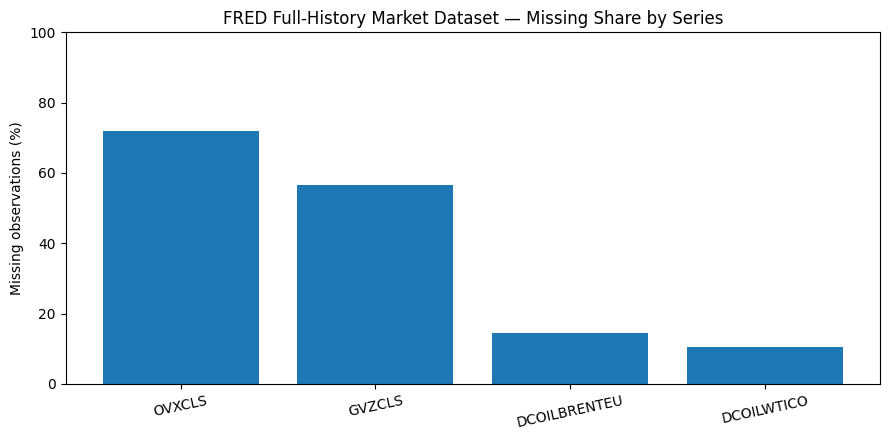

Saved supplement_market_missingness_audit.csv


In [ ]:
# SUPPLEMENTARY AUDIT A — raw market missingness and coverage
# Run after the original Cell 60; does not alter the original data.
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

source_path = os.path.join(PROJECT_FOLDER, "international_market_data_full_history.csv")
raw_audit = pd.read_csv(source_path, parse_dates=["Date"])
market_cols_audit = ["OVXCLS", "GVZCLS", "DCOILBRENTEU", "DCOILWTICO"]
raw_audit_missing = pd.DataFrame({
    "Feature": market_cols_audit,
    "Nonmissing_Count": [int(raw_audit[c].notna().sum()) for c in market_cols_audit],
    "Missing_Count": [int(raw_audit[c].isna().sum()) for c in market_cols_audit],
    "Missing_Pct": [round(100*raw_audit[c].isna().mean(),2) for c in market_cols_audit],
})
print("Raw records:", len(raw_audit))
print("Complete rows (four market features):", int(raw_audit[market_cols_audit].notna().all(axis=1).sum()))
print("Duplicate dates:", int(raw_audit["Date"].duplicated().sum()))
print("Exact duplicate rows:", int(raw_audit.duplicated().sum()))
display(raw_audit_missing)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(raw_audit_missing["Feature"], raw_audit_missing["Missing_Pct"])
ax.set(title="FRED Full-History Market Dataset — Missing Share by Series",
       ylabel="Missing observations (%)", ylim=(0, 100))
plt.xticks(rotation=12)
plt.tight_layout()
plt.show()

raw_audit_missing.to_csv(os.path.join(PROJECT_FOLDER, "supplement_market_missingness_audit.csv"), index=False)
print("Saved supplement_market_missingness_audit.csv")

# Task 4B — Daily Brent return prediction and validation

**Forecast objective:** percentage return in Brent at the **next observed Brent date**, which may be more than one calendar day ahead due to weekends/holidays/series gaps. It is **not** a guaranteed 'tomorrow' forecast. The model uses 11 engineered numeric features from current and lagged Brent, WTI, OVX and GVZ information. The target is constructed by shifting the available Brent return series **forward by one observed Brent row**.

**Selection and preparation:** The feature intersection begins in 2015, after OVX/GVZ both have coverage. The model table has 2,922 fully numeric, finite rows. NaNs/undefined percentage changes are removed only for the derived ML table; original data remains unmodified.

**Train / selection / test:** Original Cell 64 splits chronologically, approximately **70%/15%/15%** (saved results: **2,045 / 438 / 439** observations). Candidate Ridge alphas and Random Forest configurations are chosen on **validation RMSE**; the untouched test set is used to report out-of-sample performance. Ridge scaling is learned from the training data, not the entire dataset.

**What does success mean?** Better performance than a persistence forecast is helpful but **insufficient**. The zero-return forecast is often a serious benchmark for noisy daily returns; a training-mean forecast is another non-leaking comparator. Both are added below as a supplemental test audit. The primary operational decision should also consider stability over years, drift, transaction costs, extreme-event errors and monitoring requirements.

**Boundary limitation:** Strict walk-forward estimation should only train on observations whose **target date** precedes the next split's feature date. The original row-based split checks feature dates but does not explicitly purge target labels overlapping the next interval. A supplementary diagnostic checks this, and a fully operational backtest would use purging/rolling-origin evaluation. Do not call the original split perfectly leakage-proof without that additional validation.


## Cell 62 — Machine Learning Problem Definition and Dataset Preparation

This section establishes the machine learning problem and prepares a separate modelling dataset using the validated international market data.

The objective is to predict the next trading observation's Brent crude oil percentage return using current and lagged market indicators.

The modelling dataset is constructed separately from the original dataset. The original historical data is preserved.


In [ ]:

import os
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. LOAD ORIGINAL HISTORICAL DATA
# ------------------------------------------------------------

DATASET_FILE = os.path.join(
    PROJECT_FOLDER,
    "international_market_data_full_history.csv"
)

market_ml_source = pd.read_csv(DATASET_FILE)

market_ml_source["Date"] = pd.to_datetime(
    market_ml_source["Date"],
    errors="coerce"
)

market_ml_source = (
    market_ml_source
    .dropna(subset=["Date"])
    .sort_values("Date")
    .reset_index(drop=True)
)

feature_columns = [
    "OVXCLS",
    "GVZCLS",
    "DCOILBRENTEU",
    "DCOILWTICO"
]

missing_columns = [
    col for col in feature_columns
    if col not in market_ml_source.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# ------------------------------------------------------------
# 2. CALCULATE RETURNS BEFORE ALIGNING THE DATASETS
# ------------------------------------------------------------

# Each indicator uses its own available observations.
# This prevents missing dates in another indicator from
# distorting its percentage-change calculation.

market_features = None

for column in feature_columns:

    series = (
        market_ml_source[["Date", column]]
        .dropna(subset=[column])
        .sort_values("Date")
        .copy()
    )

    series[f"{column}_Change_Pct"] = (
        series[column].pct_change(fill_method=None) * 100
    )

    if market_features is None:
        market_features = series
    else:
        market_features = market_features.merge(
            series,
            on="Date",
            how="inner"
        )

# ------------------------------------------------------------
# 3. CREATE BRENT NEXT-OBSERVATION TARGET
# ------------------------------------------------------------

brent_data = (
    market_ml_source[["Date", "DCOILBRENTEU"]]
    .dropna(subset=["DCOILBRENTEU"])
    .sort_values("Date")
    .copy()
)

brent_data["Brent_Return_Pct"] = (
    brent_data["DCOILBRENTEU"]
    .pct_change(fill_method=None) * 100
)

brent_data["Target_Next_Brent_Return_Pct"] = (
    brent_data["Brent_Return_Pct"].shift(-1)
)

brent_data["Target_Date"] = (
    brent_data["Date"].shift(-1)
)

# ------------------------------------------------------------
# 4. ALIGN ALL FOUR INDICATORS AND THE TARGET
# ------------------------------------------------------------

market_ml = market_features.merge(
    brent_data[
        [
            "Date",
            "Brent_Return_Pct",
            "Target_Next_Brent_Return_Pct",
            "Target_Date"
        ]
    ],
    on="Date",
    how="inner"
)

market_ml = (
    market_ml
    .sort_values("Date")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. CREATE LAGGED FEATURES
# ------------------------------------------------------------

base_features = [
    "Brent_Return_Pct",
    "DCOILWTICO_Change_Pct",
    "OVXCLS_Change_Pct",
    "GVZCLS_Change_Pct"
]

for column in base_features:
    market_ml[f"{column}_Lag1"] = (
        market_ml[column].shift(1)
    )

# ------------------------------------------------------------
# 6. DEFINE MODEL INPUTS AND TARGET
# ------------------------------------------------------------

ml_feature_columns = [
    "Brent_Return_Pct",
    "DCOILWTICO",
    "OVXCLS",
    "GVZCLS",
    "DCOILWTICO_Change_Pct",
    "OVXCLS_Change_Pct",
    "GVZCLS_Change_Pct",
    "Brent_Return_Pct_Lag1",
    "DCOILWTICO_Change_Pct_Lag1",
    "OVXCLS_Change_Pct_Lag1",
    "GVZCLS_Change_Pct_Lag1"
]

target_column = "Target_Next_Brent_Return_Pct"

ml_dataset = market_ml[
    ["Date", "Target_Date"] +
    ml_feature_columns +
    [target_column]
].replace(
    [np.inf, -np.inf],
    np.nan
).dropna().reset_index(drop=True)

# ------------------------------------------------------------
# 7. VALIDATE MODELLING DATASET
# ------------------------------------------------------------

if ml_dataset.empty:
    raise ValueError("The modelling dataset is empty.")

if ml_dataset[ml_feature_columns].isna().any().any():
    raise ValueError("Missing values remain in model features.")

if ml_dataset[target_column].isna().any():
    raise ValueError("Missing target values remain.")

if not np.isfinite(
    ml_dataset[ml_feature_columns + [target_column]].to_numpy()
).all():
    raise ValueError("Non-finite values remain.")

if not (
    ml_dataset["Target_Date"] > ml_dataset["Date"]
).all():
    raise ValueError("Target dates must be after feature dates.")

# ------------------------------------------------------------
# 8. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 90)
print("CELL 62 — CORRECTED MACHINE LEARNING DATASET PREPARATION")
print("=" * 90)

print("\nSOURCE DATA")
print("-" * 60)
print("Original records:", len(market_ml_source))

print("\nMODELLING DATASET")
print("-" * 60)
print("Final ML records:", len(ml_dataset))
print("Input features:", len(ml_feature_columns))
print("Target:", target_column)

print("\nDATE RANGE")
print("-" * 60)
print("First feature date:", ml_dataset["Date"].min())
print("Last feature date:", ml_dataset["Date"].max())
print("First target date:", ml_dataset["Target_Date"].min())
print("Last target date:", ml_dataset["Target_Date"].max())

print("\nTARGET DISTRIBUTION")
print("-" * 60)
print(ml_dataset[target_column].describe())

print("\nFEATURE LIST")
print("-" * 60)

for column in ml_feature_columns:
    print("-", column)

print("\nDATASET PREVIEW")
print("-" * 60)
display(ml_dataset.head())

print("\nDATA VALIDATION")
print("-" * 60)
print("Missing values:", ml_dataset.isna().sum().sum())
print("Duplicate feature dates:",
      ml_dataset["Date"].duplicated().sum())
print("Invalid target dates:",
      int((ml_dataset["Target_Date"] <= ml_dataset["Date"]).sum()))
print("All numerical values finite:",
      np.isfinite(
          ml_dataset[ml_feature_columns + [target_column]].to_numpy()
      ).all())

print("\nOriginal source dataset was not modified.")
print("=" * 90)


CELL 62 — CORRECTED MACHINE LEARNING DATASET PREPARATION

SOURCE DATA
------------------------------------------------------------
Original records: 10661

MODELLING DATASET
------------------------------------------------------------
Final ML records: 2922
Input features: 11
Target: Target_Next_Brent_Return_Pct

DATE RANGE
------------------------------------------------------------
First feature date: 2015-01-06 00:00:00
Last feature date: 2026-11-10 00:00:00
First target date: 2015-01-07 00:00:00
Last target date: 2026-11-11 00:00:00

TARGET DISTRIBUTION
------------------------------------------------------------
count    2922.000000
mean        0.089634
std         3.128161
min       -47.465438
25%        -1.225729
50%         0.096976
75%         1.395144
max        50.986842
Name: Target_Next_Brent_Return_Pct, dtype: float64

FEATURE LIST
------------------------------------------------------------
- Brent_Return_Pct
- DCOILWTICO
- OVXCLS
- GVZCLS
- DCOILWTICO_Change_Pct
- OVXCL

,Date,Target_Date,Brent_Return_Pct,DCOILWTICO,OVXCLS,GVZCLS,DCOILWTICO_Change_Pct,OVXCLS_Change_Pct,GVZCLS_Change_Pct,Brent_Return_Pct_Lag1,DCOILWTICO_Change_Pct_Lag1,OVXCLS_Change_Pct_Lag1,GVZCLS_Change_Pct_Lag1,Target_Next_Brent_Return_Pct
0,2015-01-06,2015-01-07,-1.879405,47.98,56.45,20.78,-4.135864,-2.115485,-2.257761,-7.764536,-5.064492,6.304147,5.091448,-2.114924
1,2015-01-07,2015-01-08,-2.114924,48.69,53.25,20.35,1.479783,-5.668733,-2.069297,-1.879405,-4.135864,-2.115485,-2.257761,0.754179
2,2015-01-09,2015-01-12,-3.621283,48.35,50.07,18.44,-0.698295,-1.746468,-3.958333,-2.114924,1.479783,-5.668733,-2.069297,-1.553317
3,2015-01-12,2015-01-13,-1.553317,46.06,53.13,17.65,-4.736298,6.111444,-4.284165,-3.621283,-0.698295,-1.746468,-3.958333,-3.773987
4,2015-01-13,2015-01-14,-3.773987,45.92,53.78,17.63,-0.303951,1.223414,-0.113314,-1.553317,-4.736298,6.111444,-4.284165,1.528916



DATA VALIDATION
------------------------------------------------------------
Missing values: 0
Duplicate feature dates: 0
Invalid target dates: 0
All numerical values finite: True

Original source dataset was not modified.


### Temporal horizon and dataset-selection checks

A one-row shift is a **next-available-observation** shift, not invariably one calendar day. Also, a lagged feature based on complete-case merged rows can span more than one day when other instruments did not report. The following diagnostic measures those gaps directly. This matters when interpreting 'daily' forecasts and their timeliness for decision-makers.

In [ ]:
# SUPPLEMENTARY AUDIT B — outcome horizon and overlap before training
# Run immediately after original Cell 62.
from IPython.display import display
import pandas as pd

horizon_days_audit = (ml_dataset["Target_Date"] - ml_dataset["Date"]).dt.days
horizon_summary_audit = horizon_days_audit.value_counts().sort_index().rename_axis("Calendar_Days").reset_index(name="Records")
print("Forecast horizon in CALENDAR days (next Brent observation):")
display(horizon_summary_audit)
print("Maximum observed calendar gap:", int(horizon_days_audit.max()))
print("Next-day (calendar) share:", round(float((horizon_days_audit == 1).mean())*100, 2), "%")
print("Note: holidays and weekends can create multi-day observation gaps.")

Forecast horizon in CALENDAR days (next Brent observation):


,Calendar_Days,Records
0,1,2309
1,2,5
2,3,551
3,4,42
4,5,14
5,6,1


Maximum observed calendar gap: 6
Next-day (calendar) share: 79.02 %
Note: holidays and weekends can create multi-day observation gaps.


Cell 63 — Extreme Return and Outlier Investigation

This cell investigates unusually large daily Brent crude oil returns by examining their dates, corresponding prices, and distribution. The purpose is to distinguish potential source-data errors from genuine market movements before model training. No observations are removed or modified.

In [ ]:

# ============================================================
# CELL 63 — EXTREME RETURN AND OUTLIER INVESTIGATION
# ============================================================

import os
import pandas as pd
import numpy as np

print("=" * 90)
print("CELL 63 — EXTREME BRENT RETURN INVESTIGATION")
print("=" * 90)

# Load original source data
source = pd.read_csv(DATASET_FILE)

source["Date"] = pd.to_datetime(source["Date"], errors="coerce")

# Extract available Brent observations
brent = (
    source[["Date", "DCOILBRENTEU"]]
    .dropna(subset=["Date", "DCOILBRENTEU"])
    .copy()
    .sort_values("Date")
    .reset_index(drop=True)
)

brent["DCOILBRENTEU"] = pd.to_numeric(
    brent["DCOILBRENTEU"], errors="coerce"
)

brent = brent.dropna(subset=["DCOILBRENTEU"]).reset_index(drop=True)

# Calculate Brent returns using consecutive available Brent observations
brent["Brent_Return_Pct"] = (
    brent["DCOILBRENTEU"]
    .pct_change(fill_method=None) * 100
)

# Create next-observation target and corresponding prices
brent["Target_Date"] = brent["Date"].shift(-1)
brent["Target_Brent_Price"] = brent["DCOILBRENTEU"].shift(-1)

brent["Target_Next_Brent_Return_Pct"] = (
    brent["Brent_Return_Pct"].shift(-1)
)

# Remove final row, which has no next observation
investigation = brent.dropna(
    subset=["Target_Next_Brent_Return_Pct"]
).copy()

# ------------------------------------------------------------
# TARGET DISTRIBUTION
# ------------------------------------------------------------

target = investigation["Target_Next_Brent_Return_Pct"]

print("\nTARGET DISTRIBUTION")
print("-" * 60)

print(target.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))

print("\nEXTREME RETURN COUNTS")
print("-" * 60)

print(f"Absolute return > 5%:  {(target.abs() > 5).sum()}")
print(f"Absolute return > 10%: {(target.abs() > 10).sum()}")
print(f"Absolute return > 20%: {(target.abs() > 20).sum()}")

# ------------------------------------------------------------
# LARGEST POSITIVE AND NEGATIVE RETURNS
# ------------------------------------------------------------

columns_to_display = [
    "Date",
    "Target_Date",
    "DCOILBRENTEU",
    "Target_Brent_Price",
    "Target_Next_Brent_Return_Pct"
]

print("\n10 LARGEST POSITIVE RETURNS")
print("-" * 60)

largest_positive = investigation.nlargest(
    10, "Target_Next_Brent_Return_Pct"
)

display(
    largest_positive[columns_to_display].reset_index(drop=True)
)

print("\n10 LARGEST NEGATIVE RETURNS")
print("-" * 60)

largest_negative = investigation.nsmallest(
    10, "Target_Next_Brent_Return_Pct"
)

display(
    largest_negative[columns_to_display].reset_index(drop=True)
)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

print("\nVALIDATION")
print("-" * 60)

print("Brent observations:", len(brent))
print("Investigation records:", len(investigation))
print(
    "Missing target values:",
    investigation["Target_Next_Brent_Return_Pct"].isna().sum()
)
print(
    "Invalid target dates:",
    (investigation["Target_Date"] <= investigation["Date"]).sum()
)
print(
    "Non-finite target values:",
    (~np.isfinite(target)).sum()
)

print("\nOriginal source dataset was not modified.")
print("=" * 90)


CELL 63 — EXTREME BRENT RETURN INVESTIGATION

TARGET DISTRIBUTION
------------------------------------------------------------
count    9127.000000
mean        0.053856
std         2.683053
min       -47.465438
1%         -6.885330
5%         -3.732233
25%        -1.154800
50%         0.036543
75%         1.270045
95%         3.776318
99%         7.289549
max        50.986842
Name: Target_Next_Brent_Return_Pct, dtype: float64

EXTREME RETURN COUNTS
------------------------------------------------------------
Absolute return > 5%:  453
Absolute return > 10%: 65
Absolute return > 20%: 8

10 LARGEST POSITIVE RETURNS
------------------------------------------------------------


,Date,Target_Date,DCOILBRENTEU,Target_Brent_Price,Target_Next_Brent_Return_Pct
0,2020-04-21,2020-04-22,9.12,13.77,50.986842
1,2020-04-01,2020-04-02,14.97,20.24,35.203741
2,2020-05-04,2020-05-05,20.40,25.46,24.803922
3,2020-04-02,2020-04-03,20.24,24.33,20.207510
4,2008-12-31,2009-01-02,35.82,42.94,19.877164
5,1998-12-10,1998-12-16,9.10,10.87,19.450549
6,1991-01-09,1991-01-10,22.35,26.58,18.926174
7,2026-10-01,2026-10-02,114.82,135.51,18.019509
8,1998-03-20,1998-03-23,12.35,14.53,17.651822
9,2020-04-28,2020-04-29,15.60,17.86,14.487179



10 LARGEST NEGATIVE RETURNS
------------------------------------------------------------


,Date,Target_Date,DCOILBRENTEU,Target_Brent_Price,Target_Next_Brent_Return_Pct
0,2020-04-20,2020-04-21,17.36,9.12,-47.465438
1,1991-01-16,1991-01-17,30.28,21.10,-30.317041
2,2020-03-30,2020-03-31,19.19,14.85,-22.615946
3,2020-03-06,2020-03-09,45.60,35.33,-22.521930
4,2020-04-08,2020-04-09,25.22,20.23,-19.785884
5,2020-03-17,2020-03-18,27.97,22.79,-18.519843
6,2001-09-21,2001-09-24,25.17,20.63,-18.037346
7,1990-10-19,1990-10-22,33.20,27.45,-17.319277
8,2000-09-11,2000-09-13,36.87,31.08,-15.703824
9,2008-12-04,2008-12-05,43.83,37.04,-15.491672



VALIDATION
------------------------------------------------------------
Brent observations: 9128
Investigation records: 9127
Missing target values: 0
Invalid target dates: 0
Non-finite target values: 0

Original source dataset was not modified.


Cell 64 — Chronological Dataset Splitting

The prepared dataset is divided into training, validation and testing subsets in chronological order. This approach preserves the time-series structure and reduces the risk of information leakage from future observations.

In [ ]:

# ============================================================
# CELL 64 — CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("CELL 64 — CHRONOLOGICAL DATASET SPLITTING")
print("=" * 90)

# Sort observations chronologically
ml_dataset = ml_dataset.sort_values("Date").reset_index(drop=True)

# Define input features and prediction target
X = ml_dataset[ml_feature_columns].copy()
y = ml_dataset["Target_Next_Brent_Return_Pct"].copy()

# Chronological split: 70% training, 15% validation, 15% testing
total_records = len(ml_dataset)

train_end = int(total_records * 0.70)
validation_end = int(total_records * 0.85)

X_train = X.iloc[:train_end].copy()
y_train = y.iloc[:train_end].copy()

X_validation = X.iloc[train_end:validation_end].copy()
y_validation = y.iloc[train_end:validation_end].copy()

X_test = X.iloc[validation_end:].copy()
y_test = y.iloc[validation_end:].copy()

# Keep corresponding dates for later evaluation and charts
train_dates = ml_dataset["Date"].iloc[:train_end].copy()
validation_dates = ml_dataset["Date"].iloc[train_end:validation_end].copy()
test_dates = ml_dataset["Date"].iloc[validation_end:].copy()

# ------------------------------------------------------------
# SPLIT SUMMARY
# ------------------------------------------------------------

print("\nDATASET SPLIT")
print("-" * 60)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Records": [
        len(X_train),
        len(X_validation),
        len(X_test)
    ],
    "Percentage": [
        len(X_train) / total_records * 100,
        len(X_validation) / total_records * 100,
        len(X_test) / total_records * 100
    ],
    "Start Date": [
        train_dates.min(),
        validation_dates.min(),
        test_dates.min()
    ],
    "End Date": [
        train_dates.max(),
        validation_dates.max(),
        test_dates.max()
    ]
})

display(split_summary)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

print("\nVALIDATION")
print("-" * 60)

print("Total records:", total_records)
print("Training records:", len(X_train))
print("Validation records:", len(X_validation))
print("Testing records:", len(X_test))

print(
    "Chronological order preserved:",
    train_dates.max() < validation_dates.min()
    and validation_dates.max() < test_dates.min()
)

print(
    "Feature columns consistent:",
    list(X_train.columns) == list(X_validation.columns) == list(X_test.columns)
)

print(
    "Missing values:",
    X_train.isna().sum().sum()
    + X_validation.isna().sum().sum()
    + X_test.isna().sum().sum()
)

print(
    "All target values finite:",
    np.isfinite(y_train).all()
    and np.isfinite(y_validation).all()
    and np.isfinite(y_test).all()
)

assert len(X_train) > 0
assert len(X_validation) > 0
assert len(X_test) > 0
assert train_dates.max() < validation_dates.min()
assert validation_dates.max() < test_dates.min()

print("\nChronological split completed successfully.")
print("No observations were randomly shuffled or removed.")
print("=" * 90)


CELL 64 — CHRONOLOGICAL DATASET SPLITTING

DATASET SPLIT
------------------------------------------------------------


,Dataset,Records,Percentage,Start Date,End Date
0,Training,2045,69.986311,2015-01-06,2023-04-13
1,Validation,438,14.989733,2023-04-14,2025-01-29
2,Testing,439,15.023956,2025-01-30,2026-11-10



VALIDATION
------------------------------------------------------------
Total records: 2922
Training records: 2045
Validation records: 438
Testing records: 439
Chronological order preserved: True
Feature columns consistent: True
Missing values: 0
All target values finite: True

Chronological split completed successfully.
No observations were randomly shuffled or removed.


### Split-boundary target leakage audit

The original split orders **feature timestamps**, which is necessary but not sufficient to prove that every training label was observable before the validation period begins. The check below counts rows whose **target date** reaches the next split's first feature date. These records should be removed or purged in a strict time-ordered production evaluation. It does not silently rewrite the preserved model outputs.

In [ ]:
# SUPPLEMENTARY AUDIT C — target overlap across chronological boundaries
# Run directly after original Cell 64.
first_val_date_audit = ml_dataset.loc[train_end, "Date"]
first_test_date_audit = ml_dataset.loc[validation_end, "Date"]
train_target_overlap_audit = ml_dataset.iloc[:train_end]["Target_Date"] >= first_val_date_audit
val_target_overlap_audit = ml_dataset.iloc[train_end:validation_end]["Target_Date"] >= first_test_date_audit

print("First validation feature date:", first_val_date_audit)
print("Training labels reaching validation period:", int(train_target_overlap_audit.sum()))
print("First test feature date:", first_test_date_audit)
print("Validation labels reaching test period:", int(val_target_overlap_audit.sum()))
print("Recommendation: purge overlapping labels and refit/tune models in a rigorous walk-forward sensitivity run.")

First validation feature date: 2023-04-14 00:00:00
Training labels reaching validation period: 1
First test feature date: 2025-01-30 00:00:00
Validation labels reaching test period: 1
Recommendation: purge overlapping labels and refit/tune models in a rigorous walk-forward sensitivity run.


## Cell 65 — Model Selection and Justification (Task 4)

Three models are evaluated for predicting the next trading day's Brent crude return:

1. **Naive Persistence Baseline** — predicts that tomorrow's return equals today's return. This is the standard benchmark in financial forecasting; any ML model must beat it to be considered useful.
2. **Ridge Regression** — a regularised linear model. Appropriate because the feature set mixes percentage changes with price/volatility index levels, and Ridge's L2 penalty stabilises coefficient estimates when features are correlated (e.g. Brent vs WTI changes). A `StandardScaler` is fitted **only on the training data** inside a scikit-learn `Pipeline`, which prevents information leakage from the validation/test periods and handles the very different feature scales (e.g. WTI price ~90 vs daily changes ~1).
3. **Random Forest Regressor** — a non-linear ensemble model. Appropriate because relationships between oil volatility (OVX), gold volatility (GVZ) and next-day returns are unlikely to be purely linear. It also provides feature importances, which support the Task 5 recommendations.

Hyperparameters are tuned **on the validation set only** (never the test set), consistent with the chronological split strategy in Cell 64.

In [ ]:
# ============================================================
# CELL 65 — BASELINE MODEL (NAIVE PERSISTENCE)
# ============================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("CELL 65 — BASELINE MODEL (NAIVE PERSISTENCE)")
print("=" * 90)


def regression_metrics(y_true, y_pred):
    """Compute MAE, RMSE and R-squared for regression predictions."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return {"MAE": mae, "RMSE": rmse, "R2": r2}


# Naive persistence: the next return equals the most recent return
baseline_pred_validation = X_validation["Brent_Return_Pct"].to_numpy()
baseline_pred_test = X_test["Brent_Return_Pct"].to_numpy()

baseline_validation = regression_metrics(y_validation, baseline_pred_validation)
baseline_test = regression_metrics(y_test, baseline_pred_test)

baseline_results = pd.DataFrame({
    "Model": ["Naive Persistence (Baseline)"],
    "MAE_Validation": [round(baseline_validation["MAE"], 4)],
    "RMSE_Validation": [round(baseline_validation["RMSE"], 4)],
    "R2_Validation": [round(baseline_validation["R2"], 4)],
    "MAE_Test": [round(baseline_test["MAE"], 4)],
    "RMSE_Test": [round(baseline_test["RMSE"], 4)],
    "R2_Test": [round(baseline_test["R2"], 4)]
})

print("\nBASELINE PERFORMANCE")
print("-" * 60)
display(baseline_results)

print("Baseline established. ML models must beat these values to add value.")
print("=" * 90)

CELL 65 — BASELINE MODEL (NAIVE PERSISTENCE)

BASELINE PERFORMANCE
------------------------------------------------------------


,Model,MAE_Validation,RMSE_Validation,R2_Validation,MAE_Test,RMSE_Test,R2_Test
0,Naive Persistence (Baseline),2.0546,2.6323,-1.0467,3.4773,5.0331,-1.0867


Baseline established. ML models must beat these values to add value.


## Cell 66 — Model 1: Ridge Regression with Hyperparameter Tuning

Ridge regression is trained with the `StandardScaler` + `Ridge` pipeline. The regularisation strength `alpha` is tuned over a logarithmic grid `[0.01, 0.1, 1, 10, 100]` using **validation-set RMSE** as the selection criterion. The winning alpha is then used to fit the final model on the training set.

In [ ]:
# ============================================================
# CELL 66 — MODEL 1: RIDGE REGRESSION (TUNED ON VALIDATION SET)
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

print("=" * 90)
print("CELL 66 — MODEL 1: RIDGE REGRESSION")
print("=" * 90)

alphas = [0.01, 0.1, 1.0, 10.0, 100.0]
ridge_tuning_rows = []

for alpha in alphas:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha))
    ])
    model.fit(X_train, y_train)

    pred_validation = model.predict(X_validation)
    m = regression_metrics(y_validation, pred_validation)

    ridge_tuning_rows.append({
        "Alpha": alpha,
        "MAE": round(m["MAE"], 4),
        "RMSE": round(m["RMSE"], 4),
        "R2": round(m["R2"], 4)
    })

ridge_tuning_results = pd.DataFrame(ridge_tuning_rows)

print("\nHYPERPARAMETER TUNING (VALIDATION SET)")
print("-" * 60)
display(ridge_tuning_results)

best_alpha = ridge_tuning_results.sort_values("RMSE").iloc[0]["Alpha"]
print("\nBest alpha (lowest validation RMSE):", best_alpha)

# Fit final Ridge model on the training set with the best alpha
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_alpha))
])
ridge_model.fit(X_train, y_train)

ridge_pred_validation = ridge_model.predict(X_validation)
ridge_pred_test = ridge_model.predict(X_test)

ridge_validation = regression_metrics(y_validation, ridge_pred_validation)
ridge_test = regression_metrics(y_test, ridge_pred_test)

ridge_results = pd.DataFrame({
    "Model": [f"Ridge Regression (alpha={best_alpha})"],
    "MAE_Validation": [round(ridge_validation["MAE"], 4)],
    "RMSE_Validation": [round(ridge_validation["RMSE"], 4)],
    "R2_Validation": [round(ridge_validation["R2"], 4)],
    "MAE_Test": [round(ridge_test["MAE"], 4)],
    "RMSE_Test": [round(ridge_test["RMSE"], 4)],
    "R2_Test": [round(ridge_test["R2"], 4)]
})

print("\nRIDGE REGRESSION PERFORMANCE")
print("-" * 60)
display(ridge_results)

print("\nRidge model training completed.")
print("=" * 90)

CELL 66 — MODEL 1: RIDGE REGRESSION

HYPERPARAMETER TUNING (VALIDATION SET)
------------------------------------------------------------


,Alpha,MAE,RMSE,R2
0,0.01,1.3830,1.8052,0.0375
1,0.10,1.3830,1.8052,0.0375
2,1.00,1.3831,1.8052,0.0375
3,10.00,1.3833,1.8053,0.0373
4,100.00,1.3854,1.8072,0.0353



Best alpha (lowest validation RMSE): 0.01

RIDGE REGRESSION PERFORMANCE
------------------------------------------------------------


,Model,MAE_Validation,RMSE_Validation,R2_Validation,MAE_Test,RMSE_Test,R2_Test
0,Ridge Regression (alpha=0.01),1.383,1.8052,0.0375,2.4864,3.5406,-0.0326



Ridge model training completed.


## Cell 67 — Model 2: Random Forest Regressor with Hyperparameter Tuning

A Random Forest is trained and tuned over a small grid of `n_estimators`, `max_depth` and `min_samples_leaf` values, again selecting on **validation-set RMSE**. `random_state=42` is fixed so the results are reproducible. Feature importances are extracted afterwards to support the Task 5 recommendations.

In [ ]:
# ============================================================
# CELL 67 — MODEL 2: RANDOM FOREST (TUNED ON VALIDATION SET)
# ============================================================

from sklearn.ensemble import RandomForestRegressor

print("=" * 90)
print("CELL 67 — MODEL 2: RANDOM FOREST REGRESSOR")
print("=" * 90)

param_grid = [
    {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 1},
    {"n_estimators": 200, "max_depth": 6, "min_samples_leaf": 2},
    {"n_estimators": 400, "max_depth": 10, "min_samples_leaf": 5},
    {"n_estimators": 600, "max_depth": 8, "min_samples_leaf": 10}
]

forest_tuning_rows = []

for params in param_grid:
    model = RandomForestRegressor(
        random_state=42,
        n_jobs=-1,
        **params
    )
    model.fit(X_train, y_train)

    pred_validation = model.predict(X_validation)
    m = regression_metrics(y_validation, pred_validation)

    forest_tuning_rows.append({
        "n_estimators": params["n_estimators"],
        "max_depth": str(params["max_depth"]),
        "min_samples_leaf": params["min_samples_leaf"],
        "MAE": round(m["MAE"], 4),
        "RMSE": round(m["RMSE"], 4),
        "R2": round(m["R2"], 4)
    })

forest_tuning_results = pd.DataFrame(forest_tuning_rows)

print("\nHYPERPARAMETER TUNING (VALIDATION SET)")
print("-" * 60)
display(forest_tuning_results)

best_forest_row = forest_tuning_results.sort_values("RMSE").iloc[0]
print("\nBest configuration (lowest validation RMSE):")
print(best_forest_row.to_string())

# Fit final Random Forest on the training set with the best configuration
forest_model = RandomForestRegressor(
    random_state=42,
    n_jobs=-1,
    n_estimators=int(best_forest_row["n_estimators"]),
    max_depth=None if best_forest_row["max_depth"] == "None"
               else int(best_forest_row["max_depth"]),
    min_samples_leaf=int(best_forest_row["min_samples_leaf"])
)
forest_model.fit(X_train, y_train)

forest_pred_validation = forest_model.predict(X_validation)
forest_pred_test = forest_model.predict(X_test)

forest_validation = regression_metrics(y_validation, forest_pred_validation)
forest_test = regression_metrics(y_test, forest_pred_test)

forest_results = pd.DataFrame({
    "Model": [
        "Random Forest "
        f"(n={int(best_forest_row['n_estimators'])}, "
        f"depth={best_forest_row['max_depth']}, "
        f"leaf={int(best_forest_row['min_samples_leaf'])})"
    ],
    "MAE_Validation": [round(forest_validation["MAE"], 4)],
    "RMSE_Validation": [round(forest_validation["RMSE"], 4)],
    "R2_Validation": [round(forest_validation["R2"], 4)],
    "MAE_Test": [round(forest_test["MAE"], 4)],
    "RMSE_Test": [round(forest_test["RMSE"], 4)],
    "R2_Test": [round(forest_test["R2"], 4)]
})

print("\nRANDOM FOREST PERFORMANCE")
print("-" * 60)
display(forest_results)

print("\nRandom Forest training completed.")
print("=" * 90)

CELL 67 — MODEL 2: RANDOM FOREST REGRESSOR

HYPERPARAMETER TUNING (VALIDATION SET)
------------------------------------------------------------


,n_estimators,max_depth,min_samples_leaf,MAE,RMSE,R2
0,200,None,1,1.3946,1.8188,0.0229
1,200,6,2,1.4048,1.8358,0.0046
2,400,10,5,1.3848,1.8119,0.0302
3,600,8,10,1.3829,1.8097,0.0326



Best configuration (lowest validation RMSE):
n_estimators           600
max_depth                8
min_samples_leaf        10
MAE                 1.3829
RMSE                1.8097
R2                  0.0326

RANDOM FOREST PERFORMANCE
------------------------------------------------------------


,Model,MAE_Validation,RMSE_Validation,R2_Validation,MAE_Test,RMSE_Test,R2_Test
0,"Random Forest (n=600, depth=8, leaf=10)",1.3829,1.8097,0.0326,2.5539,3.7045,-0.1305



Random Forest training completed.


## Cell 68 — Model Comparison and Evaluation (Task 4)

All models are compared on the **unseen test set** using:

- **RMSE** (Root Mean Squared Error) — penalises large errors heavily; the primary selection metric for volatile financial returns.
- **MAE** (Mean Absolute Error) — robust, easy-to-interpret average absolute error in percentage points.
- **R²** — proportion of variance explained; values near or below zero indicate the model struggles to beat the mean of the test period, which is common for next-day return prediction.

RMSE and MAE are chosen because the target is a continuous percentage return; accuracy/F1 would be inappropriate for regression.

CELL 68 — MODEL COMPARISON (TEST SET)

FULL MODEL COMPARISON
------------------------------------------------------------


,Model,MAE_Validation,RMSE_Validation,R2_Validation,MAE_Test,RMSE_Test,R2_Test,RMSE_Improvement_vs_Baseline_Pct
0,Naive Persistence (Baseline),2.0546,2.6323,-1.0467,3.4773,5.0331,-1.0867,0.00
1,Ridge Regression (alpha=0.01),1.3830,1.8052,0.0375,2.4864,3.5406,-0.0326,29.65
2,"Random Forest (n=600, depth=8, leaf=10)",1.3829,1.8097,0.0326,2.5539,3.7045,-0.1305,26.40



BEST MODEL (lowest test RMSE): Ridge Regression (alpha=0.01)


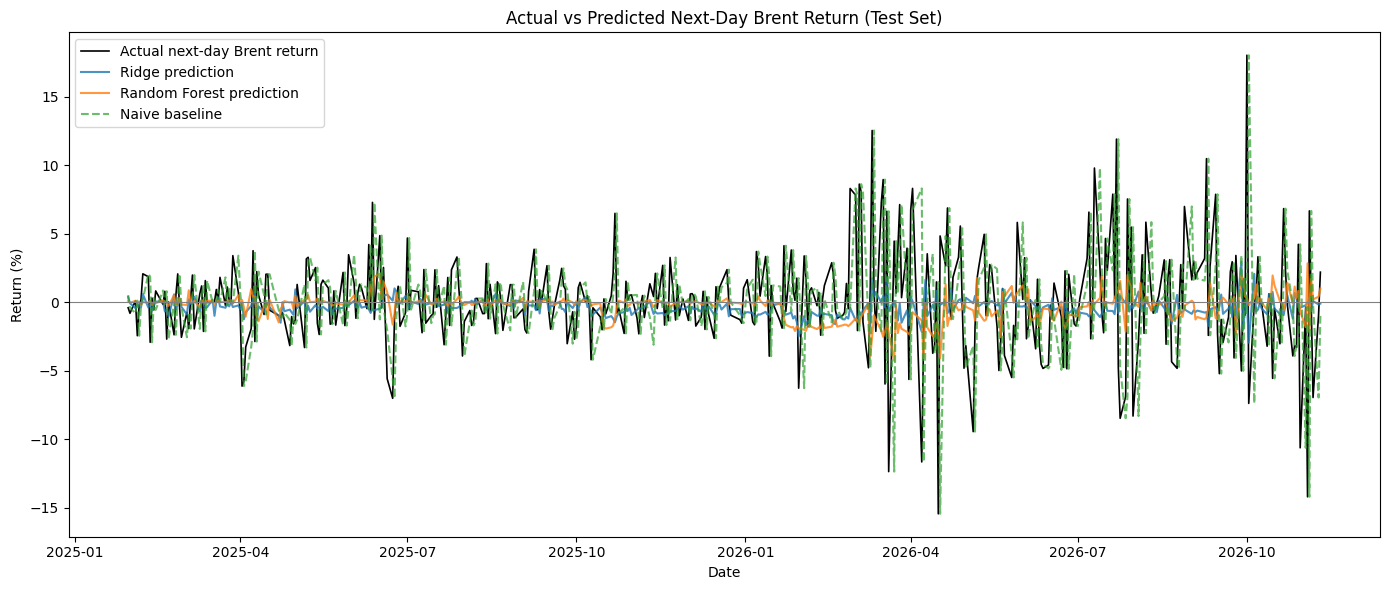


Model comparison completed.


In [ ]:
# ============================================================
# CELL 68 — MODEL COMPARISON ON THE TEST SET
# ============================================================

print("=" * 90)
print("CELL 68 — MODEL COMPARISON (TEST SET)")
print("=" * 90)

model_comparison = pd.concat(
    [baseline_results, ridge_results, forest_results],
    ignore_index=True
)

model_comparison["RMSE_Improvement_vs_Baseline_Pct"] = (
    (model_comparison["RMSE_Test"].iloc[0]
     - model_comparison["RMSE_Test"])
    / model_comparison["RMSE_Test"].iloc[0] * 100
).round(2)

print("\nFULL MODEL COMPARISON")
print("-" * 60)
display(model_comparison)

# Identify the best model by test RMSE
best_row = model_comparison.sort_values("RMSE_Test").iloc[0]
best_model_name = best_row["Model"]

print("\nBEST MODEL (lowest test RMSE):", best_model_name)

# ------------------------------------------------------------
# VISUALISATION — TEST SET: ACTUAL VS PREDICTED
# ------------------------------------------------------------

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(test_dates, y_test.to_numpy(),
         label="Actual next-day Brent return", color="black", linewidth=1.2)
plt.plot(test_dates, ridge_pred_test,
         label="Ridge prediction", alpha=0.8)
plt.plot(test_dates, forest_pred_test,
         label="Random Forest prediction", alpha=0.8)
plt.plot(test_dates, baseline_pred_test,
         label="Naive baseline", linestyle="--", alpha=0.7)

plt.axhline(0, color="grey", linewidth=0.8)
plt.title("Actual vs Predicted Next-Day Brent Return (Test Set)")
plt.xlabel("Date")
plt.ylabel("Return (%)")
plt.legend()
plt.tight_layout()
plt.show()

print("\nModel comparison completed.")
print("=" * 90)

### Extra benchmark — zero return and training-mean forecasts

**Why add this?** A persistence rule predicts the last return again, which often works poorly for noisy daily price changes. Comparing only against persistence could make an unstable model appear more useful than it is. The following cell adds two **predictable, non-test-trained** baselines: always forecast `0%`, or always forecast the **training-set mean**. Values of R² below zero indicate worse squared error than the constant mean of the **test set** (which is an evaluation reference, not a deployable forecast).

**The saved original test comparison (Cell 68):** Persistence **RMSE 5.0331**, Ridge **3.5406**, Random Forest **3.7045**; corresponding **test R² −1.0867, −0.0326 and −0.1305**. Ridge lowered RMSE by about **29.65% vs persistence**, but **neither ML model achieved a positive test R²**. No high-accuracy or profitable trading claim is warranted. The new baselines may change the practical interpretation further.

In [ ]:
# SUPPLEMENTARY AUDIT D — realistic constant baselines and preserved models
# Run after original Cell 68. No model is tuned against test data here.
import numpy as np
import pandas as pd
from IPython.display import display

zero_test_pred_audit = np.zeros(len(y_test), dtype=float)
train_mean_test_pred_audit = np.full(len(y_test), float(y_train.mean()), dtype=float)
benchmarks_audit = [
    ("Zero-return (fixed 0%)", zero_test_pred_audit),
    ("Training-mean return", train_mean_test_pred_audit),
    ("Naive persistence", baseline_pred_test),
    ("Ridge regression", ridge_pred_test),
    ("Random Forest", forest_pred_test),
]
rows_audit=[]
for label, predictions in benchmarks_audit:
    m=regression_metrics(y_test, predictions)
    rows_audit.append({"Model":label,"MAE_Test":round(m["MAE"],4),
                       "RMSE_Test":round(m["RMSE"],4), "R2_Test":round(m["R2"],4)})
strong_baseline_comparison = pd.DataFrame(rows_audit).sort_values("RMSE_Test").reset_index(drop=True)
print("Test-set benchmark results (all forecasts pre-specified or fitted without test labels):")
display(strong_baseline_comparison)
print("These are evaluation results, NOT a new test-driven hyperparameter search.")
print("Ridge test R² from preserved run:", round(regression_metrics(y_test, ridge_pred_test)["R2"],4))
strong_baseline_comparison.to_csv(
    os.path.join(PROJECT_FOLDER,"supplement_stronger_baselines_test.csv"), index=False)
print("Saved supplement_stronger_baselines_test.csv")

Test-set benchmark results (all forecasts pre-specified or fitted without test labels):


,Model,MAE_Test,RMSE_Test,R2_Test
0,Training-mean return,2.4051,3.4843,-0.0000
1,Zero-return (fixed 0%),2.4011,3.4861,-0.0011
2,Ridge regression,2.4864,3.5406,-0.0326
3,Random Forest,2.5539,3.7045,-0.1305
4,Naive persistence,3.4773,5.0331,-1.0867


These are evaluation results, NOT a new test-driven hyperparameter search.
Ridge test R² from preserved run: -0.0326
Saved supplement_stronger_baselines_test.csv


## Task 4 — Results interpretation, robustness and limitations

### Original held-out test model results

| Model | Test MAE (% points) | Test RMSE (% points) | Test R² | Interpretation |
|---|---:|---:|---:|---|
| Naive persistence | **3.4773** | **5.0331** | **−1.0867** | Poor benchmark for volatile return direction/magnitude |
| Ridge, alpha = 0.01 | **2.4864** | **3.5406** | **−0.0326** | Best original ML test RMSE, yet negative R² |
| Random Forest, tuned | **2.5539** | **3.7045** | **−0.1305** | Nonlinear complexity did not translate to better test performance |

RMSE and MAE here are **percentage points of Brent returns**, not dollars per barrel, inflation-rate points or profits. The 29.65% RMSE reduction for Ridge is **relative to persistence**, not a 29.65% forecasting accuracy rate. The two supplementary fixed/mean baselines provide a harder practical reference after re-execution.

### What the model importance actually shows

The original Random Forest's impurity-based importance ranks **WTI percentage change (~19.9%)**, **WTI price (~17.8%)**, **OVX level (~13.1%)**, **previous Brent return (~9.9%)** and **GVZ level (~9.9%)** as the top five. **OVX is not the most important variable**. Feature importance is descriptive of this fitted forest, biased in some settings by feature distributions/correlation, and **not evidence of causality, timing reliability or policy effectiveness**. It does not rescue the forest's weak R².

### Main threats to validity

- **Time dependence:** 2022 crisis effects, 2020 oil shock, calendar gaps and changes in volatility regimes limit stationarity. A single holdout is weaker than repeated rolling-origin tests.
- **Missingness/coverage:** Only ~27% of full-history dates contain all four market variables, mainly after 2015; interpretation cannot be projected to 1986.
- **High-tail risk:** Extreme oil-return events contribute disproportionately to RMSE. The source outlier audit covers all available historical Brent observations and is **not** the same sample as the 2,922 complete-case ML records.
- **Selection and diagnostic reuse:** Oil lags were explored from the same monthly data; the regression coefficients are exploratory. ML feature engineering and the model grid were not assessed with a rolling external test.
- **Boundary/timing checks:** A row-based split should be augmented with target-date purging, realistic release timing, and independent future observations before deployment.
- **Economic validity:** Even a modest numerical improvement does not quantify the benefits or costs of hedging, inventories or monetary-policy responses.

**Judgement:** The strongest deliverable is an **auditable research and monitoring pipeline**, with modest exploratory statistical insights and weak short-horizon point-prediction performance. Treat the daily forecasts as research signals, not reliable operational orders.

### Additional robustness — test errors by calendar year

A single overall average may hide poor performance in volatile periods. The code below reports actual MAE/RMSE and sample size for each **year** represented in the test holdout, separately for zero return, Ridge and Random Forest. This checks whether the aggregate ranking is stable, without tuning on the test years.

In [ ]:
# SUPPLEMENTARY AUDIT E — model error stability by test calendar year
# Run after Cell 68; the date index is from Cell 64.
import numpy as np
import pandas as pd
from IPython.display import display

stability_df = pd.DataFrame({
    "Date": pd.to_datetime(test_dates).to_numpy(),
    "Actual": np.asarray(y_test, dtype=float),
    "Ridge": np.asarray(ridge_pred_test, dtype=float),
    "Forest": np.asarray(forest_pred_test, dtype=float),
    "Zero": np.zeros(len(y_test),dtype=float),
})
stability_df["Year"] = pd.DatetimeIndex(stability_df["Date"]).year
rows=[]
for year, group in stability_df.groupby("Year"):
    for name,col in [("Zero-return","Zero"),("Ridge","Ridge"),("Random Forest","Forest")]:
        residual = group["Actual"].to_numpy() - group[col].to_numpy()
        rows.append({"Year":int(year),"Model":name,"Records":int(len(group)),
                     "MAE":round(float(np.mean(np.abs(residual))),4),
                     "RMSE":round(float(np.sqrt(np.mean(residual**2))),4)})
model_stability_by_year = pd.DataFrame(rows)
display(model_stability_by_year)
model_stability_by_year.to_csv(os.path.join(PROJECT_FOLDER,"supplement_test_errors_by_year.csv"),index=False)
print("Saved supplement_test_errors_by_year.csv")

,Year,Model,Records,MAE,RMSE
0,2025,Zero-return,226,1.4996,1.9669
1,2025,Ridge,226,1.5607,2.0628
2,2025,Random Forest,226,1.5442,1.9914
3,2026,Zero-return,213,3.3577,4.5763
4,2026,Ridge,213,3.4685,4.6176
5,2026,Random Forest,213,3.6252,4.9068


Saved supplement_test_errors_by_year.csv


## Cell 69 — Error Analysis and Feature Importance

Two diagnostic views are produced:

1. **Residual analysis** — a histogram of test-set errors (actual − predicted) for the best model, showing whether errors are centred on zero and roughly symmetric.
2. **Random Forest feature importances** — which of the 11 engineered features contribute most to next-day return predictions. These inform the Task 5 recommendations.

CELL 69 — ERROR ANALYSIS AND FEATURE IMPORTANCE


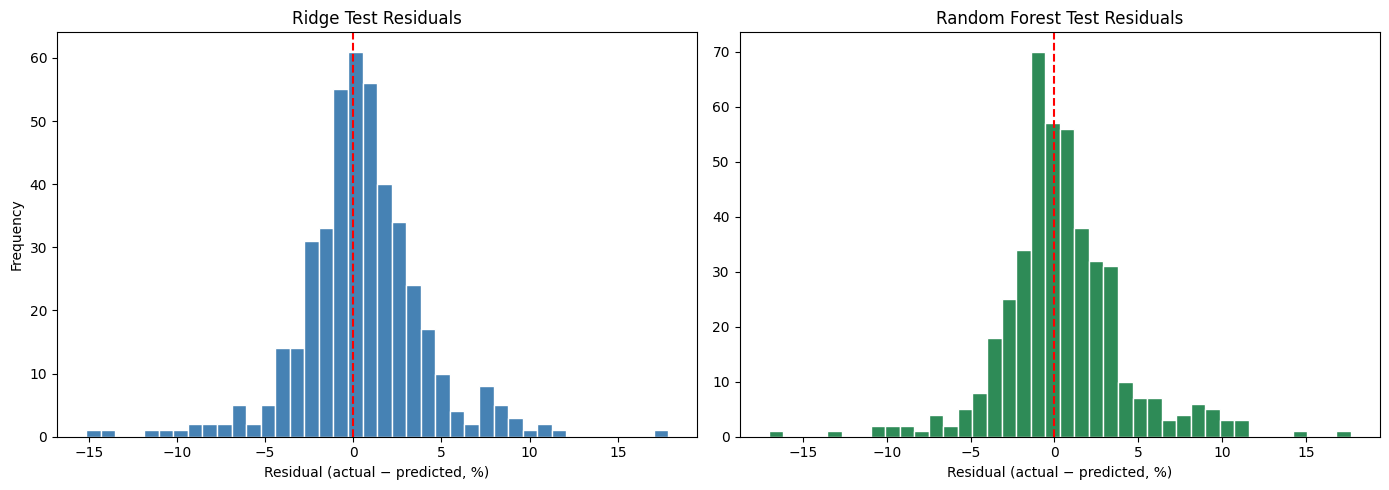


RESIDUAL STATISTICS (TEST SET)
------------------------------------------------------------


,Model,Mean_Residual,Std_Residual
0,Ridge,0.4858,3.5072
1,Random Forest,0.4275,3.6798



RANDOM FOREST FEATURE IMPORTANCE
------------------------------------------------------------


,Feature,Importance
0,DCOILWTICO_Change_Pct,0.198795
1,DCOILWTICO,0.178297
2,OVXCLS,0.131042
3,Brent_Return_Pct_Lag1,0.099054
4,GVZCLS,0.098911
5,DCOILWTICO_Change_Pct_Lag1,0.077307
6,Brent_Return_Pct,0.069972
7,OVXCLS_Change_Pct_Lag1,0.051683
8,GVZCLS_Change_Pct_Lag1,0.033193
9,OVXCLS_Change_Pct,0.032119


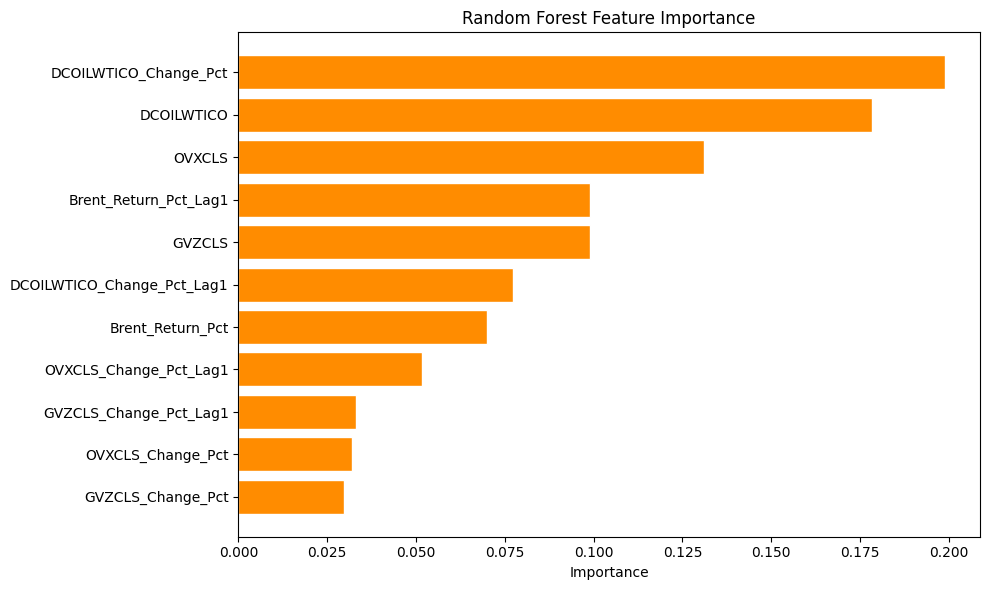

In [ ]:
# ============================================================
# CELL 69 — RESIDUALS AND FEATURE IMPORTANCE
# ============================================================

import matplotlib.pyplot as plt

print("=" * 90)
print("CELL 69 — ERROR ANALYSIS AND FEATURE IMPORTANCE")
print("=" * 90)

# Residuals for both ML models on the test set
residuals_ridge = y_test.to_numpy() - ridge_pred_test
residuals_forest = y_test.to_numpy() - forest_pred_test

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(residuals_ridge, bins=40, color="steelblue", edgecolor="white")
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Ridge Test Residuals")
axes[0].set_xlabel("Residual (actual − predicted, %)")
axes[0].set_ylabel("Frequency")

axes[1].hist(residuals_forest, bins=40, color="seagreen", edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Random Forest Test Residuals")
axes[1].set_xlabel("Residual (actual − predicted, %)")

plt.tight_layout()
plt.show()

print("\nRESIDUAL STATISTICS (TEST SET)")
print("-" * 60)

residual_summary = pd.DataFrame({
    "Model": ["Ridge", "Random Forest"],
    "Mean_Residual": [round(residuals_ridge.mean(), 4),
                      round(residuals_forest.mean(), 4)],
    "Std_Residual": [round(residuals_ridge.std(), 4),
                     round(residuals_forest.std(), 4)]
})

display(residual_summary)

# ------------------------------------------------------------
# FEATURE IMPORTANCE (RANDOM FOREST)
# ------------------------------------------------------------

importance_df = pd.DataFrame({
    "Feature": ml_feature_columns,
    "Importance": forest_model.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)

print("\nRANDOM FOREST FEATURE IMPORTANCE")
print("-" * 60)
display(importance_df)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"][::-1],
         importance_df["Importance"][::-1],
         color="darkorange", edgecolor="white")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("=" * 90)

## Cell 70 — Persist Modelling Results

The tuning tables, comparison table and feature importances are saved to the Google Drive project folder so they can be cited directly in the written report (Tables/Figures).

In [ ]:
# ============================================================
# CELL 70 — SAVE MODELLING OUTPUTS
# ============================================================

import os

print("=" * 90)
print("CELL 70 — SAVE MODELLING OUTPUTS")
print("=" * 90)

outputs = {
    "ridge_hyperparameter_tuning.csv": ridge_tuning_results,
    "forest_hyperparameter_tuning.csv": forest_tuning_results,
    "model_comparison_test_set.csv": model_comparison,
    "random_forest_feature_importance.csv": importance_df,
    "residual_summary_test_set.csv": residual_summary
}

print("\nSAVING FILES")
print("-" * 60)

for filename, dataframe in outputs.items():
    filepath = os.path.join(PROJECT_FOLDER, filename)
    dataframe.to_csv(filepath, index=False)
    status = "FOUND" if os.path.exists(filepath) else "MISSING"
    print(f"{status}: {filename}")

print("\nAll modelling outputs saved to:")
print(PROJECT_FOLDER)
print("=" * 90)

CELL 70 — SAVE MODELLING OUTPUTS

SAVING FILES
------------------------------------------------------------
FOUND: ridge_hyperparameter_tuning.csv
FOUND: forest_hyperparameter_tuning.csv
FOUND: model_comparison_test_set.csv
FOUND: random_forest_feature_importance.csv
FOUND: residual_summary_test_set.csv

All modelling outputs saved to:
/content/drive/MyDrive/Gold_Oil_Cost_of_Living


# Cell 71 — Task 5: evidence-based recommendation strategies

The following actions **follow from what the analyses can reasonably support**. The daily Brent prediction metrics are weak, so precise trading or policy-timing rules are **not** justified. The monthly models are observational and do not identify causal policy impacts.

### R1 — Implement a market-risk monitoring dashboard (**first priority**)

- **Users:** Fuel importers, logistics businesses, treasury teams, economic researchers.
- **Action:** Track Brent/WTI prices and returns, OVX/GVZ volatility, USD/LKR and domestic fuel-price revisions. Display date coverage, missingness, month-on-month changes, percentile-based *risk flags* and updated economic context rather than one-number predictions.
- **Evidence:** WTI and OVX/GVZ appear among the forest features, and the data reveal major historical return tails. This supports **monitoring relevance**, not proven forecasting leadership or a validated early-warning threshold. The forest's strongest variables are WTI percentage change and WTI level; OVX ranks third.
- **Evaluation:** Compare flagged periods with realised extreme moves and false-alert frequency over genuinely unseen dates; document timeliness and operating costs.

### R2 — Strengthen FX/fuel scenario planning (**first priority**)

- **Users:** SME importers, fuel-consuming organisations, financial planners.
- **Action:** Budget for several plausible joint USD/LKR–oil-price movements; use contingency reserves and stress tests with transparent scenarios. Update the scenarios when exchange rates or oil conditions change.
- **Evidence:** Monthly data show historically varying associations between USD/LKR changes and Sri Lankan inflation, while Brent returns can experience extreme movements. The regressions do **not** estimate an actionable optimal inventory or hedging rule.
- **Evaluation:** Measure forecast-budget deviations, liquidity buffers, scenario coverage and procurement-risk incidents.

### R3 — Use regression results for cautious policy research (**conditional priority**)

- **Users:** Economic research teams and public institutions.
- **Action:** Treat exploratory Brent lags and USD/LKR associations as hypotheses for richer inflation monitoring, with external variables (tax, administered fuel pricing, supply disruptions, wages, interest rates), alternative index definitions and newer samples.
- **Evidence:** OLS/HAC, crisis-period sensitivity and lag comparisons offer descriptive relationships. **They do not prove three-month fuel-price pass-through, justify automatic interest-rate changes or establish a causal intervention effect.**
- **Evaluation:** Refit over updated periods; compare with simpler lag specifications and out-of-sample monthly inflation benchmarks; involve policy experts before interventions.

### R4 — Educate rather than prescribe gold-based hedging (**low priority / exploratory**)

- **Users:** Households, investment educators and risk advisers.
- **Action:** Explain that nominal gold-price changes, gold-market volatility (GVZ), the exchange rate, fees and liquidity can move differently. Consider gold as a topic for diversification research, **not** as a guaranteed inflation hedge or market-timing strategy.
- **Evidence:** Gold and inflation relationships in this notebook are exploratory correlations; the daily ML model does not include gold price as a direct input and does not test portfolio returns.
- **Evaluation:** Only consider practical hedging advice after a separate LKR-denominated, after-cost, multi-period portfolio backtest with drawdown analysis.

### R5 — Keep next-observation Brent forecasts in research mode (**not deployable for trading**)

- **Users:** Quantitative analysis teams and academic supervisors.
- **Action:** Use Ridge as a research benchmark; add zero-return and training-mean comparisons, purged/rolling-origin evaluation, release-timing controls and stress-period tests. **Do not** automate orders, change daily stock levels or enter speculative positions on model output alone.
- **Evidence:** Ridge's original test RMSE beats persistence but has **R² ≈ −0.033**. Random Forest is weaker (**R² ≈ −0.131**). Such results do not validate a profitable or dependable trading signal.
- **Evaluation:** Require sustained unseen-sample improvement over zero return, low tail error, economic-value testing **after costs**, drift monitoring and independent review before any operational trial.

# Cell 72 — Task 5: assessment of effectiveness, feasibility and trade-offs

| Action | Expected usefulness (supported, not guaranteed) | Practical feasibility | Risks / safeguards | Priority |
|---|---|---|---|---|
| **R1 — risk dashboard** | **Moderate for visibility:** integrates signals and data quality; predictive lift unproved | **High:** existing public sources and pandas charts | False alerts, missing data, delayed releases; show timestamps and validate flags | **1** |
| **R2 — FX/oil scenarios** | **Moderate for preparedness:** stress tests do not require accurate one-day point forecasts | **High–medium:** scenario templates and oversight needed | Overly narrow scenarios, response costs; include adverse and favourable shocks | **1** |
| **R3 — policy research** | **Exploratory:** hypothesis generation only | **Medium:** needs independent variables and expert review | Confounding, base revisions, over-interpretation of lags; no mechanical policy rule | **2** |
| **R4 — gold education** | **Low evidence for an actionable hedge here** | **High** for education; **low** for validated strategy | Price risk, FX risk, fees/storage costs; do not claim inflation protection | **3** |
| **R5 — further ML validation** | **Research benefit:** test a weak model against realistic benchmarks | **Medium:** compute and monitoring resources required | Overfitting and false confidence; keep out of live treasury/trading decisions | **3** |

### Proposed decision framework

**Near term:** Deliver a clearly labelled dashboard, data dictionary and scenario sheet (R1–R2). **Medium term:** Improve and separately validate monthly inflation models (R3). **Only after stronger evidence:** Test any financial hedging or forecasting action (R4–R5) with real-world costs and truly unseen observations.

### How to measure whether the recommendations work

Dashboard: data freshness, coverage, signal precision and false positives. Scenario planning: budget-error distributions and cash-buffer breaches. Research: coefficient stability, predictive skill on later inflation months and robustness to alternative specifications. Investment-related use: drawdowns, turnover, costs and independent out-of-sample validation; these metrics **are not estimated in the existing notebook**.

**Limitation:** The analysis is not an impact evaluation. Therefore, the table describes **credible potential usefulness**, not measured causal effectiveness or cost savings.

# Cell 73 — Final conclusions and evidence boundary

## What this notebook has demonstrated

1. **Data collection and traceability:** Five source families—FRED market data, DataHub gold, CBSL exchange rates, DCS price-index PDFs and CPC fuel revisions—are collected or consumed with structured checks, cleaning and saved outputs.
2. **Volume and quality:** The full-history market file has **10,661 records / 5 columns** and no saved duplicate dates/rows. However, OVX/GVZ coverage and missing data shrink the four-feature overlap to **2,925** rows; after ML transformations it yields **2,922** rows and **11 input features**.
3. **EDA and monthly associations:** Multiple charts, correlation/lag checks and OLS/HAC regression diagnostics analyse Sri Lankan inflation alongside external commodity and FX conditions. Findings are **associations**, affected by crisis conditions and a small monthly sample.
4. **ML assessment:** A chronological **2,045/438/439** development/evaluation split and two ML algorithms were compared with persistence. Ridge had the lowest original test RMSE (**3.5406**) but **negative R² (~−0.033)**. Stronger constant forecasts and date-boundary diagnostics have now been added for a more critical interpretation.
5. **Responsible recommendations:** The preferred deliverables are risk monitoring and scenario planning, not promises of profitable next-day Brent forecasts or guaranteed gold hedges.

## What has *not* been established

- That changes in oil/FX/gold **cause** movements in Sri Lankan inflation.
- That three months is the unique or economically identified delay between oil and prices.
- That the 10,661 raw rows all contain the same four market inputs or constitute a distributed big-data system.
- That any daily model forecasts reliably enough to trigger inventory timing, hedging, investment trades or automatic policy changes.
- That the supplementary diagnostics have produced new verified outputs in this downloaded file. **Run those code cells in Colab** before reporting them.

## Recommended next research steps

Integrate verified release-time information, perform **purged rolling-origin** tests, compare against zero-return and training-mean baselines, investigate performance by volatility regime, add a genuinely external post-sample holdout, and evaluate a separate monthly inflation forecasting model if that becomes a goal. Audit changes to official source PDFs and document inflation base handling. Record exact CSV/PDF versions and access dates.

The final original cell below checks the existence of the listed exported files; **additional** `supplement_*.csv` outputs are created by new audit cells after those cells are actually run.

In [ ]:
# ============================================================
# CELL 73 — FINAL OUTPUT FILE VERIFICATION
# ============================================================

import os
import pandas as pd

print("=" * 90)
print("CELL 73 — FINAL OUTPUT FILE VERIFICATION")
print("=" * 90)

expected_outputs = [
    "international_market_data_full_history.csv",
    "international_market_data.csv",
    "gold_monthly.csv",
    "gold_monthly_cleaned.csv",
    "usd_lkr_daily_cleaned.csv",
    "usd_lkr_date_corrections.csv",
    "ccpi_food_nonfood_base2021_monthly.csv",
    "ridge_hyperparameter_tuning.csv",
    "forest_hyperparameter_tuning.csv",
    "model_comparison_test_set.csv",
    "random_forest_feature_importance.csv",
    "residual_summary_test_set.csv"
]

verification_rows = []

for filename in expected_outputs:
    filepath = os.path.join(PROJECT_FOLDER, filename)
    exists = os.path.exists(filepath)

    row = {"File": filename, "Status": "FOUND" if exists else "MISSING"}

    if exists and filename.endswith(".csv"):
        try:
            row["Rows"] = len(pd.read_csv(filepath))
        except Exception:
            row["Rows"] = "unreadable"

    verification_rows.append(row)

verification_df = pd.DataFrame(verification_rows)

display(verification_df)

assert (verification_df["Status"] == "FOUND").all(), \
    "Some output files are missing — re-run the relevant cells."

print("\nAll output files verified successfully.")
print("Project folder:", PROJECT_FOLDER)
print("=" * 90)

CELL 73 — FINAL OUTPUT FILE VERIFICATION


,File,Status,Rows
0,international_market_data_full_history.csv,FOUND,10661
1,international_market_data.csv,FOUND,3096
2,gold_monthly.csv,FOUND,2326
3,gold_monthly_cleaned.csv,FOUND,142
4,usd_lkr_daily_cleaned.csv,FOUND,2850
5,usd_lkr_date_corrections.csv,FOUND,2
6,ccpi_food_nonfood_base2021_monthly.csv,FOUND,58
7,ridge_hyperparameter_tuning.csv,FOUND,5
8,forest_hyperparameter_tuning.csv,FOUND,4
9,model_comparison_test_set.csv,FOUND,3



All output files verified successfully.
Project folder: /content/drive/MyDrive/Gold_Oil_Cost_of_Living


# Appendix — Report transfer guide, sources and final checks

## A. Suggested written report layout

| Report section | Evidence from notebook | Critical statement to retain |
|---|---|---|
| Introduction / problem (Task 1) | Task 1 section, stakeholders and KPIs | Two related but different analysis goals; daily ML does not predict Sri Lankan inflation |
| Data provenance (Task 2) | Original Cells 1–43, 60–63; data-quality audit A | Explain full-history **10,661** vs four-series complete **2,925** vs engineered **2,922** |
| Data processing (Task 2) | FRED joins, date correction logs, PDF parsing, derived features | Describe missing data, date checks, numerical scaling, re-basing and outlier retention |
| EDA (Task 3) | Cells 44–47, 55–59, 63, quality chart | Caption at least five visuals and interpret what is *not* implied |
| Monthly modelling (Task 4A) | Cells 48–54, 56–59 | HAC is for inference robustness; report sample sizes, post-2022 sensitivity and no causality |
| Daily predictive modelling (Task 4B) | Cells 62–70, supplements B–E | Benchmark MAE/RMSE/R²; Ridge lower RMSE than persistence but **test R² negative** |
| Recommendations (Task 5) | Revised Cells 71–72 | Prioritise monitoring and risk scenarios; withhold automated predictive actions |
| Discussion, limitations, future research | Cell 73, this appendix | Explicitly address coverage, tail events, 2022 influence and split-boundary sensitivity |

### Key numeric results to transfer (from the *original* saved run)

- Whole-market historical table: **10,661 rows**; 4 numerical indicators + Date; full range **1986-01-02 to 2026-11-12**.
- Missing percentages: **OVX 71.99%**, **GVZ 56.44%**, **Brent 14.38%**, **WTI 10.49%**.
- All-four-feature overlap: **2,925 records**; ML records **2,922**; training **2,045**; validation **438**; test **439**.
- Monthly integrated Sri Lankan inflation/market sample: **57 months, January 2022–September 2026** (56 sequential month-on-month changes).
- Brent historical return-outlier investigation: **9,127 next-observation targets** across available Brent history; **453 absolute returns >5%**, **65 >10%**, **8 >20%**. These are **not** counts for the final ML subset.
- ML test results (MAE, RMSE, R²): **Persistence (3.4773, 5.0331, −1.0867)**; **Ridge (2.4864, 3.5406, −0.0326)**; **Forest (2.5539, 3.7045, −0.1305)**.
- Importance: **WTI change 19.88%**, **WTI level 17.83%**, **OVX level 13.10%** for the saved Random Forest, not causal weights.

**Report figure/table transfer checklist:** Retrieve source figures from the original chart cells, note each figure's observation period and whether it depicts index *levels* or percentage *changes*, include regression output tables with HAC errors, distinguish validation from test scores, and add any new diagnostic outputs only after you have run them.

## B. Original source bibliography (source paths identified in notebook code)

1. Federal Reserve Bank of St. Louis, FRED, *OVXCLS*, CBOE Crude Oil ETF Volatility Index: https://fred.stlouisfed.org/series/OVXCLS
2. FRED, *GVZCLS*, CBOE Gold ETF Volatility Index: https://fred.stlouisfed.org/series/GVZCLS
3. FRED, *DCOILBRENTEU*, Crude Oil Prices: Brent — Europe: https://fred.stlouisfed.org/series/DCOILBRENTEU
4. FRED, *DCOILWTICO*, Crude Oil Prices: West Texas Intermediate: https://fred.stlouisfed.org/series/DCOILWTICO
5. DataHub Core, *Gold Prices* (`monthly-processed.csv` in notebook): https://datahub.io/core/gold-prices
6. Central Bank of Sri Lanka, historical buying/selling exchange-rate workbook (`IF_Buying_Selling_Exchange_Rates.xlsx`), supplied as an input. Add the **actual file landing-page URL, edition and access date** from your download records.
7. Department of Census and Statistics, Sri Lanka, *CCPI Food and Non-Food Inflation (2021 base)*: https://www.statistics.gov.lk/Resource/en/InflationAndPrices/CCPI/CCPI_2021_InflationFoodAndNonFood.pdf
8. DCS, *CCPI Movements (2013 base)*: https://www.statistics.gov.lk/Resource/en/InflationAndPrices/CCPI/MOVEMENTS_of_CCPI_with_MV_Base2013-100.pdf
9. DCS, *NCPI Movements (2013 base)*: https://www.statistics.gov.lk/Resource/en/InflationAndPrices/NCPI/MovementsOf-NCPI-2013.pdf
10. DCS, *NCPI Movements (2021 base)*: https://www.statistics.gov.lk/Resource/en/InflationAndPrices/NCPI/MovementsOf-NCPI.pdf
11. Ceylon Petroleum Corporation, public historical-prices API: https://api.ceypetco.gov.lk/api/admin/historical-prices/active
12. Software and methodological documentation: pandas (https://pandas.pydata.org/), statsmodels (https://www.statsmodels.org/), scikit-learn (https://scikit-learn.org/stable/).

**Bibliography accuracy note:** URLs above are copied from, or traceable to, the original notebook's source identifiers; current availability was **not** live-verified for this edition. Add exact titles/versions, access dates and attribution according to your institution's required style. Do not invent a DOI or access date. Distinguish the *data publisher* from the *site distributing a data extract*.

## C. Submission readiness checklist

- [ ] Colab connected, required CSV/XLSX files present, PDF/API downloads checked and full notebook run top to bottom.
- [ ] No unexpected errors; official-source parsing and date range assumptions checked against current files.
- [ ] Original outputs and all supplementary diagnostic cells re-executed; charts and result CSVs saved.
- [ ] Raw vs usable model row counts, feature definitions, dates and units consistently stated.
- [ ] At least five EDA plots explained, not merely pasted.
- [ ] OLS inference discussed as exploratory association; lag selection and 2022 sensitivity documented.
- [ ] Test RMSE, MAE and R² accurately reported; zero-return baseline and time-boundary caveats included.
- [ ] Recommendations limited to evidence; no guaranteed hedge or trading claim.
- [ ] References completed with exact edition and actual access date; institution's academic-integrity rules followed.

**Recommended next step:** Run the notebook in Colab and upload that **newly executed** `.ipynb` here for a final output-by-output review before writing your report.